<style>
.jp-RenderedHTMLCommon h1,.jp-RenderedHTMLCommon h2,.text_cell_render h1,.text_cell_render h2 {
font-family: "Times New Roman", "Liberation Serif", "Nimbus Roman", Georgia, serif;
font-weight: bold; color: black; padding-bottom: .24em; border-bottom: 0;
}
.jp-RenderedHTMLCommon hr,.text_cell_render hr {border: 0; border-top: 1px solid black;}
.jp-RenderedHTMLCommon,.text_cell_render {color: black;}
.jp-RenderedHTMLCommon nav,.text_cell_render nav {margin: 1em 0;}
.jp-RenderedHTMLCommon a,.text_cell_render a {color: inherit; text-decoration: underline;}
</style>

<a id="carnet"></a>

# Parallel edit distance from a single pair to genome collections

<hr>

La distance d’édition globale est le nombre minimal d’insertions, de suppressions et de substitutions qui transforme une chaîne en une autre. La programmation dynamique classique calcule jusqu’à un billion de cases pour deux séquences d’un million de bases. NvPD s’appuie sur la dernière occurrence d’un symbole pour distribuer les colonnes d’une ligne entre travailleurs. Ce carnet étudie dans quelles conditions ce parallélisme réduit le temps d’un alignement exact et comment il se compare à la distribution de paires entières.

Les essais distinguent la géométrie des matrices, le coût optimal et l’architecture matérielle. Un processeur EPYC et un accélérateur GH200 de ROMEO assurent les comparaisons de calcul. Un Apple M1 Pro fournit un contrôle de justesse sur un autre jeu d’instructions. Slurm réserve les cœurs et les accélérateurs. OpenMP partage la mémoire d’un processus entre fils et CUDA distribue le calcul entre blocs sur GPU. Les comparaisons humaines vont de fenêtres homologues de deux assemblages du chromosome 21 à 18 chromosomes complets de CHM13, dont le chromosome 1 de 248 Mnt. Des mesures distinctes portent sur la lecture du FASTA, le score et le chemin d’édition. Sur une collection, le temps dépend aussi de la répartition des paires entre rangs MPI. L’analyse des arbres examine enfin comment une erreur de distance se propage jusqu’aux groupes reconstruits. [Slurm, vue d’ensemble](https://slurm.schedmd.com/overview.html) · [OpenMP, spécifications](https://www.openmp.org/specifications/) · [CUDA, guide de programmation](https://docs.nvidia.com/cuda/cuda-programming-guide/)

Pour une série de $n$ unités expérimentales, le centre estimé est la moyenne $\bar{x}=\sum_i x_i/n$. Sur les diagrammes à intervalles, le trait épais donne l’écart-type observé $s=\sqrt{\sum_i(x_i-\bar{x})^2/(n-1)}$ de chaque côté de la moyenne. Le trait fin donne l’intervalle de confiance (IC) bilatéral de Student à 95 %, $\bar{x}\pm t_{0.975,n-1}s/\sqrt{n}$. L’intervalle suppose des unités indépendantes sous le protocole décrit et une moyenne approximativement normale. Les petits effectifs rendent cette approximation sensible aux valeurs extrêmes. L’IC porte sur ce matériel et ces conditions. Les rapports appariés sont calculés avant la moyenne. Les répétitions dans un seul processus donnent au plus une dispersion conditionnelle. Les décomptes exhaustifs, les bornes et les mesures uniques gardent leur valeur sans IC. [NIST, intervalle de confiance d’une moyenne](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm)

<nav aria-label="Sommaire"><strong>Sommaire</strong><p>Calcul sur CPU. <a href="#distance-globale">Coût du calcul de la distance globale</a>, <a href="#echelle-openmp">Passage à l’échelle sur un processeur</a>, <a href="#openmp-long">Anti-diagonales et lignes de grande largeur</a>, <a href="#vectorisation">Vectorisation de la récurrence de dernière occurrence</a>, <a href="#geometrie-bande">Géométrie des passages en bande</a>, <a href="#nvpd-adaptatif">Récurrence exacte à largeur adaptative</a>, <a href="#hierarchie-memoire">Occupation mémoire et défauts du cache de données</a>, <a href="#lecture-fasta">Décodage de fichiers FASTA de chromosomes entiers</a>, <a href="#trace-lineaire">Reconstruction de l’alignement en espace linéaire</a>, <a href="#instructions">Instructions et prédictions de branchement</a>.</p><p>Calcul sur GPU. <a href="#tuiles-cuda">Regroupement des lignes en tuiles CUDA</a>, <a href="#trace-cuda">Chronologie des appels hôte et des noyaux CUDA</a>, <a href="#localite-gpu">Localité des lectures en mémoire globale</a>, <a href="#modele-gh200">Débits entiers et modèle mémoire du GH200</a>, <a href="#front-gpu">Calcul par fronts de coût sur accélérateur</a>, <a href="#allocations-cuda">Réutilisation des tampons entre alignements</a>.</p><p>Portage et distribution. <a href="#kokkos">Portabilité de la récurrence avec Kokkos</a>, <a href="#kokkos-chromosome">Portabilité de NvPD sur deux régions homologues</a>, <a href="#mpi-fort">Passage à l’échelle fort entre nœuds</a>, <a href="#collective-mpi">Temps passé dans les échanges collectifs</a>, <a href="#mpi-faible">Passage à l’échelle faible entre nœuds</a>, <a href="#distribution-fenetres-humaines">Distribution de fenêtres chromosomiques</a>, <a href="#ordonnancement">Ordonnancement de paires de longueurs hétérogènes</a>, <a href="#carte-paires">Géométrie des partitions de Hilbert</a>, <a href="#concentration-rangs">Concentration du travail entre rangs</a>, <a href="#travailleurs-mpi">Exécution des paires avec Kokkos</a>.</p><p>Génomes et choix de la méthode. <a href="#chromosome">Distances entre assemblages d’un chromosome humain</a>, <a href="#assemblages-entiers">Comparaison de chromosomes humains entiers</a>, <a href="#cohorte-chromosomique">Distances sur un panel de chromosomes entiers</a>, <a href="#paysage-chromosomique">Localisation des révisions de l’assemblage humain</a>, <a href="#methodes-distance">Méthodes exactes sensibles à la distance</a>, <a href="#fronts-bidirectionnels">Reconstruction par fronts bidirectionnels</a>, <a href="#bras-chromosome">Alignement de fenêtres emboîtées du bras long</a>, <a href="#trace-chromosomes">Reconstruction parallèle du chemin sur chromosomes entiers</a>, <a href="#certification-quicked">Justesse et coût de la certification de QuickEd</a>, <a href="#phylogenie">Structure des distances entre génomes de phages</a>, <a href="#groupes-surveillance">Concordance avec les groupes de surveillance</a>, <a href="#sensibilite-arbres">Sensibilité de la topologie à la largeur de bande</a>, <a href="#synthese">Conclusion et critères de choix</a>.</p></nav>

L’exécution lit les CSV du dépôt et exporte les PNG dans [figures/](../figures/). Avec l’environnement décrit dans [notebooks/requirements.txt](requirements.txt), la commande est `python -m jupyter nbconvert --to notebook --execute --inplace CHEMIN/notebooks/profil_nvpd.ipynb`. CHEMIN désigne la racine du dépôt. Les effectifs, moyennes, écarts-types et bornes représentés sont disponibles dans le [tableau des statistiques](../figures/statistics.csv).

In [1]:
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from io import BytesIO
from IPython.display import Image, display

# nbconvert positionne le noyau dans le dossier du carnet, même si son appel vient d'ailleurs.
# Les interfaces qui exécutent le noyau hors du dépôt peuvent fournir CHPS_PROJECT_ROOT.
nv_anchor_paths = [Path.cwd()]
for nv_path_hint in [
    os.environ.get("CHPS_PROJECT_ROOT"),
    os.environ.get("JPY_SESSION_NAME"),
    globals().get("__vsc_ipynb_file__"),
]:
    if nv_path_hint:
        nv_anchor_paths.append(Path(nv_path_hint).expanduser().resolve())
nv_roots = (candidate for start in nv_anchor_paths for candidate in (start, *start.parents))
ROOT = next(
    (
        candidate
        for candidate in nv_roots
        if (candidate / "python/ct_plot.py").is_file() and (candidate / "CMakeLists.txt").is_file()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Indiquer la racine du projet dans CHPS_PROJECT_ROOT.")
sys.path.insert(0, str(ROOT / "python"))
import ct_plot
from ct_plot import COLORS, INK, PAPER, GUIDE, column_titles, label_panels, legend_above

ct_plot.use_style()
RES = ROOT / "results"
PROF = RES / "profile"
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
pd.options.display.float_format = "{:.3g}".format


def nv_save(figure, name, *, vector=False, alt=None):
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png")
        png = buffer.getvalue()
    with ct_plot.atomic_png(FIG / (name + ".png")) as stream:
        stream.write(png)
    axes = [" et ".join(label for label in (axis.get_xlabel(), axis.get_ylabel()) if label)
            for axis in figure.axes]
    description = name.split("/")[-1].replace("_", " ") + ". " + ". ".join(filter(None, axes))
    description = alt or description
    if vector:
        with ct_plot.atomic_figure(FIG / (name + ".pdf")) as stream, plt.rc_context({"pdf.fonttype": 42}):
            figure.savefig(stream, format="pdf", metadata={"Title": description, "CreationDate": None})
    display(Image(data=png), metadata={"image/png": {"alt": description}})
    plt.close(figure)


def nv_csv(path):
    if not Path(path).is_file():
        raise FileNotFoundError(f"Table de mesure requise absente : {path}")
    return pd.read_csv(path, keep_default_na=False)


from bench_stats import Measurements
from ct_plot import estimate, join, value_label, comparison, category_rows

nv_stats = Measurements()


def nv_plot(
    axis,
    observations,
    cases,
    positions,
    figure,
    metric,
    series,
    unit,
    color,
    marker="o",
    *,
    joined=False,
    horizontal=False,
    independent=True,
    label=None,
):
    """Une série indexée par cas contient une valeur par unité expérimentale."""
    coordinates, centers = [], []
    for case, position in zip(cases, positions, strict=True):
        values = observations[observations.index == case].to_numpy()
        if not len(values):
            continue
        entry = nv_stats.add(figure, metric, series, case, values, unit, independent=independent)
        estimate(
            axis, position, entry, color, marker=marker, label=label or series, horizontal=horizontal
        )
        coordinates.append(position)
        centers.append(entry["mean"])
    if joined:
        join(axis, coordinates, centers, color, horizontal=horizontal)
    return centers

<a id="distance-globale"></a>

## Coût du calcul de la distance globale

<hr>

La figure 1 compare les durées des alignements sur les mêmes paires, d’abord selon leur longueur puis selon le taux d’erreur.

Pour une paire de longueurs $m,n$, le débit dense vaut $mn/(10^9 T)$ en GCUPS. Ce calcul suppose que la méthode visite toutes les cases. Edlib traite plusieurs positions par mot machine et WFA2-lib explore les fronts de coût.

L’alignement est global. Une insertion, une suppression ou une substitution coûte une unité. Deux symboles IUPAC doivent être identiques pour donner une correspondance. Sur CPU, edlib, de Šošić et Šikić, calcule la distance par opérations bit-parallèles. WFA2-lib, de Marco-Sola et coll., avance par fronts de coût pour calculer ici la distance d’édition globale. Dans cette première comparaison, la série GPU exécute NvPD. L’implémentation eWFA-GPU de l’article fourni fait l’objet de l’expérience sur les fronts de coût. [NvPD, Sadiq et coll.](https://doi.org/10.1007/s10586-019-02962-w) · [edlib, Šošić et Šikić](https://doi.org/10.1093/bioinformatics/btw753) · [WFA, Marco-Sola et coll.](https://doi.org/10.1093/bioinformatics/btaa777) · [eWFA-GPU, Aguado-Puig et coll.](https://doi.org/10.1109/ACCESS.2022.3182714)

Le panneau a) provient des mesures répétées après chauffe. Pour le panneau b), la première campagne a produit 60 paires synthétiques avec une graine maîtresse de 2026. À un million de bases, la programmation dynamique dense sur CPU traite une paire par taux. Les deux bibliothèques et le GPU en traitent cinq. Le temps par paire commence après la lecture FASTA et couvre l’allocation ainsi que le retour du coût. Pour CUDA, le premier appel inclut l’initialisation du contexte.

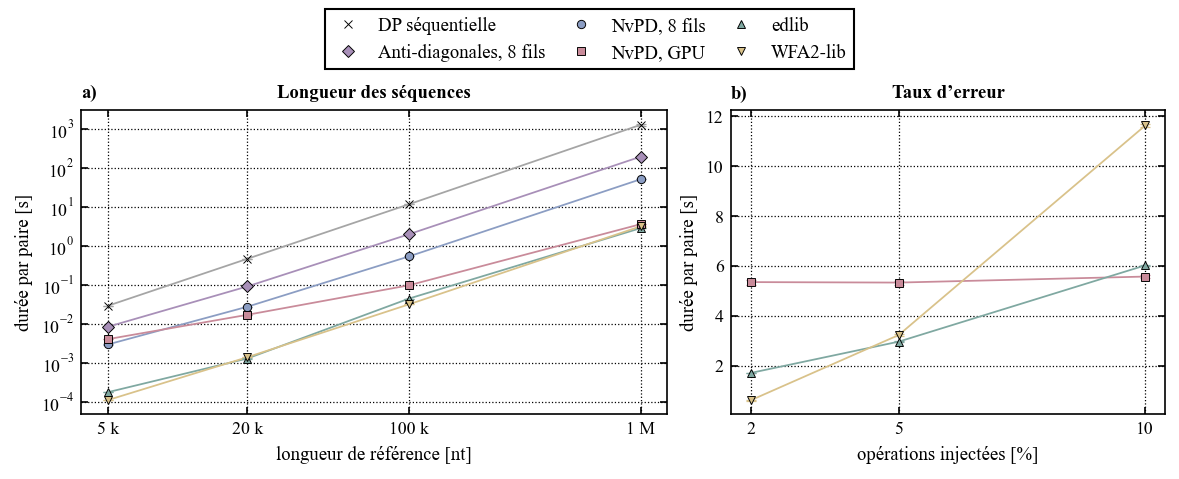

In [2]:
# Durée selon la longueur et le taux d'erreur (results/romeo/{cpu,gpu}-*.csv).
nv_runs = pd.concat(
    [nv_csv(path) for path in sorted((RES / "romeo").glob("*-*.csv"))], ignore_index=True
)
assert nv_runs.status.eq("ok").all() and (nv_runs.seconds > 0).all()
assert nv_runs.groupby("input_sha256").distance.nunique().eq(1).all()
nv_methods = {
    "seq": ("DP séquentielle", COLORS[4], "x"),
    "diagonal": ("Anti-diagonales, 8 fils", COLORS[5], "D"),
    "nvpd-omp": ("NvPD, 8 fils", COLORS[0], "o"),
    "nvpd-cuda": ("NvPD, GPU", COLORS[1], "s"),
    "edlib": ("edlib", COLORS[2], "^"),
    "wfa2": ("WFA2-lib", COLORS[3], "v"),
}
nv_selected = nv_runs[nv_runs.threads.eq(8) | ~nv_runs.algorithm.isin(["diagonal", "nvpd-omp"])]
# Une seule valeur par paire et méthode, même quand une campagne répète sa mesure.
nv_pair = nv_selected.groupby(
    ["length", "rate", "rep", "algorithm", "input_sha256"], as_index=False
).agg(seconds=("seconds", "mean"), distance=("distance", "first"))
nv_fig, nv_ax = plt.subplots(1, 2, figsize=(7.75, 3.1), width_ratios=(1.35, 1))
nv_sizes = [5_000, 20_000, 100_000, 1_000_000]
nv_rates = [0.02, 0.05, 0.10]
nv_epyc = nv_csv(RES / "repeated/epyc/trials.csv")
nv_grace = nv_csv(RES / "repeated/gh200/trials.csv")
nv_hot = pd.concat(
    [nv_epyc[nv_epyc.warmup.eq(0)], nv_grace[nv_grace.warmup.eq(0) & nv_grace.algorithm.eq("nvpd-cuda")]]
)
nv_dense = nv_csv(RES / "repeated/epyc-scalar/trials.csv")
assert nv_dense.algorithm.eq("seq").all()
nv_hot = pd.concat([nv_hot, nv_dense[nv_dense.warmup.eq(0)]], ignore_index=True)
nv_hot = nv_hot[nv_hot.case.str.startswith("syn-")].copy()
nv_hot["length"] = nv_hot.case.str.split("-").str[1].astype(int)
nv_hot["rate"] = nv_hot.case.str.rsplit("-", n=1).str[-1].astype(float)
assert nv_hot.groupby("case").input_sha256.nunique().eq(1).all()
assert nv_hot.groupby("case").distance.nunique().eq(1).all()
for nv_alg, (nv_name, nv_color, nv_marker) in nv_methods.items():
    nv_key = "nvpd-simd" if nv_alg == "nvpd-omp" else nv_alg
    nv_size = nv_hot[nv_hot.algorithm.eq(nv_key) & nv_hot.rate.eq(0.05)].set_index("length").seconds
    nv_counts = nv_size.groupby(level=0).size().reindex(nv_sizes)
    if nv_counts.tolist() != [9, 9, 5, 5]:
        raise ValueError(f"Effectif incomplet pour {nv_name} à 5 % : {nv_counts.to_dict()}")
    nv_plot(
        nv_ax[0],
        nv_size,
        nv_sizes,
        nv_sizes,
        1,
        "seconds_5pct",
        nv_key,
        "fresh_warmed_process",
        nv_color,
        nv_marker,
        joined=True,
        label=nv_name,
    )
    if nv_alg in ("nvpd-cuda", "edlib", "wfa2"):
        nv_err = (
            nv_pair[nv_pair.algorithm.eq(nv_alg) & nv_pair.length.eq(1_000_000)]
            .set_index("rate")
            .seconds
        )
        nv_plot(
            nv_ax[1],
            nv_err,
            nv_rates,
            [2, 5, 10],
            1,
            "seconds_1M",
            nv_alg,
            "independent_fasta_pair",
            nv_color,
            nv_marker,
            joined=True,
            label=nv_name,
        )
nv_ax[0].set(
    xscale="log", yscale="log", xlabel="longueur de référence [nt]", ylabel="durée par paire [s]"
)
nv_ax[0].set_xticks(nv_sizes, ["5 k", "20 k", "100 k", "1 M"])
nv_ax[1].set(xlabel="opérations injectées [%]", ylabel="durée par paire [s]")
nv_ax[1].set_xticks([2, 5, 10])
# Le débit dense utilise les dimensions effectives et le temps de chaque processus.
nv_dense_gpu = nv_csv(RES / "repeated/gh200/trials.csv")
nv_dense_gpu = nv_dense_gpu[
    nv_dense_gpu.warmup.eq(0)
    & nv_dense_gpu.algorithm.eq("nvpd-cuda")
    & nv_dense_gpu.case.str.startswith("syn-1000000-")
]
for nv_case, nv_gpu_case in nv_dense_gpu.groupby("case"):
    nv_gcups = nv_gpu_case.m * nv_gpu_case.n / (1e9 * nv_gpu_case.seconds)
    nv_stats.add(1, "gcups", "nvpd-cuda", nv_case, nv_gcups, "fresh_warmed_process")
label_panels(nv_ax)
column_titles(nv_ax, ("Longueur des séquences", "Taux d’erreur"))
legend_above(nv_fig, nv_ax, ncol=3)
nv_save(nv_fig, "comparison/temps_distance")

*Figure 1.* Le panneau a) mesure le deuxième appel de processus indépendants sur la première paire de chaque longueur à 5 %, après une chauffe identique. Les méthodes CPU tournent sur EPYC, CUDA sur GH200. À un million de bases, les cinq processus scalaires par taux tournent simultanément sur des cœurs distincts d’une autre allocation EPYC. Leur dispersion inclut les différences entre cœurs à cet instant, sans appariement aux autres méthodes. Le panneau b) décrit une autre campagne, menée à froid sur cinq paires différentes par taux. Son IC traduit la variabilité entre entrées.

<sub>Code : [scripts/datasets/synthetic.py](../scripts/datasets/synthetic.py), [src/libraries/baselines.cpp](../src/libraries/baselines.cpp), [bench/campaign/run.py](../bench/campaign/run.py), [results/romeo](../results/romeo/), [results/repeated/epyc/trials.csv](../results/repeated/epyc/trials.csv), [results/repeated/gh200/trials.csv](../results/repeated/gh200/trials.csv), [results/repeated/epyc-scalar/trials.csv](../results/repeated/epyc-scalar/trials.csv), [results/repeated/epyc-scalar/placement.csv](../results/repeated/epyc-scalar/placement.csv).</sub>

Les méthodes denses calculent toutes les cases, y compris à faible distance. Les méthodes par bits et par fronts visitent ou représentent moins d’états. L’écart se voit sur les cinq paires d’un million de bases. À froid à 2 %, WFA2-lib demande en moyenne 0,610 (écart-type 0,009, IC 95 % de 0,599 à 0,621) s. Son coût augmente avec le taux injecté. Sur la première paire à 5 % après chauffe, NvPD CUDA traite 273,2 (écart-type 1,1, IC 95 % de 271,9 à 274,5) milliards de cases par seconde. Le calcul divise le nombre réel de cases par le temps de chaque processus.

Sur la première paire à 5 %, le calcul scalaire prend 1291,9 s en moyenne. Les demi-largeurs relatives des IC du scalaire vont de 7,7 à 8,1 % selon le taux. Les deux groupes de cœurs occupés simultanément ont des durées distinctes et leurs proportions varient avec le taux. La version NvPD vectorisée à huit cœurs prend 51,9 s sur cette entrée dans une réservation distincte.

Le coût des méthodes denses conduit à examiner la répartition des colonnes entre les cœurs.

<p><strong><u>Synthèse.</u></strong> À 1 Mnt, la méthode la plus rapide sur ces machines dépend du taux injecté.<br>La programmation dynamique dense offre une comparaison à volume de travail connu.</p>

<a id="echelle-openmp"></a>

## Passage à l’échelle sur un processeur

<hr>

La figure 2 suit l’évolution du temps lorsque les fils OpenMP se partagent les colonnes d’une matrice.

Soit $T_p(m,n)$ le temps d’un essai de NvPD sur $p$ cœurs. À taille fixe, l’accélération vaut $S_p=T_1(m,n)/T_p(m,n)$, l’efficacité $S_p/p$. À travail fixe par cœur, le calcul garde 4 096 lignes et multiplie le nombre de colonnes par $p$. L’efficacité faible vaut alors $T_1(4096,4096)/T_p(4096,4096p)$. Les deux expériences gardent le même nombre de barrières de lignes lorsque $p$ varie, mais seule la seconde conserve le nombre de cases à traiter par cœur. [Cornell, mesures de passage à l’échelle](https://cvw.cac.cornell.edu/parallel/efficiency/scaling) · [Amdahl, 1967](https://doi.org/10.1145/1465482.1465560)

Les essais emploient la même variante à l’intérieur de chaque courbe, des fils attachés aux cœurs avec OpenMP et une phase de chauffe. Chaque processus vérifie sa distance et l’empreinte de ses entrées contre la référence avant la mise en commun des résultats. V1 utilise un index d’entiers sur quatre octets et une boucle vectorisable. V2 essaie de représenter les écarts de l’index sur un octet.

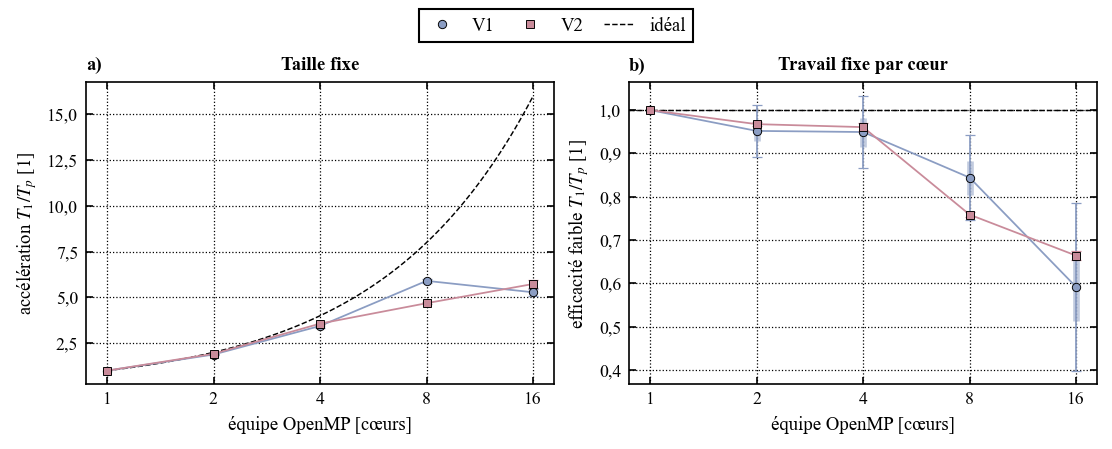

In [3]:
# Taille fixe et travail fixe par cœur, pour V1 et V2 (results/profile/cpu/scaling.csv).
sc_raw = nv_csv(PROF / "cpu/scaling.csv")
assert sc_raw.distance.eq(sc_raw.reference_distance).all()
sc_p = [1, 2, 4, 8, 16]
assert set(sc_raw.threads) == set(sc_p)
assert sc_raw.groupby(["variant", "study", "threads"]).trial.nunique().eq(3).all()
sc_fig, sc_ax = plt.subplots(1, 2, figsize=(7.3, 2.9))
for sc_i, sc_variant in enumerate(["v1", "v2"]):
    for sc_j, sc_study in enumerate(["strong", "weak"]):
        sc_table = sc_raw[sc_raw.variant.eq(sc_variant) & sc_raw.study.eq(sc_study)]
        sc_blocks = sc_table.pivot(index="trial", columns="threads", values="seconds")
        sc_relative = sc_blocks.rdiv(sc_blocks[1], axis=0)
        sc_values = sc_relative.rename_axis(columns="threads").stack().droplevel("trial")
        nv_plot(
            sc_ax[sc_j],
            sc_values,
            sc_p,
            sc_p,
            2,
            sc_study,
            sc_variant,
            "randomized_block",
            COLORS[sc_i],
            marker="os"[sc_i],
            joined=True,
            label=sc_variant.upper(),
        )
sc_ideal = np.geomspace(sc_p[0], sc_p[-1], 96)
sc_ax[0].plot(sc_ideal, sc_ideal, **GUIDE, label="idéal")
sc_ax[0].set(xlabel="équipe OpenMP [cœurs]", ylabel=r"accélération $T_1/T_p$ [1]")
sc_ax[1].axhline(1, **GUIDE, label="idéal")
sc_ax[1].set(xlabel="équipe OpenMP [cœurs]", ylabel=r"efficacité faible $T_1/T_p$ [1]")
for sc_axis in sc_ax:
    sc_axis.set_xscale("log", base=2)
    sc_axis.set_xticks(sc_p, [str(p) for p in sc_p])
label_panels(sc_ax)
column_titles(sc_ax, ("Taille fixe", "Travail fixe par cœur"))
legend_above(sc_fig, sc_ax, ncol=3)
nv_save(sc_fig, "cpu/echelle_cpu")

*Figure 2.* Chaque série utilise les rapports entre processus du même bloc aléatoire. Trois blocs ont chacun une chauffe complète par configuration. La diagonale indique l’accélération idéale à taille fixe. La droite horizontale indique l’efficacité idéale à charge fixe par cœur.

<sub>Code : [bench/cpu/openmp/profile_cpu_driver.cpp](../bench/cpu/openmp/profile_cpu_driver.cpp), [bench/cpu/openmp/profile_cpu.py](../bench/cpu/openmp/profile_cpu.py), [bench/cpu/openmp/profile_cpu.sbatch](../bench/cpu/openmp/profile_cpu.sbatch), [results/profile/cpu/scaling.csv](../results/profile/cpu/scaling.csv).</sub>

Sur le carré de 20 000 bases, le rapport apparié de V1 sur huit cœurs vaut 5,91 (écart-type 0,05, IC 95 % de 5,79 à 6,03). À seize cœurs, il vaut 5,28. La synchronisation de chaque ligne et l’accès partagé aux données continuent à peser lorsque chaque fil reçoit moins de colonnes.

Un million de colonnes permet d’observer cet effet sur des paires distinctes.

<p><strong><u>Synthèse.</u></strong> Sur seize cœurs, l’efficacité faible de V1 vaut 0,592.<br>Le calcul garde un nombre de cases par cœur constant, mais ses lignes deviennent plus longues.</p>

<a id="openmp-long"></a>

## Anti-diagonales et lignes de grande largeur

<hr>

La figure 3 compare deux parcours d’une même matrice sur les longues paires avec une équipe de huit cœurs.

Pour chaque FASTA, on calcule $S=T_{\rm diag}/T_{\rm NvPD}$ à partir d’un appel de chaque méthode. Le parcours des deux premières séries provient de la révision initiale f08b4f6. Le temps inclut la construction des tableaux et le calcul du coût après lecture du FASTA.

Le plan homogène comprend cinq paires à chaque taux, trois taux et deux méthodes. Une réplique désigne un nouveau tirage de séquences. Les six anciens témoins portant le numéro de réplique 1 restent dans les archives initiales. Les deux bibliothèques exactes vérifient toutes les distances. Une seconde campagne isole la vectorisation sur la première paire de chaque taux. Le gain du panneau b) vaut $T_{\rm initial}/T_{\rm SIMD}$. Les deux versions utilisent -O3 -march=native -fopenmp et les mêmes huit cœurs. Les blocs indépendants alternent l’ordre des versions. Chaque processus chauffe sur la paire complète avant l’appel chronométré.

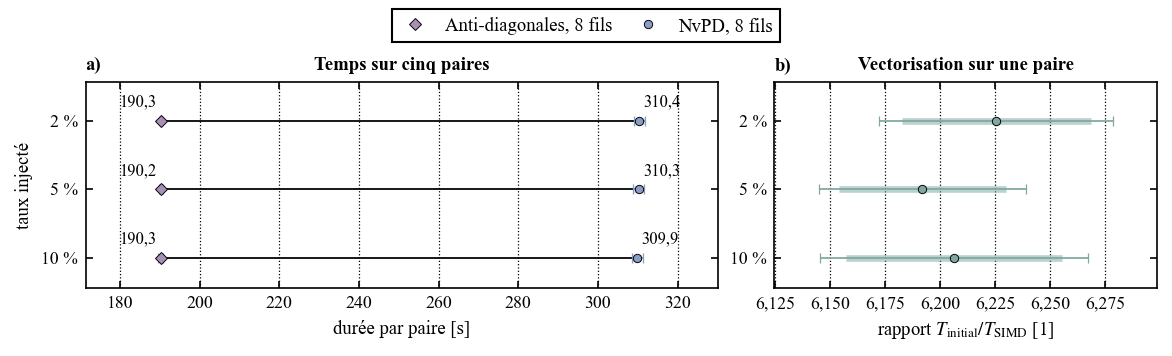

In [4]:
# Essais homogènes à un million de bases, une durée par méthode et par entrée.
long_raw = nv_csv(RES / "romeo/completion-1m/trials.csv")
assert len(long_raw) == 30 and long_raw.threads.eq(8).all() and long_raw.length.eq(1_000_000).all()
assert set(long_raw.algorithm) == {"diagonal", "nvpd-omp"}
assert long_raw.groupby(["rate", "algorithm"]).input_sha256.nunique().eq(5).all()
assert long_raw.groupby("input_sha256").distance.nunique().eq(1).all()
long_ref = nv_csv(RES / "romeo/completion-1m/references.csv")
assert set(long_ref.algorithm) == {"edlib", "wfa2"}
long_all = pd.concat([long_raw, long_ref])
assert long_all.groupby("input_sha256").algorithm.nunique().eq(4).all()
assert long_all.groupby("input_sha256").distance.nunique().eq(1).all()
long_times = long_raw.pivot(index=["rate", "input_sha256"], columns="algorithm", values="seconds")
long_ratio = long_times.diagonal / long_times["nvpd-omp"]
long_fig, long_ax = plt.subplots(1, 2, figsize=(7.7, 2.28), width_ratios=(1.65, 1))
long_rates = [0.02, 0.05, 0.10]
for long_i, long_rate in enumerate(long_rates):
    long_entries = []
    for long_alg in ["diagonal", "nvpd-omp"]:
        long_lab, long_col, long_mark = nv_methods[long_alg]
        long_values = long_times.xs(long_rate)[long_alg]
        long_entry = nv_stats.add(
            3, "seconds", long_alg, long_rate, long_values, "independent_fasta_pair"
        )
        long_entries.append((long_entry, long_col, long_mark, long_lab))
    comparison(long_ax[0], long_i, long_entries, digits=1)
category_rows(long_ax[0], ["2 %", "5 %", "10 %"], "durée par paire [s]")
long_blocks = nv_csv(RES / "repeated/epyc/trials.csv")
long_selected = long_blocks[
    long_blocks.warmup.eq(0)
    & long_blocks.algorithm.isin(["nvpd-initial", "nvpd-simd"])
    & long_blocks["case"].str.startswith("syn-1000000-")
]
long_matrix = long_selected.pivot(index=["case", "block"], columns="algorithm", values="seconds")
if (
    len(long_matrix) != 15
    or not long_selected.groupby(["case", "algorithm"]).block.nunique().eq(5).all()
):
    raise ValueError("La comparaison SIMD exige cinq blocs appariés sur trois entrées.")
assert long_matrix.notna().all().all() and long_selected.groupby("case").distance.nunique().eq(1).all()
long_gains = (long_matrix["nvpd-initial"] / long_matrix["nvpd-simd"]).droplevel("block")
long_gains.index = long_gains.index.str.rsplit("-", n=1).str[-1].astype(float)
for long_x, long_rate in enumerate(long_rates):
    long_stats = nv_stats.add(
        3,
        "speedup",
        "initial/SIMD",
        long_rate,
        long_gains[long_gains.index == long_rate],
        "paired_process_block",
    )
    estimate(long_ax[1], long_x, long_stats, COLORS[2], horizontal=True)
category_rows(long_ax[1], ["2 %", "5 %", "10 %"], r"rapport $T_{\mathrm{initial}}/T_{\mathrm{SIMD}}$ [1]")
long_ax[0].set_ylabel("taux injecté")
label_panels(long_ax)
column_titles(long_ax, ("Temps sur cinq paires", "Vectorisation sur une paire"))
legend_above(long_fig, long_ax, ncol=3)
nv_save(long_fig, "cpu/openmp_un_million")

*Figure 3.* À huit cœurs, le temps moyen de chaque noyau porte sur cinq paires par taux (a). Le gain SIMD porte sur la première paire de chaque taux, répétée dans cinq blocs préchauffés (b). Les intervalles horizontaux donnent l’écart-type et l’IC à 95 % des rapports appariés.

<sub>Code : [bench/cpu/openmp/million/collect_1m.py](../bench/cpu/openmp/million/collect_1m.py), [results/romeo/completion-1m/trials.csv](../results/romeo/completion-1m/trials.csv), [results/romeo/completion-1m/references.csv](../results/romeo/completion-1m/references.csv), [bench/repeated/measure.py](../bench/repeated/measure.py), [results/repeated/epyc/trials.csv](../results/repeated/epyc/trials.csv).</sub>

À 2 %, les cinq paires demandent en moyenne 190,28 (écart-type 0,13, IC 95 % de 190,13 à 190,44) s par anti-diagonales. Pour les mêmes entrées, le temps moyen de NvPD initial vaut 310,37 s. À 5 %, le rapport apparié initial/SIMD vaut 6,19 (écart-type 0,04, IC 95 % de 6,14 à 6,24). Les cinq tirages historiques renseignent la variabilité entre entrées dans cette campagne.

La réécriture de la boucle de NvPD permet ensuite d’isoler le rôle du compilateur.

<p><strong><u>Synthèse.</u></strong> Les anti-diagonales terminent avant la version initiale sur les 15 paires mesurées.<br>La seconde comparaison isole la réécriture SIMD à compilation identique.</p>

<a id="vectorisation"></a>

## Vectorisation de la récurrence de dernière occurrence

<hr>

La figure 4 isole les gains successifs de la vectorisation de la récurrence et de la compression de son index.

La version initiale utilise la dernière occurrence $k$ d’une lettre pour choisir le prédécesseur. Pour la case $(i,j)$, $k$ est la dernière position de la lettre $a_i$ dans $b_1,\dots,b_j$ et vaut zéro si elle est absente. Sur les colonnes intérieures, V1 calcule

$$D_{i,j}=\min\!\left(1+\min(D_{i-1,j-1},D_{i-1,j}),\,D_{i-1,\max(0,k-1)}+j-k\right).$$

Les bords valent $D_{i,0}=i$ et $D_{0,j}=j$. La formule lit uniquement la ligne précédente. Quand $k=j$, le second candidat reprend la diagonale sans coût. Quand $k=0$, il vaut $i-1+j$, une borne supérieure de la distance. Cette forme permet à OpenMP de vectoriser les colonnes. V2 reprend cette boucle et stocke les écarts $j-k$ sur un octet lorsque le maximum reste inférieur à 256. Si un écart est plus grand, V2 garde les entiers de quatre octets. Les scores restent entiers dans les trois versions. Les appels NvPD incluent la construction de l’index de dernières occurrences, l’allocation et les mises à jour de la matrice. Chaque paire de variantes utilise la même compilation, avec `-O3 -march=native -fopenmp`. À chaque répétition, le pilote mélange l’ordre des cas et alterne A puis B ou B puis A.

Les trois géométries isolent deux effets. Le carré de 20 000 × 20 000 distribue de nombreuses lignes de taille modérée. Les rectangles de 256 × 1 000 000 et de 64 × 4 194 304 contiennent des lignes de plus en plus longues et peu de barrières. Le second rectangle donne à l’index une largeur de plus de quatre millions de colonnes pour étudier son comportement dans les caches.

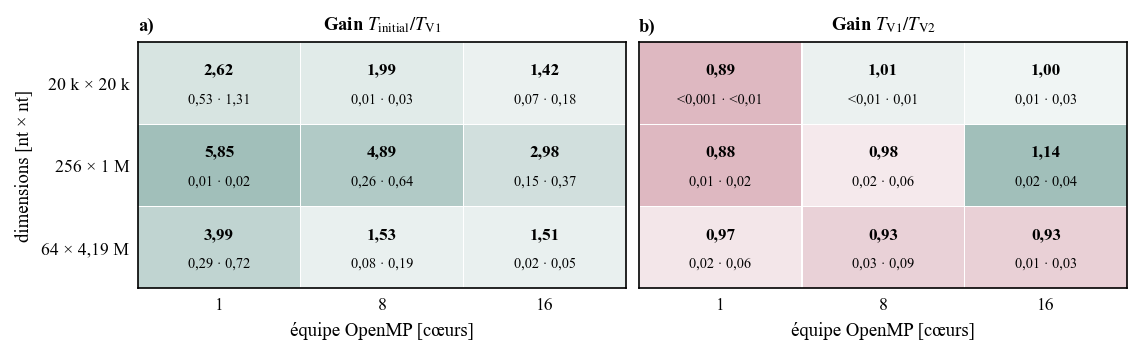

In [5]:
# Gains par étape à entrées et placement identiques (results/profile/cpu/ab.csv).
ab_raw = nv_csv(PROF / "cpu/ab.csv")
assert ab_raw.distance.eq(ab_raw.reference_distance).all()
assert ab_raw.groupby("case").input_fnv64.nunique().eq(1).all()
assert ab_raw.groupby(["comparison", "case", "threads", "trial"]).cpu_ids.nunique().eq(1).all()
assert ab_raw.groupby("case").max_gap.max().lt(256).all()
ab_cases = {"square": "20 k × 20 k", "wide": "256 × 1 M", "over_l3": "64 × 4,19 M"}
# Expérience distincte, une paire de mesures par taux à un million de bases.
ab_long = nv_csv(RES / "profile/million/838538/trials.csv")
assert len(ab_long) == 6 and set(ab_long.variant) == {"initial", "simd"}
assert ab_long.groupby("rate").input_sha256.nunique().eq(1).all()
assert ab_long.groupby("rate").distance.nunique().eq(1).all()
assert ab_long.groupby("rate").cpu_ids.nunique().eq(1).all()
ab_long_ref = (
    nv_pair[nv_pair.algorithm.eq("edlib") & nv_pair.rep.eq(1) & nv_pair.length.eq(1_000_000)]
    .set_index("input_sha256")
    .distance
)
assert ab_long.distance.eq(ab_long.input_sha256.map(ab_long_ref)).all()
ab_long_seconds = ab_long.pivot(index="rate", columns="variant", values="seconds")
ab_long_gains = ab_long_seconds.initial / ab_long_seconds.simd

from studies.measurement_matrix import measurement_matrix

ab_fig, ab_ax = plt.subplots(1, 2, figsize=(7.5, 2.25), sharey=True)
for ab_i, (ab_a, ab_b) in enumerate([("baseline", "v1"), ("v1", "v2")]):
    ab_data = ab_raw[ab_raw.comparison.eq(ab_a + "-" + ab_b)]
    ab_time = ab_data.pivot(index=["case", "threads", "trial"], columns="variant", values="seconds")
    ab_ratio = ab_time[ab_a] / ab_time[ab_b]
    ab_records = {}
    for ab_k, ab_case in enumerate(ab_cases):
        for ab_j, ab_threads in enumerate([1, 8, 16]):
            ab_records[ab_k, ab_j] = nv_stats.add(
                4, ab_a + "/" + ab_b, ab_case, ab_threads,
                ab_ratio.xs((ab_case, ab_threads)), "paired_process_block"
            )
    measurement_matrix(ab_ax[ab_i], ab_records, list(ab_cases.values()), ["1", "8", "16"],
                       center=1, spread=".2f")
    ab_ax[ab_i].set_xlabel("équipe OpenMP [cœurs]")
ab_ax[0].set_ylabel("dimensions [nt × nt]")
label_panels(ab_ax)
column_titles(ab_ax, (r"Gain $T_{\mathrm{initial}} / T_{\mathrm{V1}}$",
                      r"Gain $T_{\mathrm{V1}} / T_{\mathrm{V2}}$"))
nv_save(ab_fig, "cpu/variantes_cpu")

*Figure 4.* À forme et placement fixés, chaque case donne la moyenne des trois rapports appariés, puis l’écart-type et la demi-largeur de l’IC à 95 %. Le vert indique un gain supérieur à l’unité, le rose un ralentissement. L’intensité suit l’écart à l’unité dans chaque panneau.

<sub>Code : [python/studies/measurement_matrix.py](../python/studies/measurement_matrix.py), [src/cpu/dp.cpp](../src/cpu/dp.cpp), [bench/cpu/openmp/profile_cpu.md](../bench/cpu/openmp/profile_cpu.md), [bench/cpu/openmp/profile_cpu.py](../bench/cpu/openmp/profile_cpu.py), [results/profile/cpu/ab.csv](../results/profile/cpu/ab.csv), [results/profile/million/838538/trials.csv](../results/profile/million/838538/trials.csv).</sub>

Sur le carré de 20 000 bases à huit cœurs, le gain initial/V1 vaut 1,99 (écart-type 0,01, IC 95 % de 1,96 à 2,02). Pour V2, la conversion de l’index en octets ajoute du travail avant la récurrence. Le gain V1/V2 du grand rectangle sur les mêmes huit cœurs vaut 0,93.

La même récurrence peut aussi réduire le nombre de cellules visitées en conservant le score global exact.

<p><strong><u>Synthèse.</u></strong> Les deux transformations ont des effets différents sur les neuf couples forme et équipe.<br>La récurrence vectorisée conserve l’index entier dans la version de production.</p>

<a id="geometrie-bande"></a>

## Géométrie des passages en bande

<hr>

Les fenêtres de 33 bases du chromosome 20 proviennent de CP068258.1 et CP068258.2, deux versions du même assemblage CHM13. Le noyau retire trois bases communes à chaque extrémité. Sur les 27 bases restantes, la borne par composition vaut $L=\sum_x\max(0,N_B(x)-N_A(x))=2$ et le coût des substitutions positionnelles vaut $U=4$.

À longueurs égales, atteindre un décalage $e=j-i$ et revenir à zéro demande au moins $2|e|$ indels. Le budget $k$ limite donc la largeur à $|e|\leq\lfloor k/2\rfloor$. La figure 5 compte les mises à jour intérieures de chaque passage. La ligne et la colonne de conditions initiales sont exclues du compteur.

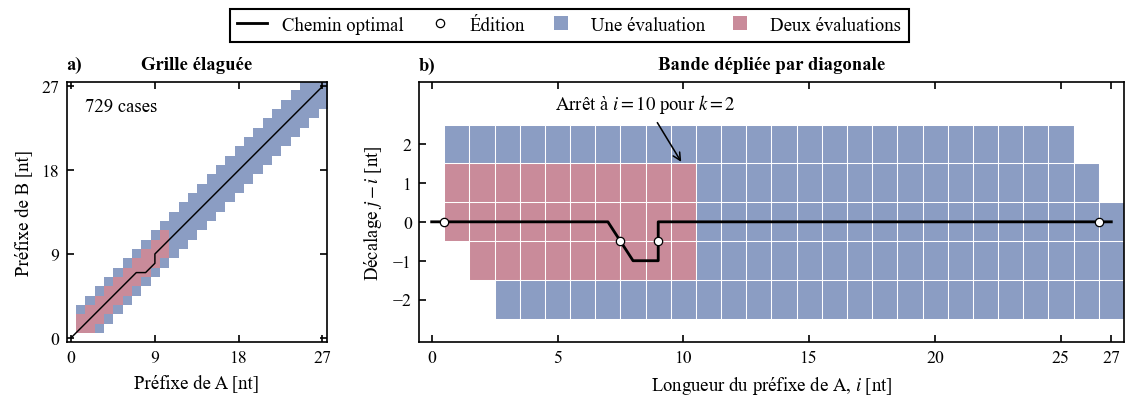

In [6]:
from studies.band_geometry import make_figure as bg_figure, study as bg_study

bg_geometry = bg_study(ROOT)
bg_visits = bg_geometry["visits"]
for bg_key, bg_value in {
    "dense": bg_visits.size,
    "distinct": np.count_nonzero(bg_visits),
    "revisited": np.count_nonzero(bg_visits == 2),
    "updates": bg_visits.sum(),
}.items():
    nv_stats.add(5, "cells", "nvpd-adaptive", bg_key, [bg_value], "fixed_human_interval")
nv_save(bg_figure(bg_geometry), "cpu/geometrie_bande", vector=True, alt='La bande adaptative et le chemin optimal sur un fragment du chromosome 20.')

*Figure 5.* La grille de gauche montre les cellules évaluées. À droite, chaque ligne correspond à un décalage du chemin par rapport à la diagonale. Le tracé noir suit un chemin optimal fourni par Edlib. Un cercle marque chacune des quatre éditions. Les cellules roses sont visitées aux deux passages.

<sub>Code : [python/studies/band_geometry.py](../python/studies/band_geometry.py), [noyau NvPD](../src/cpu/nvpd_adaptive.cpp), [fenêtres et contrôles](../results/adaptive/geometry/README.md).</sub>

Le chemin optimal reste dans la bande de budget deux. Son coût comprend pourtant deux substitutions, une suppression et une insertion. À la ligne 10, tous les scores du premier passage dépassent le budget. Le passage suivant atteint la dernière case au coût quatre. La comparaison de temps qui suit tient compte des cellules recalculées.

<p><strong><u>Synthèse.</u></strong> Les deux passages totalisent 158 mises à jour, soit 21,7 % des 729 cellules du calcul dense après élagage.<br>Sur les 129 cellules distinctes, 29 sont calculées deux fois.</p>

<a id="nvpd-adaptatif"></a>

## Récurrence exacte à largeur adaptative

<hr>

La figure 6 examine si le retrait de cellules inutiles réduit le temps de NvPD sur un cœur EPYC, à seuil ajusté jusqu’à obtention du score exact.

Après retrait du préfixe et du suffixe communs, le décalage d’une cellule est $\delta=j-i$ et celui des extrémités $\Delta=n-m$. Un chemin passant par cette cellule utilise au moins $|\delta|+|\Delta-\delta|$ insertions ou suppressions. Un budget $k$ permet donc d’exclure les cellules pour lesquelles cette somme dépasse $k$. Le calcul augmente le budget jusqu’à obtenir un coût terminal au plus égal à $k$. Les distances rendues sont vérifiées indépendamment avec edlib.

Le facteur $mn/C$ compare le rectangle initial aux $C$ cellules effectivement visitées, toutes les passes réunies. Une compilation témoin inhibe la vectorisation du noyau en bande. Les compteurs Zen 4 estiment la lecture en mémoire par 64 octets par remplissage compté. La courbe $P(I)=\min(P_{\mathrm{row}},B_{\mathrm{read}}I)$ combine le débit d’un noyau de mise à jour en cache, le débit d’une lecture de 192 Mio et l’intensité $I$ en cellules par octet lu estimé. Les deux débits sont étalonnés sur le même processeur. [Williams, Waterman et Patterson, 2009](https://doi.org/10.1145/1498765.1498785)

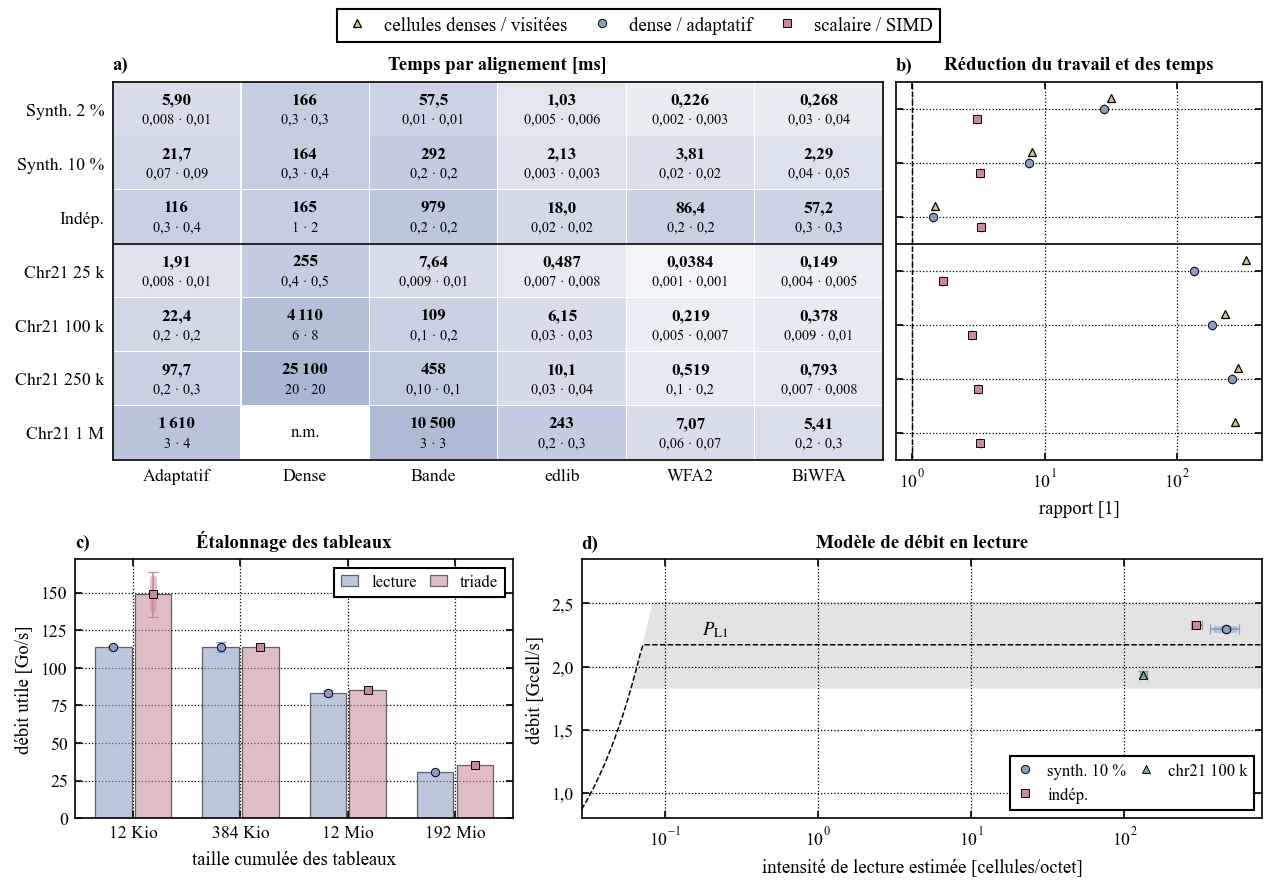

In [7]:
from studies.adaptive import make_figure as ad_make_figure

ad_dir = RES / "adaptive/839188"
ad_times = nv_csv(ad_dir / "trials.csv")
assert ad_times.groupby(["case", "algorithm"]).block.nunique().eq(5).all()
for (ad_case, ad_alg), ad_group in ad_times.groupby(["case", "algorithm"]):
    nv_stats.add(6, "seconds", ad_alg, ad_case, ad_group.seconds, "fresh_warmed_process")
for ad_case, ad_group in ad_times.groupby("case"):
    ad_q = ad_group.pivot(index="block", columns="algorithm", values="seconds")
    for ad_alg in ["nvpd-omp", "band-control", "banded-trim"]:
        if ad_alg in ad_q:
            nv_stats.add(
                6,
                "paired_time_over_adaptive",
                ad_alg,
                ad_case,
                ad_q[ad_alg] / ad_q["nvpd-adaptive"],
                "paired_process_block",
            )
ad_work = nv_csv(ad_dir / "work.csv")
for ad_r in ad_work.itertuples(index=False):
    nv_stats.add(
        6,
        "dense_over_visited_cells",
        "nvpd-adaptive",
        ad_r.case,
        [ad_r.cell_ratio],
        "operation_count",
        independent=False,
    )
ad_cal = nv_csv(ad_dir / "calibration.csv")
for (ad_kind, ad_size), ad_group in ad_cal.groupby(["kernel", "footprint_kib"]):
    ad_factor = {"row": 1, "read": 4, "triad": 12}[ad_kind]
    ad_rate = ad_factor * ad_group.elements * ad_group.rounds / (1e9 * ad_group.seconds)
    nv_stats.add(
        6,
        "gcell_s" if ad_kind == "row" else "requested_GB_s",
        ad_kind,
        ad_size,
        ad_rate,
        "fresh_calibration_process",
    )
ad_pmu = nv_csv(ad_dir / "counters.csv")
ad_pmu["event"] = ad_pmu.event.str.removesuffix(":u")
ad_panel = ad_pmu[ad_pmu.algorithm.eq("nvpd-adaptive")]
for ad_case, ad_group in ad_panel.groupby("case"):
    ad_reads = ad_group.pivot(index="block", columns="event", values="count")
    ad_row = ad_group[ad_group.event.eq("r4844")].set_index("block").sort_index()
    ad_bytes = 64 * (ad_reads.r4844 + ad_reads.rff72)
    nv_stats.add(
        6,
        "updates_per_estimated_dram_byte",
        "nvpd-adaptive",
        ad_case,
        ad_row.cells / ad_bytes,
        "fresh_counter_block",
    )
    nv_stats.add(
        6,
        "profile_gcell_s",
        "nvpd-adaptive",
        ad_case,
        ad_row.cells / (1e9 * ad_row.seconds),
        "fresh_counter_block",
    )
ad_fig = ad_make_figure(ROOT)
nv_save(ad_fig, "cpu/nvpd_adaptatif")

*Figure 6.* Les temps de cinq processus préchauffés sont exprimés en millisecondes (a). Sous la moyenne figurent l’écart-type et la demi-largeur de l’IC à 95 %. La teinte suit le logarithme de la durée. La mention « n.m. » signale une combinaison absente. Les rapports en b) suivent les mêmes lignes, des paires synthétiques aux fenêtres de chr21. Les étalons de débit (c) fixent la pente et le plafond du modèle de lecture (d). La zone grise correspond à un écart-type des paramètres.

<sub>Code : [python/studies/measurement_matrix.py](../python/studies/measurement_matrix.py), [src/cpu/nvpd_adaptive.cpp](../src/cpu/nvpd_adaptive.cpp), [src/cpu/nvpd_band_row.hpp](../src/cpu/nvpd_band_row.hpp), [bench/cpu/adaptive/analyze.py](../bench/cpu/adaptive/analyze.py), [python/studies/adaptive.py](../python/studies/adaptive.py), [results/adaptive/839188/trials.csv](../results/adaptive/839188/trials.csv), [results/adaptive/839188/work.csv](../results/adaptive/839188/work.csv), [results/adaptive/839188/counters.csv](../results/adaptive/839188/counters.csv), [results/adaptive/839188/calibration.csv](../results/adaptive/839188/calibration.csv).</sub>

Sur la fenêtre humaine de 100 knt, la version adaptative visite 0,43 % du rectangle initial. Le rapport apparié du temps dense au temps adaptatif vaut 183,49. Sur les chaînes indépendantes, la fraction visitée atteint 67,8 %, en cumulant les reprises. Sur la fenêtre de 1 Mnt, le témoin sans vectorisation prend 3,25 fois le temps du noyau en bande vectorisé. L’estimation par les compteurs porte sur les remplissages en lecture attribués à la mémoire externe. Elle laisse hors du modèle les écritures et le trafic servi par les caches.

Les lignes de scores et la table des dernières occurrences déterminent ensuite le volume de mémoire à conserver.

<p><strong><u>Synthèse.</u></strong> La fenêtre humaine d’un million de bases utilise 0,37 % du rectangle initial, toutes passes confondues.<br>Les gains de temps dépendent aussi du coût de chaque mise à jour et de la préparation des indices.</p>

<a id="hierarchie-memoire"></a>

## Occupation mémoire et défauts du cache de données

<hr>

La figure 7 compare l’espace occupé par les tableaux et le nombre de défauts de lecture L1D selon la largeur de la matrice.

Pour un alphabet de quatre lettres, les deux lignes de scores occupent $2(n+1)$ entiers. L’index des dernières occurrences en occupe $4(n+1)$. V1 occupe donc $24(n+1)$ octets. Si la conversion réussit, V2 occupe $12(n+1)$ octets pendant la boucle. La conversion conserve temporairement deux représentations de l’index. Une ligne lue pour une lettre donnée ne consulte qu’une des quatre lignes de cet index. Le pic RSS mesure le maximum de mémoire résidente du processus entier, y compris les chaînes, les autres allocations et la phase de chauffe.

Les compteurs en espace utilisateur couvrent un appel après chauffe, pour toute l’équipe OpenMP. Le pilote ouvre et ferme la fenêtre de mesure avec `perf stat --control`. Un compteur non pris en charge représente une mesure manquante. Les événements génériques dépendent du PMU et ne suffisent pas à déduire un débit DRAM. Les écarts maximaux, de 31 à 48 selon la forme, permettent à V2 d’utiliser des octets sur les trois cas. [Linux perf, manuel de perf-stat](https://man7.org/linux/man-pages/man1/perf-stat.1.html)

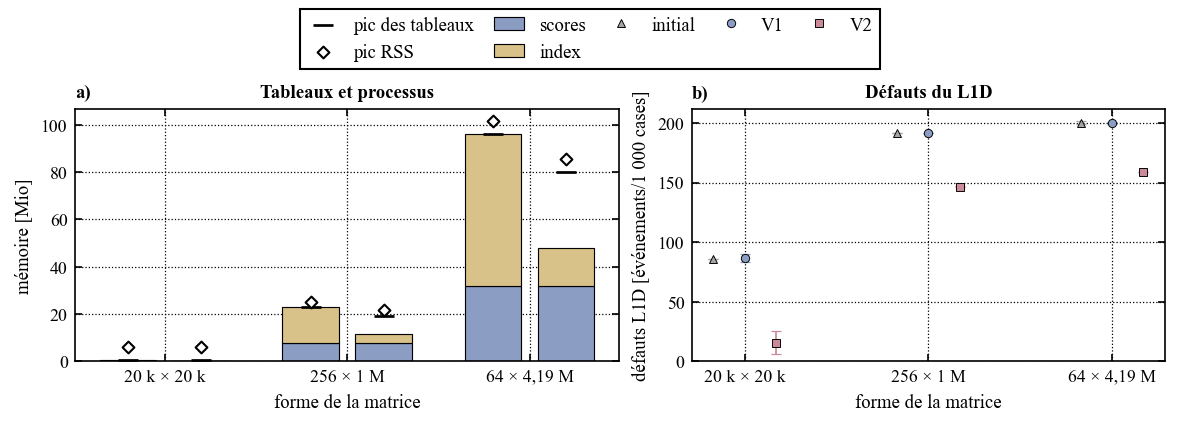

In [8]:
# Espace de travail et événements L1D, huit cœurs (results/profile/cpu/{ab,counters}.csv).
me_perf = nv_csv(PROF / "cpu/counters.csv")
assert me_perf.distance.eq(me_perf.reference_distance).all()
assert me_perf.running_pct.eq(100).all()
me_perf["event"] = me_perf.event.str.removesuffix(":u")
me_perf["count"] = pd.to_numeric(me_perf.value, errors="coerce")
me_perf["per_cell"] = me_perf["count"] / (me_perf.m * me_perf.n)
me_fig, me_ax = plt.subplots(1, 2, figsize=(7.75, 2.75), width_ratios=(1.15, 1))
me_x = np.arange(len(ab_cases))
me_rows = ab_raw[(ab_raw.threads == 8) & ab_raw.comparison.eq("v1-v2")]
for me_i, me_v in enumerate(["v1", "v2"]):
    me_g = me_rows[me_rows.variant.eq(me_v)].groupby("case")
    me_scores = me_g.dp_bytes.first().reindex(ab_cases)
    me_index = me_g.mit_bytes.first().reindex(ab_cases)
    me_peak = me_g.workspace_peak_bytes.first().reindex(ab_cases)
    me_rss = me_g.peak_rss_kib.max().reindex(ab_cases) / 1024
    me_pos = me_x + 0.2 * (2 * me_i - 1)
    for me_component, me_base, me_name, me_color in (
        (me_scores, 0, "scores", COLORS[0]), (me_index, me_scores, "index", COLORS[3])
    ):
        me_ax[0].bar(me_pos, me_component / 2**20, bottom=me_base / 2**20,
                     width=.31, color=me_color, edgecolor=INK, linewidth=.55,
                     label=me_name if me_i == 0 else None, zorder=2)
    me_ax[0].scatter(
        me_pos,
        me_peak / 2**20,
        marker="_",
        s=100,
        color=INK,
        zorder=3,
        label="pic des tableaux" if me_i == 0 else None,
    )
    me_ax[0].scatter(
        me_pos,
        me_rss,
        marker="D",
        s=16,
        facecolor=PAPER,
        edgecolor=INK,
        zorder=3,
        label="pic RSS" if me_i == 0 else None,
    )
for me_k, me_v in enumerate(["baseline", "v1", "v2"]):
    me_g = me_perf[
        (me_perf.threads == 8) & me_perf.event.eq("L1-dcache-load-misses") & me_perf.variant.eq(me_v)
    ]
    me_series = me_g.set_index("case").per_cell * 1000
    nv_plot(
        me_ax[1],
        me_series,
        list(ab_cases),
        me_x + 0.17 * (me_k - 1),
        7,
        "l1d_misses_per_1000",
        me_v,
        "perf_process",
        [COLORS[4], COLORS[0], COLORS[1]][me_k],
        "^os"[me_k],
        label=me_v.upper() if me_v != "baseline" else "initial",
    )
me_ax[0].set(ylabel="mémoire [Mio]", xlabel="forme de la matrice")
me_ax[1].set(ylabel="défauts L1D [événements/1 000 cases]", xlabel="forme de la matrice", ylim=(0, None))
me_ax[0].set_xticks(me_x, ab_cases.values())
me_ax[1].set_xticks(me_x, ab_cases.values())
label_panels(me_ax)
column_titles(me_ax, ("Tableaux et processus", "Défauts du L1D"))
legend_above(me_fig, me_ax, ncol=5)
nv_save(me_fig, "cpu/memoire_cpu")

*Figure 7.* Pour chaque matrice, les barres V1 (gauche) et V2 (droite) décomposent les tableaux actifs en scores et index. Le tiret donne leur maximum transitoire, le losange le maximum des RSS observés. À huit cœurs, deux processus préchauffés fournissent les moyennes de défauts L1D et leur incertitude.

<sub>Code : [bench/cpu/openmp/profile_cpu_driver.cpp](../bench/cpu/openmp/profile_cpu_driver.cpp), [bench/cpu/openmp/profile_cpu.py](../bench/cpu/openmp/profile_cpu.py), [results/profile/cpu/environment.txt](../results/profile/cpu/environment.txt), [results/profile/cpu/counters.csv](../results/profile/cpu/counters.csv).</sub>

La conversion atteint 80 Mio et le processus monte à 85,5 Mio, contre 101,6 Mio en V1. Sur huit cœurs, on compte 159 défauts L1D pour 1 000 cases en V2, contre 200 en V1, alors que le rapport moyen de temps V1/V2 vaut 0,93. Le nœud dispose de 32 Kio de L1D et 1 Mio de L2 par cœur, ainsi que de blocs de 32 Mio de L3 partagés par huit cœurs. Le plus grand index dépasse la capacité d’un de ces blocs.

Sur un chromosome entier, la lecture du fichier FASTA contribue également au temps de traitement.

<p><strong><u>Synthèse.</u></strong> Sur le rectangle de 4 194 304 colonnes, l’index compact ramène les tableaux actifs de 96 à 48 Mio.<br>Les compteurs L1D décrivent les lectures du cache. Ils ne donnent pas le débit du contrôleur DRAM.</p>

<a id="lecture-fasta"></a>

## Décodage de fichiers FASTA de chromosomes entiers

<hr>

La figure 8 mesure le temps et le coût du décodage FASTA avant tout alignement. Six chromosomes humains entiers sont lus par paires, chacun dans deux versions de CHM13.

Le lecteur initial traite les caractères un par un. Le lecteur par ligne reconnaît les bases A, C, G et T majuscules pour les copier en bloc. Une table traduit les autres caractères et vérifie leur validité. Deux compilations de ce lecteur activent ou désactivent la vectorisation du test de ligne. Une seconde allocation compare ce test par ligne à une classification explicite par blocs de 16 octets. Une troisième allocation reprend le lecteur par blocs dans un même binaire avec ou sans index FAI. Les longueurs indexées réservent la place nécessaire aux deux séquences avant la lecture. Le lecteur vérifie les identifiants, les positions et les dimensions des lignes. Le pilote vérifie séparément les empreintes du fichier et du contenu décodé.

Le débit est $(m+n)/T$. Le nombre d’instructions par base divise le compteur d’instructions retirées par $m+n$. Le rapport de défauts du cache L1D utilise les compteurs de lectures et de lectures manquées du processeur. Les fichiers sont déjà en cache lors des mesures.

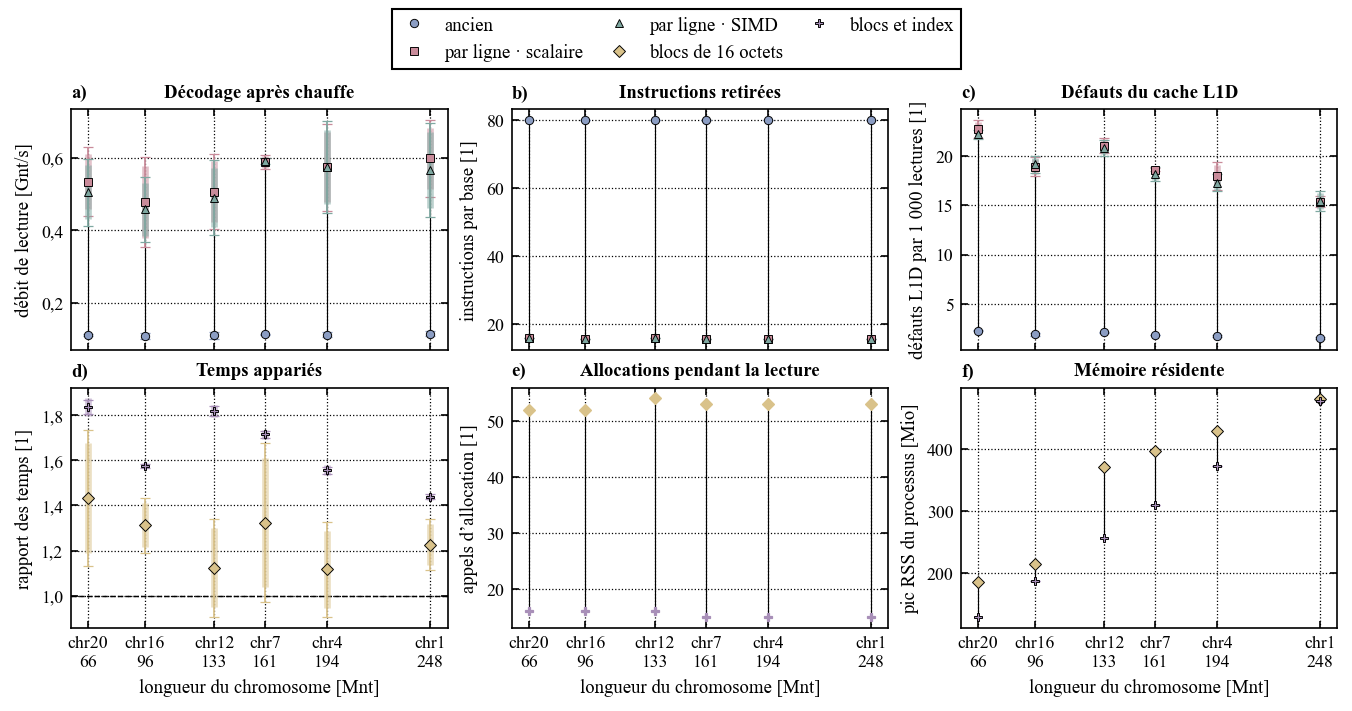

In [9]:
# Les compteurs et les durées proviennent de processus distincts.
fp_root = RES / "human/chromosome-panel"
fp_in = pd.read_csv(fp_root / "manifest.tsv", sep="\t").set_index("case")
fp_times = nv_csv(fp_root / "reader.csv")
fp_events = nv_csv(fp_root / "counters.csv")
fp_names = [("initial", "ancien"), ("scalar", "par ligne · scalaire"), ("simd", "par ligne · SIMD")]
fp_order = sorted(fp_times["case"].unique(), key=lambda k: fp_in.at[k, "m"])
assert fp_times.groupby(["case", "method"]).block.nunique().eq(5).all()
fp_counts = fp_events.pivot(
    index=["case", "method", "block"], columns="event", values="value"
).reset_index()
assert (
    fp_counts[["instructions", "cycles", "L1-dcache-loads", "L1-dcache-load-misses"]].notna().all().all()
)
fp_grid_fig, fp_grid = plt.subplots(2, 3, figsize=(8.9, 4.65), sharex=True)
fp_panels = [
    ("throughput", "débit de lecture [Gnt/s]"),
    ("instructions", "instructions par base [1]"),
    ("l1_misses", "défauts L1D par 1 000 lectures [1]"),
]
for fp_ix, (fp_metric, fp_label) in enumerate(fp_panels):
    fp_axis = fp_grid.ravel()[fp_ix]
    fp_centers = []
    for fp_mi, (fp_method, fp_title) in enumerate(fp_names):
        fp_time = fp_times[fp_times.method.eq(fp_method)].copy()
        fp_event = fp_counts[fp_counts.method.eq(fp_method)].copy()
        fp_time["bases"] = fp_time["case"].map(fp_in.m + fp_in.n)
        fp_event["bases"] = fp_event["case"].map(fp_in.m + fp_in.n)
        if fp_metric == "throughput":
            fp_data = (fp_time.bases / (1e9 * fp_time.seconds)).set_axis(fp_time["case"])
        elif fp_metric == "instructions":
            fp_data = (fp_event.instructions / fp_event.bases).set_axis(fp_event["case"])
        else:
            fp_data = (1000 * fp_event["L1-dcache-load-misses"] / fp_event["L1-dcache-loads"]).set_axis(
                fp_event["case"]
            )
        fp_x = [fp_in.at[k, "m"] / 1e6 for k in fp_order]
        fp_centers.append(nv_plot(
            fp_axis,
            fp_data,
            fp_order,
            fp_x,
            8,
            fp_metric,
            fp_method,
            "fresh_process",
            COLORS[fp_mi],
            "os^"[fp_mi],
            joined=False,
            label=fp_title,
        ))
    fp_axis.vlines(fp_x, np.min(fp_centers, axis=0), np.max(fp_centers, axis=0),
                   color=INK, linewidth=.55, zorder=1)
    fp_axis.set(xlabel="longueur du chromosome [Mnt]", ylabel=fp_label)
# Les rapports temporels restent appariés à l’intérieur de chaque allocation.
fp_blocks = nv_csv(fp_root / "blocks.csv")
assert fp_blocks.groupby(["case", "method"]).block.nunique().eq(5).all()
fp_x = [fp_in.at[k, "m"] / 1e6 for k in fp_order]
fp_block_times = fp_blocks.pivot(index=["case", "block"], columns="method", values="seconds")
fp_gain = (fp_block_times.portable / fp_block_times.blocks).droplevel("block")
nv_plot(
    fp_grid[1, 0],
    fp_gain,
    fp_order,
    fp_x,
    8,
    "paired_time_ratio",
    "portable/blocks",
    "paired_process_block",
    COLORS[3],
    "D",
    joined=False,
    label="blocs de 16 octets",
)
fp_grid[1, 0].set(xlabel="longueur du chromosome [Mnt]", ylabel="rapport des temps [1]")
fp_grid[1, 0].axhline(1, **GUIDE)
fp_idx = nv_csv(fp_root / "index-trials.csv")
assert fp_idx.groupby(["case", "method"]).block.nunique().eq(9).all()
assert fp_idx.groupby("case").normalized_sha256.nunique().eq(1).all()
fp_idx_times = fp_idx.pivot(index=["case", "block"], columns="method", values="seconds")
fp_idx_gain = (fp_idx_times.blocks / fp_idx_times.indexed).droplevel("block")
nv_plot(
    fp_grid[1, 0],
    fp_idx_gain,
    fp_order,
    fp_x,
    8,
    "paired_time_ratio",
    "blocks/indexed",
    "paired_process_block",
    COLORS[5],
    "P",
    joined=False,
    label="blocs et index",
)
# Les deux méthodes partagent le lecteur et la politique SIMD.
fp_alloc_centers, fp_rss_centers = [], []
for fp_method, fp_label, fp_marker, fp_color in [
    ("blocks", "blocs de 16 octets", "D", COLORS[3]),
    ("indexed", "blocs et index", "P", COLORS[5]),
]:
    fp_focus = fp_idx[fp_idx.method.eq(fp_method)]
    assert fp_focus.groupby("case").allocations.nunique().eq(1).all()
    assert fp_focus.groupby("case").requested_bytes.nunique().eq(1).all()
    fp_nalloc = []
    for fp_name in fp_order:
        fp_s = fp_focus[fp_focus["case"].eq(fp_name)].iloc[0]
        fp_nalloc.append(int(fp_s.allocations))
        nv_stats.add(
            8,
            "allocations",
            fp_method,
            fp_name,
            [fp_s.allocations],
            "controlled_allocation_count",
            independent=False,
        )
        nv_stats.add(
            8,
            "requested_bytes",
            fp_method,
            fp_name,
            [fp_s.requested_bytes],
            "controlled_allocation_count",
            independent=False,
        )
    fp_alloc_centers.append(fp_nalloc)
    fp_grid[1, 1].plot(fp_x, fp_nalloc, ls="none", marker=fp_marker, color=fp_color, label=fp_label)
    fp_mem = fp_focus.set_index("case").peak_rss_kib / 1024
    fp_rss_centers.append(nv_plot(
        fp_grid[1, 2],
        fp_mem,
        fp_order,
        fp_x,
        8,
        "rss_mib",
        fp_method,
        "fresh_warmed_process",
        fp_color,
        fp_marker,
        joined=False,
        label=fp_label,
    ))
for fp_axis, fp_ends in zip(fp_grid[1, 1:], [fp_alloc_centers, fp_rss_centers]):
    fp_axis.vlines(fp_x, np.min(fp_ends, axis=0), np.max(fp_ends, axis=0),
                   color=INK, linewidth=.55, zorder=1)
fp_grid[1, 1].set(xlabel="longueur du chromosome [Mnt]", ylabel="appels d’allocation [1]")
fp_grid[1, 2].set(xlabel="longueur du chromosome [Mnt]", ylabel="pic RSS du processus [Mio]")
fp_ticks = [f"{case}\n{length:.0f}" for case, length in zip(fp_order, fp_x)]
for fp_axis in fp_grid[1]:
    fp_axis.set_xticks(fp_x, fp_ticks)
for fp_axis in fp_grid[0]:
    fp_axis.set_xlabel("")
label_panels(fp_grid.ravel())
column_titles(fp_grid[0], ("Décodage après chauffe", "Instructions retirées", "Défauts du cache L1D"))
column_titles(fp_grid[1], ("Temps appariés", "Allocations pendant la lecture", "Mémoire résidente"))
legend_above(fp_grid_fig, fp_grid.ravel(), ncol=3)
nv_save(fp_grid_fig, "cpu/lecture_fasta_chromosomes")

*Figure 8.* Les segments verticaux relient les valeurs moyennes des lecteurs pour un même chromosome. Les trois panneaux supérieurs comparent le débit et les compteurs de trois lecteurs sur un cœur EPYC. Les temps portent sur le second appel de cinq processus. Les compteurs proviennent de processus distincts avec les pages en cache. En d), les rapports par ligne/par blocs de 16 octets et sans index/avec index portent respectivement sur cinq et neuf blocs appariés. Les panneaux e) et f) comparent les allocations et le pic RSS des deux modes par blocs.

<sub>Code : [src/io/fasta.cpp](../src/io/fasta.cpp), [bench/human/chromosome-panel/measure.py](../bench/human/chromosome-panel/measure.py), [results/human/chromosome-panel/manifest.tsv](../results/human/chromosome-panel/manifest.tsv), [results/human/chromosome-panel/reader.csv](../results/human/chromosome-panel/reader.csv), [results/human/chromosome-panel/counters.csv](../results/human/chromosome-panel/counters.csv), [bench/human/chromosome-panel/blocks/sweep.py](../bench/human/chromosome-panel/blocks/sweep.py), [results/human/chromosome-panel/blocks.csv](../results/human/chromosome-panel/blocks.csv), [bench/human/chromosome-panel/blocks/index.py](../bench/human/chromosome-panel/blocks/index.py), [results/human/chromosome-panel/index-trials.csv](../results/human/chromosome-panel/index-trials.csv).</sub>

Sur le chromosome 1, le lecteur avec test vectorisable prend 0,905 (écart-type 0,182, IC à 95 % de 0,679 à 1,130) s. Le rapport apparié des temps du lecteur initial et de cette variante est de 4,92. Le nombre moyen d’instructions retirées par base passe de 80,0 à 15,7. Dans la seconde allocation, le rapport du temps par ligne au temps par blocs de 16 octets vaut 1,23 (écart-type 0,09, IC à 95 % de 1,11 à 1,34) sur le chromosome 1. Les deux lecteurs comptent 54 demandes d’allocation pour 1 006 641 593 octets demandés au total. Dans la troisième allocation, l’index porte le rapport apparié du temps sans index au temps avec index à 1,44 (écart-type 0,01, IC à 95 % de 1,43 à 1,45). Le nombre d’appels d’allocation passe de 53 à 15. Les demandes cumulées représentent 960,0 puis 473,8 Mio. Les pics RSS moyens des deux processus atteignent respectivement 480,4 et 477,0 Mio.

L’espace de travail change ensuite si l’alignement doit aussi restituer son chemin.

<p><strong><u>Synthèse.</u></strong> Les six chromosomes donnent les mêmes enregistrements dans tous les modes de lecture.<br>Sur le chromosome 1, réserver la longueur annoncée par l’index demande 15 allocations.</p>

<a id="trace-lineaire"></a>

## Reconstruction de l’alignement en espace linéaire

<hr>

La figure 9 compare le temps et le pic de mémoire du processus pour retrouver un chemin optimal de deux manières.

Le procédé de Hirschberg a été publié pour la plus longue sous-séquence commune. Ici les deux passes utilisent les coûts de Levenshtein. À la coupure $i=\lfloor m/2\rfloor$, $F_j$ donne le coût entre les préfixes $a_{1:i}$ et $b_{1:j}$. Une passe sur les chaînes inversées donne les coûts de suffixe $R_{n-j}$. On choisit $j^\star\in\arg\min_j(F_j+R_{n-j})$ et on reconstruit les deux sous-chemins. Les passes calculent au total $O(mn)$ cases et utilisent $O(\min(m,n))$ scores en choisissant la chaîne la plus courte pour les colonnes. Cette borne exclut la pile de récursion et le chemin en sortie. Le format CIGAR regroupe les longueurs successives de correspondances (=), substitutions (X), insertions (I) et suppressions (D). [Hirschberg, 1975](https://doi.org/10.1145/360825.360861)

Les mesures sur un cœur AMD EPYC 9654 de ROMEO lancent les algorithmes sur le même FASTA lorsqu’ils acceptent sa longueur. Le pilote exécute une seule méthode par processus. À chaque taille, 31 blocs indépendants chauffent chaque méthode sur la paire complète avant l’alignement chronométré. Les chemins et les scores sont vérifiés. Les cases de la figure représentent les configurations exécutées. L’implémentation qui conserve tout le tableau limite les deux longueurs à 20 000 bases pour le chemin.

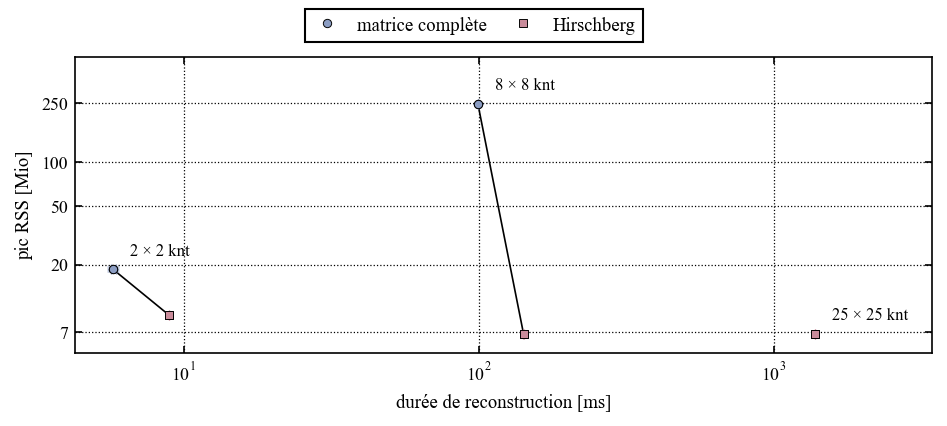

In [10]:
# Coût et mémoire d'une reconstruction complète ou par coupures.
tb_trials = nv_csv(RES / "repeated/epyc-trace/trials.csv")
tb_raw = tb_trials[tb_trials.warmup.eq(0)].rename(
    columns={"process_peak_rss_kib": "peak_rss_kib", "input_sha256": "sha256"}
)
assert tb_raw.groupby(["case", "algorithm"]).block.nunique().eq(31).all()
assert tb_raw.groupby("case").distance.nunique().eq(1).all()
assert tb_raw.groupby("case").sha256.nunique().eq(1).all()
tb_shapes = tb_raw[["case", "m", "n"]].drop_duplicates().sort_values(["m", "n"]).set_index("case")
tb_cases = list(tb_shapes.index)
tb_labels = [f"{tb_shapes.loc[c, 'm'] / 1000:g} × {tb_shapes.loc[c, 'n'] / 1000:g}" for c in tb_cases]
tb_alg_h = next(method for method in tb_raw.algorithm.unique() if "hirsch" in method.lower())
tb_alg_d = next(method for method in tb_raw.algorithm.unique() if method != tb_alg_h)
tb_fig, tb_ax = plt.subplots(figsize=(6.2, 2.75))
for tb_i, tb_case in enumerate(tb_cases):
    tb_points = []
    for tb_k, (tb_alg, tb_label) in enumerate([(tb_alg_d, "matrice complète"), (tb_alg_h, "Hirschberg")]):
        tb_rows = tb_raw[tb_raw.case.eq(tb_case) & tb_raw.algorithm.eq(tb_alg)]
        if tb_rows.empty:
            continue
        tb_time = nv_stats.add(9, "milliseconds", tb_alg, tb_case, tb_rows.seconds * 1000, "fresh_process")
        tb_rss = nv_stats.add(9, "rss_mib", tb_alg, tb_case, tb_rows.peak_rss_kib / 1024, "fresh_process")
        estimate(tb_ax, tb_time["mean"], tb_rss, COLORS[tb_k], marker="os"[tb_k], label=tb_label)
        estimate(tb_ax, tb_rss["mean"], tb_time, COLORS[tb_k], marker="os"[tb_k], horizontal=True)
        tb_points.append((tb_time["mean"], tb_rss["mean"]))
    if len(tb_points) == 2:
        tb_ax.plot(*zip(*tb_points), color=INK, linewidth=.8, zorder=1)
    tb_point = tb_points[0]
    tb_ax.annotate(tb_labels[tb_i] + " knt", tb_point,
                   xytext=(8, 7), textcoords="offset points", ha="left", fontsize=8)
tb_ax.set(xscale="log", yscale="log", xlabel="durée de reconstruction [ms]", ylabel="pic RSS [Mio]")
tb_ax.set_ylim(5, 520)
tb_ax.set_xlim(4.3, 3450)
tb_ax.set_yticks([7, 20, 50, 100, 250], ["7", "20", "50", "100", "250"])
tb_ax.xaxis.set_minor_locator(plt.NullLocator())
tb_ax.yaxis.set_minor_locator(plt.NullLocator())
legend_above(tb_fig, [tb_ax], ncol=2)
nv_save(tb_fig, "cpu/trace_lineaire")

*Figure 9.* Pour un même préfixe, le segment relie les deux méthodes dans le plan temps–mémoire. Les barres horizontales portent sur la durée du second appel, les verticales sur le pic RSS des deux appels. Chaque point résume 31 processus sur un cœur EPYC. À 25 knt, la mesure porte sur Hirschberg.

<sub>Code : [src/cpu/hirschberg.cpp](../src/cpu/hirschberg.cpp), [bench/repeated/kernel.cpp](../bench/repeated/kernel.cpp), [bench/repeated/measure.py](../bench/repeated/measure.py), [results/repeated/epyc-trace/trials.csv](../results/repeated/epyc-trace/trials.csv).</sub>

À 8 knt, le calcul Hirschberg demande 141,90 (écart-type 0,51, IC 95 % de 141,71 à 142,09) ms. Pour cette paire, le maintien de toute la matrice augmente la mémoire requise. Le pic RSS moyen à 8 knt atteint 247,48 Mio pour la matrice et 6,78 Mio pour Hirschberg. Les coupures calculent plusieurs fois une partie des scores et échangent ce travail contre une réduction du pic RSS. Le chemin est vérifié en rejouant toutes ses opérations.

Les compteurs du processeur permettent ensuite d’examiner les instructions du calcul de coût.

<p><strong><u>Synthèse.</u></strong> La reconstruction par coupures restitue un chemin de coût 531 pour deux chaînes de 25 000 bases.<br>La politique de mémoire de la matrice complète borne les entrées qu’elle accepte.</p>

<a id="instructions"></a>

## Instructions et prédictions de branchement

<hr>

La figure 10 rapporte le travail exécuté par le processeur au nombre de cases de la matrice.

Pour $N=mn$ cases, les événements par case valent $C/N$. Les compteurs proviennent de deux appels après chauffe et la fréquence d’horloge peut varier.

L’IPC rapporte les instructions retirées aux cycles comptés. Un événement de branchement mal prédit concerne le chemin d’exécution du processeur. Sur une équipe, les cycles comptés s’additionnent sur les fils. Les données de cette figure proviennent d’un seul cœur.

Linux perf recueille les événements matériels via les compteurs de l’unité de suivi des performances. Le pilote limite le comptage à la région NvPD après chauffe. [Linux, perf stat](https://man7.org/linux/man-pages/man1/perf-stat.1.html)

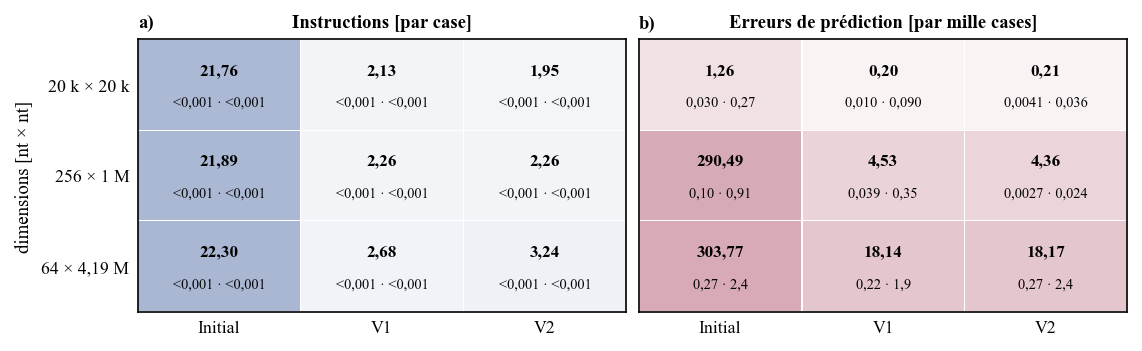

In [11]:
# Compteurs du calcul à un cœur. La valeur disponible est ramenée à une case.
pm_g = me_perf[me_perf.threads.eq(1)]
pm_fig, pm_ax = plt.subplots(1, 2, figsize=(7.5, 2.23), sharey=True)
pm_events = [("instructions", 1), ("branch-misses", 1000)]
for pm_i, (pm_event, pm_scale) in enumerate(pm_events):
    pm_records = {}
    for pm_j, pm_case in enumerate(ab_cases):
        for pm_k, pm_var in enumerate(["baseline", "v1", "v2"]):
            pm_series = pm_g[
                pm_g.event.eq(pm_event) & pm_g.variant.eq(pm_var) & pm_g.case.eq(pm_case)
            ].per_cell * pm_scale
            pm_records[pm_j, pm_k] = nv_stats.add(
                10, pm_event, pm_var, pm_case, pm_series, "perf_process"
            )
    measurement_matrix(pm_ax[pm_i], pm_records, list(ab_cases.values()), ["Initial", "V1", "V2"],
                       precision=".2f", spread=".2g", log=bool(pm_i), color=pm_i)
pm_ax[0].set_ylabel("dimensions [nt × nt]")
label_panels(pm_ax)
column_titles(pm_ax, ("Instructions [par case]", "Erreurs de prédiction [par mille cases]"))
nv_save(pm_fig, "cpu/cout_instructions")

*Figure 10.* Chaque case donne la moyenne de deux processus préchauffés, puis l’écart-type et la demi-largeur de l’IC à 95 %. La teinte suit le nombre d’instructions par case (a) et le logarithme du nombre d’erreurs de prédiction pour mille cases (b).

<sub>Code : [python/studies/measurement_matrix.py](../python/studies/measurement_matrix.py), [src/cpu/dp.cpp](../src/cpu/dp.cpp), [bench/cpu/openmp/profile_cpu.py](../bench/cpu/openmp/profile_cpu.py), [results/profile/cpu/vectorization.csv](../results/profile/cpu/vectorization.csv), [results/profile/cpu/counters.csv](../results/profile/cpu/counters.csv).</sub>

À un cœur sur le rectangle de 256 lignes, les instructions passent de 21,89 par case à 2,26 entre la version initiale et V1. Les mauvaises prédictions passent de 291 à 4,5 pour 1 000 cases et les cycles de 9,46 à 1,59 par case. Pour le carré, les mauvaises prédictions sont déjà rares dans la version initiale (1,3 pour 1 000 cases) et V1 réduit encore le nombre d’instructions de 21,76 à 2,13 par case. Le diagnostic de GCC confirme des vecteurs de 32 octets dans cette boucle.

Sur GPU, la même indépendance entre colonnes permet de regrouper plusieurs lignes.

<p><strong><u>Synthèse.</u></strong> Sur le grand rectangle à un cœur, la version vectorisée réduit les cycles par case d’un facteur 5,95.<br>Le coût de la prédiction se manifeste davantage sur ce rectangle que sur le carré.</p>

<a id="tuiles-cuda"></a>

## Regroupement des lignes en tuiles CUDA

<hr>

La figure 11 compare un noyau CUDA lancé à chaque ligne à un noyau qui regroupe plusieurs lignes.

Pour $q$ lignes par tuile et $m$ lignes, le noyau principal est lancé $\lceil m/q\rceil$ fois si la portée des dépendances permet ce découpage. Le gain divise les moyennes des deux versions entre processus. Chaque processus fournit une première durée puis la moyenne de trois appels chauds.

Dans la version initiale (A), le CPU lance un noyau par ligne. La variante retenue (B) avance de huit lignes par tuile en mémoire partagée. Chaque bloc recalcule un halo à gauche pour pouvoir progresser sans lire le travail d’un bloc voisin. Ses 256 fils couvrent 1 024 colonnes lorsque la grille garde au moins deux blocs par multiprocesseur, sinon 256. Lorsque la dépendance gauche dépasse 64 colonnes, ou que le chemin d’alignement est demandé, le programme utilise le noyau par ligne. La mesure à froid démarre dans un processus neuf. Les mesures à chaud démarrent après un premier appel vérifié dans ce même processus. Le retour du dernier coût sur l’hôte garantit que le GPU a terminé. Dans les deux cas, le temps couvre aussi le calcul de l’index, les allocations et les transferts. [NVIDIA, mesure du temps CPU et GPU](https://docs.nvidia.com/cuda/cuda-c-best-practices-guide/index.html#timing)

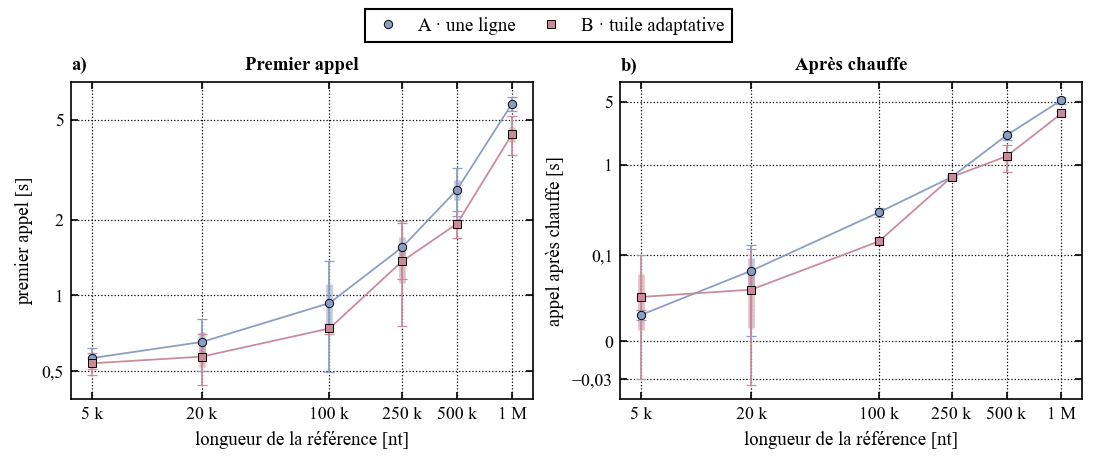

In [12]:
# Appels froids et chauds sur les mêmes FASTA, hors capture Nsight.
gp_dir = PROF / "gpu/838170"
gp_raw = nv_csv(gp_dir / "trials.csv")
gp_truth = nv_pair[nv_pair.algorithm.eq("edlib") & nv_pair.rate.eq(0.02) & nv_pair.rep.eq(1)]
assert set(gp_raw.variant) == {"baseline", "candidate"} and gp_raw.trace.eq(0).all()
gp_ref = gp_truth.set_index("length").distance
assert gp_raw.groupby("input").distance.nunique().eq(1).all()
gp_comparable = gp_raw[gp_raw.m.isin(gp_ref.index)]
assert gp_comparable.distance.eq(gp_comparable.m.map(gp_ref)).all()
assert gp_raw.groupby(["input", "variant", "mode"]).run.nunique().eq(3).all()
gp_counts = gp_raw.groupby(["input", "variant", "mode", "run"]).size()
assert gp_counts.xs("cold", level="mode").eq(1).all() and gp_counts.xs("warm", level="mode").eq(3).all()
assert gp_raw.groupby("input").device_bytes.nunique().eq(1).all()
gp_hold = nv_csv(PROF / "gpu/838173/trials.csv")
gp_htruth = nv_pair[nv_pair.algorithm.eq("edlib") & nv_pair.rate.eq(0.10) & nv_pair.rep.eq(1)]
assert gp_hold.distance.eq(gp_hold.m.map(gp_htruth.set_index("length").distance)).all()
gp_groups = ["m", "variant", "mode", "run"]
# Une mesure froide et une moyenne des mesures chaudes par processus.
gp_lineage = pd.concat(
    {
        "tuiles fixes, 2 %": nv_csv(PROF / "gpu/838161/trials.csv"),
        "largeur adaptative, 2 %": gp_raw,
        "largeur adaptative, 10 %": gp_hold,
    },
    names=["expérience"],
).reset_index(level=0)
gp_runs = gp_lineage.groupby(["expérience", *gp_groups], as_index=False).seconds.mean()
gp_means = gp_runs.groupby(["expérience", "m", "mode", "variant"]).seconds.mean().unstack()
gp_means["gain"] = gp_means["baseline"] / gp_means["candidate"]
for gp_name, gp_family in gp_runs[gp_runs["mode"].eq("warm")].groupby("expérience"):
    for gp_m, gp_size in gp_family.groupby("m"):
        for gp_key, gp_data in gp_size.groupby("variant"):
            nv_stats.add(
                11, "warm_lineage", gp_name + "/" + gp_key, gp_m, gp_data.seconds, "independent_process"
            )
gp_run = gp_runs[gp_runs["expérience"].eq("largeur adaptative, 2 %")]
gp_fig, gp_ax = plt.subplots(1, 2, figsize=(7.2, 3.0))
for gp_k, (gp_variant, gp_label) in enumerate(
    [("baseline", "A · une ligne"), ("candidate", "B · tuile adaptative")]
):
    for gp_i, gp_mode in enumerate(["cold", "warm"]):
        gp_sub = gp_run[gp_run.variant.eq(gp_variant) & gp_run["mode"].eq(gp_mode)].set_index("m")
        gp_sizes = np.sort(gp_run.m.unique())
        nv_plot(
            gp_ax[gp_i],
            gp_sub.seconds,
            gp_sizes,
            gp_sizes,
            11,
            gp_mode,
            gp_variant,
            "independent_process",
            COLORS[gp_k],
            "os"[gp_k],
            joined=True,
            label=gp_label,
        )
for gp_axis, gp_label in zip(gp_ax, ["premier appel [s]", "appel après chauffe [s]"]):
    gp_axis.set(xscale="log", yscale="log", xlabel="longueur de la référence [nt]", ylabel=gp_label)
    gp_sizes = np.sort(gp_run.m.unique())
    gp_ticks = {
        5000: "5 k",
        20000: "20 k",
        100000: "100 k",
        250000: "250 k",
        500000: "500 k",
        1000000: "1 M",
    }
    gp_axis.set_xticks(gp_sizes, [gp_ticks[v] for v in gp_sizes])
gp_ax[0].set_yticks([0.5, 1, 2, 5], ["0,5", "1", "2", "5"])
gp_ax[1].set_yscale("symlog", linthresh=0.04, linscale=0.5)
gp_ax[1].set_yticks([-0.03, 0, 0.1, 1, 5], ["−0,03", "0", "0,1", "1", "5"])
label_panels(gp_ax)
column_titles(gp_ax, ("Premier appel", "Après chauffe"))
legend_above(gp_fig, gp_ax, ncol=2)
nv_save(gp_fig, "gpu/variantes_gpu")

*Figure 11.* Trois processus neufs fournissent chacun une première durée à froid puis trois durées chaudes. Pour la moyenne et l’IC entre processus, les trois appels chauds d’un processus comptent comme une seule observation, leur moyenne. Les deux panneaux portent sur le jeu à 2 %. Le centre linéaire de l’échelle du panneau b) rend visibles les bornes négatives de l’IC lorsque la dispersion est forte.

<sub>Code : [src/cuda/cuda.cu](../src/cuda/cuda.cu), [bench/gpu/cuda/profile_gpu.cu](../bench/gpu/cuda/profile_gpu.cu), [results/profile/gpu/838161/trials.csv](../results/profile/gpu/838161/trials.csv), [results/profile/gpu/838170/trials.csv](../results/profile/gpu/838170/trials.csv), [results/profile/gpu/838173/trials.csv](../results/profile/gpu/838173/trials.csv).</sub>

À un million de bases et à 2 %, le temps chaud de la variante adaptative vaut 3,711 (écart-type 0,099, IC 95 % de 3,466 à 3,957) s, contre 5,222 s pour une ligne par lancement. Chaque processus pèse autant, indépendamment de sa vitesse. À un million de bases, le rapport des temps chauds moyens vaut 0,97 pour les tuiles fixes à 2 % (838161) et 1,41 pour les tuiles adaptatives du contrôle à 10 % (838173). Le panneau principal utilise la largeur adaptative à 2 % (838170).

La trace d’un appel court permet de compter les lancements et de séparer leurs durées.

<p><strong><u>Synthèse.</u></strong> Une tuile de huit lignes réduit le nombre de lancements lorsque la portée des dépendances le permet.<br>Les trois processus par configuration mesurent aussi les fluctuations du nœud pour chaque taille.</p>

<a id="trace-cuda"></a>

## Chronologie des appels hôte et des noyaux CUDA

<hr>

La figure 12 décompose les traces CUDA pour associer le nombre de lancements aux durées hôte et GPU.

Le temps cumulé des noyaux vaut $T_K=\sum_i t_i$. Les domaines hôte et GPU peuvent se recouvrir. La mesure A/B du temps mural provient d’exécutions séparées.

Nsight Systems encadre un appel après chauffe sur la paire de 5 000 bases à 2 %. Le nombre de noyaux correspond aux instances enregistrées. Les temps d’API hôte incluent les appels de lancement. Les temps GPU proviennent des noyaux et des transferts. [NVIDIA, profilage d’une fenêtre d’exécution](https://docs.nvidia.com/nsight-systems/UserGuide/index.html#focused-profiling)

Nsight Systems est le profileur de chronologie de NVIDIA. Ses traces horodatent les appels d’API et les travaux sur le GPU. [NVIDIA, guide de Nsight Systems](https://docs.nvidia.com/nsight-systems/UserGuide/index.html)

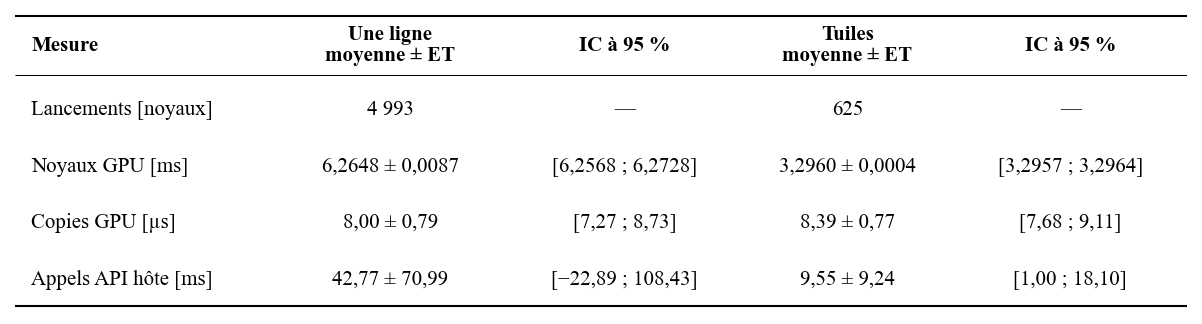

In [13]:
# Répétition indépendante du profilage d’une paire après chauffe.
ns_raw = nv_csv(RES / "repeated/gpu-trace/838775/captures.csv")
assert ns_raw.groupby("variant").block.nunique().eq(7).all()
assert ns_raw.distance.eq(99).all() and ns_raw.groupby("variant").launches.nunique().eq(1).all()
ns_vars = ns_raw.groupby("variant").launches.first().sort_values(ascending=False).index
from studies.comparison_table import booktabs

ns_fig, ns_ax = plt.subplots(figsize=(7.9, 2.05))
ns_rows = []
for ns_domain, ns_name, ns_scale, ns_digits in [
    ("launches", "Lancements [noyaux]", 1, 0),
    ("kernel_ms", "Noyaux GPU [ms]", 1, 4),
    ("copy_ms", "Copies GPU [µs]", 1000, 2),
    ("api_ms", "Appels API hôte [ms]", 1, 2),
]:
    ns_row = [ns_name]
    for ns_var in ns_vars:
        ns_values = ns_raw.loc[ns_raw.variant.eq(ns_var), ns_domain]
        if ns_domain == "launches":
            ns_count = int(ns_values.unique().item())
            nv_stats.add(12, "launches", ns_var, "5k", [ns_count], "exact_capture_count", independent=False)
            ns_row.extend([f"{ns_count:,}".replace(",", " "), "—"])
            continue
        ns_stat = nv_stats.add(12, ns_domain, ns_var, "5k", ns_values, "independent_nsight_process")
        ns_v = {k: f"{v * ns_scale:.{ns_digits}f}".replace(".", ",").replace("-", "−")
                for k, v in ns_stat.items() if k in {"mean", "sd", "low95", "high95"}}
        ns_row.extend([f"{ns_v['mean']} ± {ns_v['sd']}", f"[{ns_v['low95']} ; {ns_v['high95']}]"])
    ns_rows.append(ns_row)
booktabs(ns_ax, ["Mesure", "Une ligne\nmoyenne ± ET", "IC à 95 %", "Tuiles\nmoyenne ± ET", "IC à 95 %"], ns_rows,
         widths=[.22, .20, .20, .18, .20])
nv_save(ns_fig, "gpu/trace_cuda")

*Figure 12.* Sept processus par variante alignent la même paire de 5 000 et 4 992 bases après chauffe. Le nombre de lancements est constant. Les durées indiquent la moyenne, l’écart-type (ET) et l’intervalle de confiance de Student à 95 %.

<sub>Code : [bench/repeated/trace/gpu_trace.py](../bench/repeated/trace/gpu_trace.py), [results/repeated/gpu-trace/838775/captures.csv](../results/repeated/gpu-trace/838775/captures.csv), [results/repeated/gpu-trace/838775/operations.csv](../results/repeated/gpu-trace/838775/operations.csv).</sub>

Les sept captures comptent 4 993 lancements pour le noyau par ligne et 625 pour les tuiles. L’API hôte de la version initiale présente un appel de lot à 203,14 ms. Sa moyenne vaut 42,77 ms avec un écart-type de 70,99 ms. La borne basse de l’IC de Student atteint −22,89 ms. Le chronométrage de l’API hôte comprend les opérations de gestion mémoire et les appels du profileur enregistrés.

La variation de l’ordre de lecture offre une autre observation de la hiérarchie mémoire.

<p><strong><u>Synthèse.</u></strong> Les noyaux cumulent en moyenne 6,265 ms avec un lancement par ligne et 3,296 ms avec les tuiles sur cet alignement.<br>Les durées des copies restent proches de 0,008 ms tandis que les appels hôtes fluctuent.</p>

<a id="localite-gpu"></a>

## Localité des lectures en mémoire globale

<hr>

La figure 13 compare le regroupement des adresses des warps entre les noyaux par ligne et la politique de tuiles.

Pour les adresses en octets $a_t$ des fils actifs d’un warp, le modèle compte $N_s=|\{\lfloor a_t/32\rfloor\}|$ secteurs de 32 octets par instruction logique. Le modèle suppose le découpage des adresses fourni par les noyaux. Il ne connaît ni les résidences en cache ni les transactions HBM.

La sonde rejoue les accès des warps à l’index, à la diagonale, au prédécesseur vertical, au prédécesseur de dernière occurrence et aux écritures globales. La somme des octets des secteurs divisée par le nombre de cases mesure les demandes logiques. La fraction utile compte les mots distincts de quatre octets dans chaque instruction de warp. L’initialisation, les transferts entre hôte et GPU et les lectures en mémoire partagée sont exclus. Un secteur déjà en cache peut être demandé à nouveau par une autre instruction.

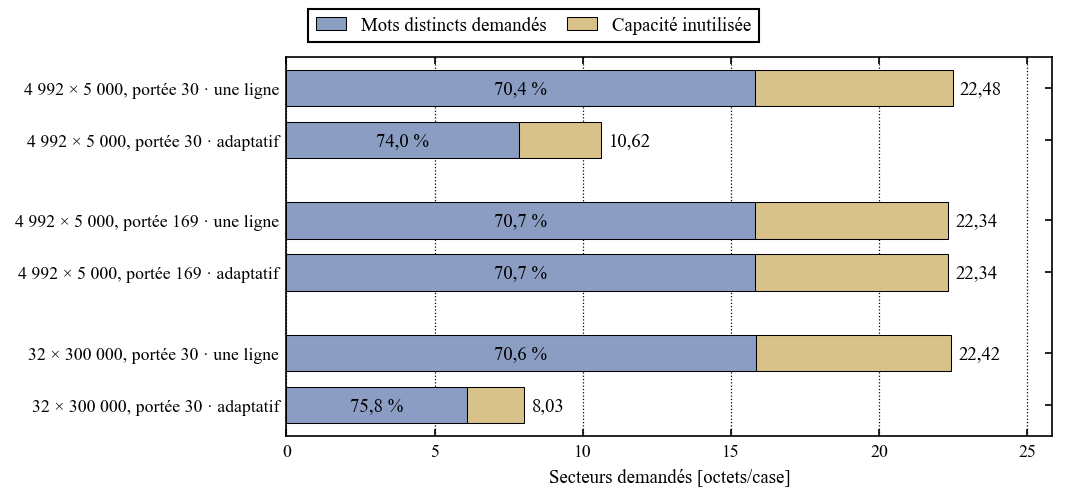

In [14]:
# Secteurs d'adresse demandés par instruction de warp, modèle de 32 octets.
loc_raw = nv_csv(RES / "locality/838447/sectors.csv")
assert set(loc_raw.schedule) == {"adaptive", "single_row"}
assert set(loc_raw.access) == {"mit", "diagonal", "upper", "gather", "store"}
assert loc_raw.groupby("case").distance.nunique().eq(1).all()
loc_tot = loc_raw.groupby(["case", "schedule"])[["sectors32", "distinct_words"]].sum()
loc_dims = loc_raw.groupby("case")[["rows", "columns", "reach"]].first()
loc_cells = loc_dims.rows * loc_dims["columns"]
loc_bytes = (32 * loc_tot.sectors32 / loc_cells).unstack()
loc_fill = (loc_tot.distinct_words / (8 * loc_tot.sectors32)).unstack()
assert loc_fill.ge(0).all().all() and loc_fill.le(1).all().all()
loc_cases = list(loc_dims.sort_values(["columns", "reach"]).index)
loc_labels = [
    f"{int(loc_dims.loc[c, 'rows']):,} × {int(loc_dims.loc[c, 'columns']):,}".replace(",", " ")
    + f"\nportée {int(loc_dims.loc[c, 'reach'])}"
    for c in loc_cases
]
loc_fig, loc_ax = plt.subplots(figsize=(7.0, 3.25))
loc_rows = []
for loc_i, loc_key in enumerate(loc_cases):
    for loc_j, (loc_policy, loc_name) in enumerate([("single_row", "une ligne"), ("adaptive", "adaptatif")]):
        loc_y = loc_i * 2.55 + loc_j
        loc_total = loc_bytes.loc[loc_key, loc_policy]
        loc_share = loc_fill.loc[loc_key, loc_policy]
        loc_used = loc_total * loc_share
        loc_ax.barh(loc_y, loc_used, height=.7, color=COLORS[0], edgecolor=INK, linewidth=.5,
                    label="Mots distincts demandés" if loc_y == 0 else None)
        loc_ax.barh(loc_y, loc_total - loc_used, left=loc_used, height=.7, color=COLORS[3],
                    edgecolor=INK, linewidth=.5, label="Capacité inutilisée" if loc_y == 0 else None)
        loc_ax.text(loc_used/2, loc_y, f"{100*loc_share:.1f} %".replace(".", ","),
                    ha="center", va="center", fontsize=9)
        loc_ax.text(loc_total+.25, loc_y, f"{loc_total:.2f}".replace(".", ","), va="center", fontsize=9)
        loc_dims_text = loc_labels[loc_i].replace("\n", ", ")
        loc_rows.append((loc_y, f"{loc_dims_text} · {loc_name}"))
        nv_stats.add(13, "sector_bytes_per_cell", loc_policy, loc_key, [loc_total],
                     "deterministic_address_model", independent=False)
loc_ax.set(yticks=[v for v, _ in loc_rows], yticklabels=[v for _, v in loc_rows],
           xlabel="Secteurs demandés [octets/case]", xlim=(0, loc_bytes.max().max()*1.15),
           ylim=(loc_rows[-1][0]+.6, -.6))
loc_ax.grid(False, axis="y")
legend_above(loc_fig, [loc_ax], ncol=2)
nv_save(loc_fig, "gpu/localite_gpu")

*Figure 13.* Chaque barre décompose la capacité des secteurs de 32 octets demandés par les instructions des warps. Le pourcentage indique la part occupée par des mots distincts. La valeur en bout de barre rapporte la capacité totale au nombre de cases.

<sub>Code : [bench/gpu/locality/gpu_sectors.cu](../bench/gpu/locality/gpu_sectors.cu), [bench/gpu/locality/gpu_sectors.sbatch](../bench/gpu/locality/gpu_sectors.sbatch), [results/locality/838447/sectors.csv](../results/locality/838447/sectors.csv), [results/locality/838447/requested-metrics.txt](../results/locality/838447/requested-metrics.txt).</sub>

Pour la forme de 4992 × 5000 cases, le calcul adaptatif demande 10,62 octets de secteurs par case, contre 22,48 pour une ligne à la fois. Pour la forme de 32 × 300000 cases, le calcul adaptatif demande 8,03 octets de secteurs par case, contre 22,42 pour une ligne à la fois. Sur le contrôle de grande portée, la récurrence utilise le noyau par ligne. Les deux décomptes de secteurs coïncident. Dans la forme large, les mots distincts remplissent 75,8 % des octets demandés par la politique adaptative. Les compteurs L1 et L2 demandés à Nsight Compute ont renvoyé ERR_NVGPUCTRPERM.

Un étalonnage sur le GH200 situe ensuite le coût de ces transferts et des opérations entières.

<p><strong><u>Synthèse.</u></strong> Sur la forme large, les tuiles divisent par 2,79 les octets de secteurs demandés par case.<br>Ce rapport décrit les adresses du noyau. Le trafic HBM dépend aussi de l’état des caches.</p>

<a id="modele-gh200"></a>

## Débits entiers et modèle mémoire du GH200

<hr>

La figure 14 situe les mises à jour entières du GH200 par rapport aux débits mesurés sur la même puce. Les deux régions homologues du chromosome 21 servent ensuite à tester les variantes CUDA de NvPD.

Un noyau copie des mots en mémoire globale et un autre enchaîne des mises à jour dans les registres. Pour l’intensité $I=U/Q$, nombre de mises à jour $U$ par octet demandé $Q$, le modèle donne $P(I)=\min(B_{\mathrm{copy}}I,P_{\mathrm{reg}})$. L’étalon intermédiaire charge trois tableaux, stocke un quatrième et applique de 1 à 256 mises à jour par élément. Les quantités demandées par le code servent à calculer l’intensité. La mesure physique du trafic DRAM exigerait un compteur matériel. [Williams, Waterman et Patterson, 2009](https://doi.org/10.1145/1498765.1498785)

Le calcul natif évalue ces entrées ligne par ligne. Un deuxième noyau fusionne deux lignes. Le troisième réutilise les données d’un voisinage local pendant plusieurs lignes. Les performances du calcul complet sont exprimées en $mn/(10^9T)$, avec une paire par processus. Accelign, cité à titre de comparaison algorithmique, découpe lui aussi la matrice en tuiles et échange des scores entre registres d’un même warp. Pour l’alignement global, son interface publiée restitue le score. La reconstruction d’un CIGAR complet demande un calcul supplémentaire. [Kallenborn et coll., 2026](https://doi.org/10.1186/s12859-026-06521-0)

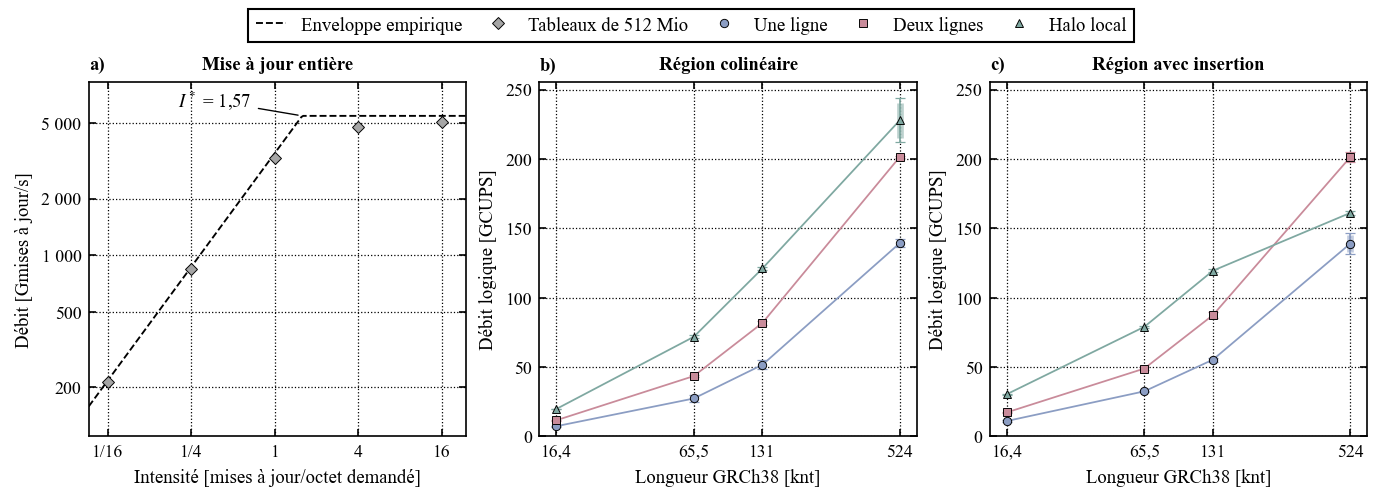

In [15]:
from studies.roofline_gpu import make_figure as gr_make_figure

gr_root = RES / "roofline/gpu"
gr_cal = nv_csv(gr_root / "839177/calibration.csv")
for (gr_method, gr_steps), gr_g in gr_cal.groupby(["method", "steps"]):
    if gr_method == "stream-copy":
        nv_stats.add(
            14,
            "requested_GB_s",
            "copy",
            gr_steps,
            gr_g.requested_bytes / gr_g.seconds / 1e9,
            "fresh_cuda_process",
        )
    else:
        nv_stats.add(
            14,
            "updates_per_ns",
            gr_method,
            gr_steps,
            gr_g.updates / gr_g.seconds / 1e9,
            "fresh_cuda_process",
        )
gr_t = nv_csv(gr_root / "839191/trials.csv")
assert gr_t.groupby(["case", "method"]).block.nunique().eq(5).all()
assert gr_t.groupby("case").distance.nunique().eq(1).all()
for (gr_case, gr_method), gr_g in gr_t.groupby(["case", "method"]):
    nv_stats.add(14, "seconds", gr_method, gr_case, gr_g.seconds, "fresh_warmed_process")
    if gr_method in ("native", "fused", "local"):
        nv_stats.add(
            14, "gcups", gr_method, gr_case, gr_g.m * gr_g.n / gr_g.seconds / 1e9, "fresh_warmed_process"
        )
for gr_case, gr_g in gr_t.groupby("case"):
    gr_pair = gr_g.pivot(index="block", columns="method", values="seconds")
    nv_stats.add(
        14,
        "native_over_local",
        "native/local",
        gr_case,
        gr_pair.native / gr_pair.local,
        "paired_process_block",
    )
gr_c = nv_csv(gr_root / "839198/trials.csv")
for gr_case, gr_g in gr_c.groupby("case"):
    gr_twoclass = gr_g.pivot(index="block", columns="method", values="seconds")
    nv_stats.add(
        14,
        "local_over_classes",
        "local/classes",
        gr_case,
        gr_twoclass.local / gr_twoclass.classes,
        "paired_process_block",
    )
gr_fig = gr_make_figure(ROOT)
nv_save(gr_fig, "gpu/roofline_gh200")

*Figure 14.* Le coude de l’enveloppe empirique indique l’intensité à laquelle les plafonds de bande passante demandée et de mises à jour entières se rejoignent (a). Cinq processus fournissent les débits moyens après chauffe sur les deux régions humaines (b, c). Le débit logique compte les cellules du rectangle initial.

<sub>Code : [bench/gpu/roofline/calibrate.cu](../bench/gpu/roofline/calibrate.cu), [bench/gpu/roofline/trial.cu](../bench/gpu/roofline/trial.cu), [bench/gpu/roofline/traffic.py](../bench/gpu/roofline/traffic.py), [python/studies/roofline_gpu.py](../python/studies/roofline_gpu.py), [results/roofline/gpu/839177/calibration.csv](../results/roofline/gpu/839177/calibration.csv), [results/roofline/gpu/839191/trials.csv](../results/roofline/gpu/839191/trials.csv), [results/roofline/gpu/839198/trials.csv](../results/roofline/gpu/839198/trials.csv), [results/roofline/gpu/839198/activity.csv](../results/roofline/gpu/839198/activity.csv).</sub>

La copie atteint 3 488 Go demandés par seconde en moyenne et le noyau en registres 5 481 milliards de mises à jour par seconde. Leur intersection est à 1,57 mises à jour par octet. Sur la fenêtre de 524 288 bases qui traverse l’écart de chaîne, le rapport entre temps natif et temps avec halo local vaut 1,16 (écart-type 0,05, IC à 95 % de 1,10 à 1,23). Avec le même nombre de bases de GRCh38, le halo local atteint 228 GCUPS dans la région colinéaire et 161 dans la région avec insertion. Sur cette dernière, la fusion de deux lignes atteint 201 GCUPS. Le débit inclut la préparation des données et les synchronisations. Dans un essai complémentaire, le classement des tuiles selon deux tailles de halo ajoute des lancements. Le temps du halo local divisé par celui de la variante à deux classes varie de 0,506 à 0,703 sur les huit fenêtres.

Le choix d’un parcours par fronts de coût pose ensuite la question du nombre de cellules nécessaires.

<p><strong><u>Synthèse.</u></strong> L’enveloppe combine deux microbenchmarks mesurés sur le même GH200.<br>Le débit du score complet est évalué séparément sur huit fenêtres humaines.</p>

<a id="front-gpu"></a>

## Calcul par fronts de coût sur accélérateur

<hr>

La figure 15 compare les durées de trois programmes avec reconstruction du chemin et vérifie le domaine de distance du front GPU.

Pour un chemin d’édition unitaire de coût $s$, toute position $(i,j)$ vérifie $|i-j|\leq s$. Le front $s$ garde la position la plus avancée sur chaque diagonale accessible, puis prolonge les correspondances gratuites. L’implémentation IEEE 2022 testée représente uniquement $d<64$. Elle traite plusieurs paires en lot. [Aguado-Puig et coll., 2022](https://doi.org/10.1109/ACCESS.2022.3182714)

Les trois lots admissibles contiennent cinq préfixes à 2 %, quatre préfixes à 5 % et cinq paires complètes de 5 000 bases à faible distance. Un appel indépendant par configuration donne le score et un chemin. Edlib établit le coût de référence avant la sélection, puis le pilote rejoue le chemin. Les cinq répétitions chronométrent chacune un processus neuf. Le temps du lot annoncé par eWFA-GPU débute après lecture et initialisation de CUDA.

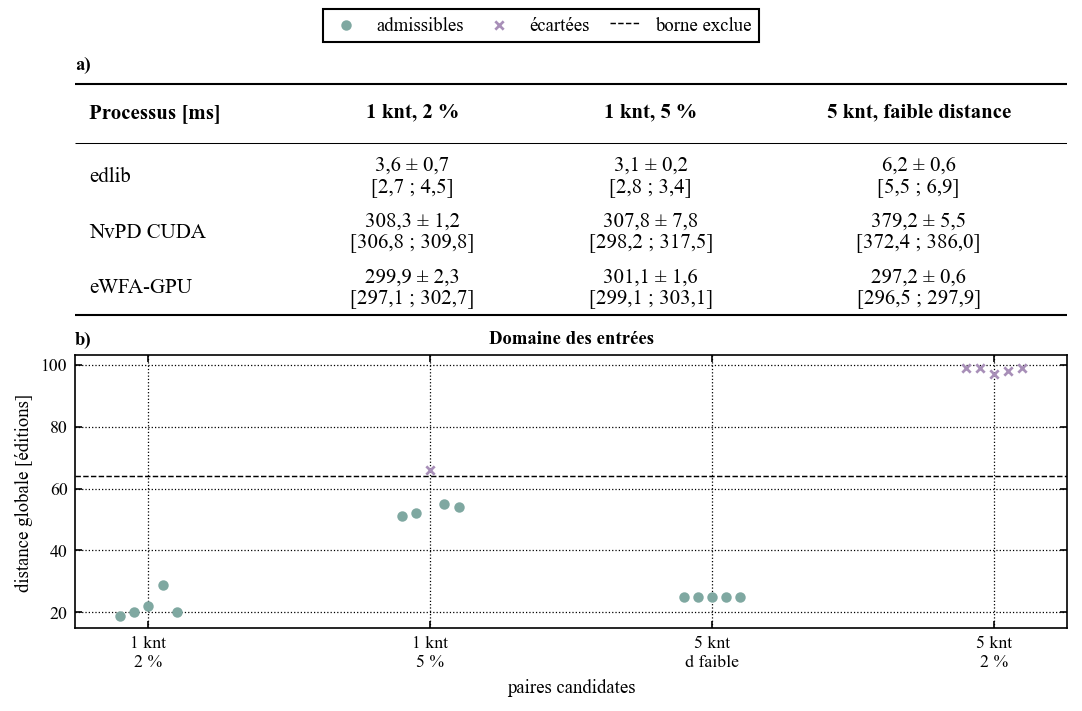

In [16]:
# Temps des processus avec chemin d'alignement et borne de la version IEEE 2022.
ew_dir = RES / "ewfa/838492"
ew_cases = ["1k_prefix_2pct", "1k_prefix_5pct", "5k_full_low"]
ew_raw = nv_csv(ew_dir / "trials.csv")
ew_pairs = nv_csv(ew_dir / "pairs.csv")
ew_ok = ew_pairs[ew_pairs.status.eq("verified")]
assert ew_ok.edlib.eq(pd.to_numeric(ew_ok.gpu_score)).all()
assert ew_ok.edlib.eq(pd.to_numeric(ew_ok.raw_cigar_cost)).all()
assert ew_ok.edlib.lt(64).all() and len(ew_ok) == 14
assert ew_pairs[ew_pairs.status.eq("outside_d_lt_64")].edlib.ge(64).all()
assert ew_raw.groupby(["case", "algorithm"]).trial.nunique().eq(5).all()
from studies.comparison_table import booktabs

ew_fig, ew_ax = plt.subplots(2, 1, figsize=(7.1, 4.65), height_ratios=[.95, 1.10])
ew_table = []
ew_legend = ["1 knt, 2 %", "1 knt, 5 %", "5 knt, faible distance"]
for ew_i, (ew_alg, ew_name) in enumerate(
    [("edlib", "edlib"), ("nvpd-cuda", "NvPD CUDA"), ("ewfa-gpu-2022", "eWFA-GPU")]
):
    ew_time_row = [ew_name]
    for ew_j, ew_case in enumerate(ew_cases):
        ew_values = ew_raw[ew_raw.case.eq(ew_case) & ew_raw.algorithm.eq(ew_alg)].process_seconds * 1000
        ew_res = nv_stats.add(15, "process_ms", ew_alg, ew_case, ew_values, "fresh_process")
        ew_time_row.append((f"{ew_res['mean']:.1f} ± {ew_res['sd']:.1f}\n"
                            f"[{ew_res['low95']:.1f} ; {ew_res['high95']:.1f}]").replace(".", ","))
    ew_table.append(ew_time_row)
booktabs(ew_ax[0], ["Processus [ms]", *ew_legend], ew_table, widths=[.22, .24, .24, .30])
ew_all_cases = [*ew_cases, "5k_full_2pct"]
for ew_i, ew_case in enumerate(ew_all_cases):
    ew_rows = ew_pairs[ew_pairs.case.eq(ew_case)]
    for ew_j, ew_row in enumerate(ew_rows.itertuples()):
        ew_valid = ew_row.status == "verified"
        ew_ax[1].scatter(
            ew_i + 0.05 * (ew_j - (len(ew_rows) - 1) / 2),
            ew_row.edlib,
            marker="o" if ew_valid else "x",
            color=COLORS[2] if ew_valid else COLORS[5],
            label="admissibles" if ew_valid else "écartées",
            zorder=3,
        )
ew_ax[1].axhline(64, **GUIDE, label="borne exclue")
ew_ax[1].set(ylabel="distance globale [éditions]", xlabel="paires candidates")
ew_ax[1].set_xticks(np.arange(4), ["1 knt\n2 %", "1 knt\n5 %", "5 knt\nd faible", "5 knt\n2 %"])
label_panels(ew_ax)
column_titles([ew_ax[1]], ["Domaine des entrées"])
legend_above(ew_fig, [ew_ax[1]], ncol=3)
nv_save(ew_fig, "gpu/front_gpu")

*Figure 15.* Cinq processus indépendants par lot et par outil suivent un processus de chauffe. Les temps muraux, démarrage et chemin compris, sont résumés par la moyenne, l’écart-type et l’IC à 95 % (a). Les distances des paires candidates situent la borne stricte de cette version d’eWFA-GPU (b).

<sub>Code : [bench/gpu/ewfa/ewfa_measure.py](../bench/gpu/ewfa/ewfa_measure.py), [bench/gpu/ewfa/ewfa_batch.cpp](../bench/gpu/ewfa/ewfa_batch.cpp), [bench/gpu/ewfa/ewfa_validation.patch](../bench/gpu/ewfa/ewfa_validation.patch), [results/ewfa/838492/trials.csv](../results/ewfa/838492/trials.csv), [results/ewfa/838492/pairs.csv](../results/ewfa/838492/pairs.csv).</sub>

Sur le lot des préfixes à 2 %, le processus eWFA-GPU dure en moyenne 299,9 (écart-type 2,3, IC 95 % de 297,1 à 302,7) ms. Le chronomètre interne d’amont commence après la lecture et l’initialisation du contexte. Les chemins binaires ont été rejoués pour chaque paire admissible. Le formateur texte de la livraison amont modifie le CIGAR lors de son affichage.

Les lots permettent aussi de distinguer le lancement du processus et le coût des allocations successives.

<p><strong><u>Synthèse.</u></strong> La livraison IEEE de 2022 accepte 14 des 20 paires proposées avec sa borne stricte de 64 éditions.<br>Les lots de quatre ou cinq paires évaluent surtout le coût de démarrage.</p>

<a id="allocations-cuda"></a>

## Réutilisation des tampons entre alignements

<hr>

La figure 16 montre dans quelles collections la réutilisation des tableaux GPU réduit le coût des allocations.

Pour le lot $b$ et la répétition $r$, le gain apparié vaut $S_{b,r}=T_{b,r}^{\rm normal}/T_{b,r}^{\rm reuse}$. Le point représente la moyenne des trois rapports. Chaque exécution comprend la première allocation et la libération finale.

Le premier mode réserve et libère les deux tableaux CUDA pour chaque paire. Le second les conserve lorsque leurs tailles restent identiques. Trois lots synthétiques contiennent des séquences de même longueur. Le quatrième contient 64 génomes de φX174 de longueurs variables. L’oracle edlib et l’appel de chauffe précèdent chaque lot. Chaque mode tourne dans un processus neuf et l’ordre alterne entre les répétitions.

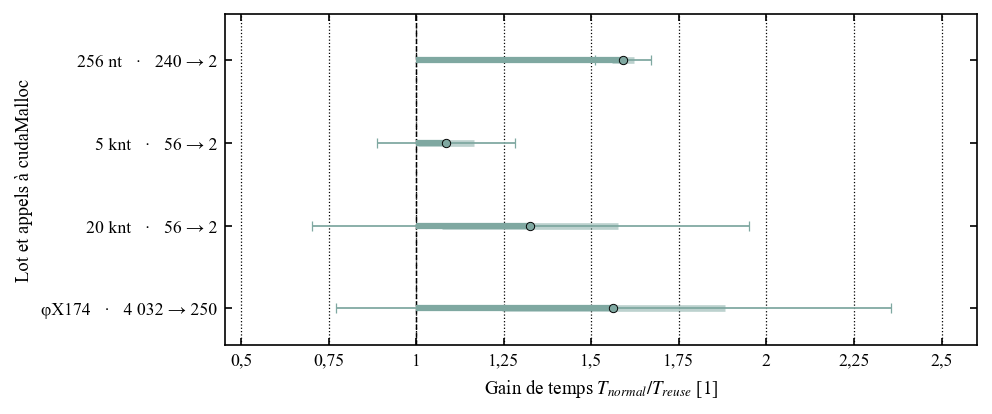

In [17]:
# Comparaison appariée sur des lots contrôlés, hors capture Nsight.
pool_alloc = nv_csv(RES / "allocator/trials.csv")
assert set(pool_alloc["mode"]) == {"normal", "reuse"}
assert set(pool_alloc["case"]) == {"fixed-256", "fixed-5000", "fixed-20000", "phix174"}
assert pool_alloc.groupby(["case", "trial"]).size().eq(2).all()
assert pool_alloc.groupby(["case", "mode"]).trial.nunique().eq(3).all()
for pool_column in ["distance_fnv64", "input_sha256", "pairs", "peak_live_bytes"]:
    assert pool_alloc.groupby("case")[pool_column].nunique().eq(1).all()
assert pool_alloc.malloc_calls.eq(pool_alloc.free_calls).all()
assert pool_alloc.groupby("case").peak_reserved_bytes.nunique().eq(1).all()
assert pool_alloc.malloc_calls.add(pool_alloc.reuse_hits).eq(2 * pool_alloc.pairs).all()
pool_ab = pool_alloc.pivot(index=["case", "trial"], columns="mode", values="seconds")
pool_cases = ["fixed-256", "fixed-5000", "fixed-20000", "phix174"]
pool_x = np.arange(len(pool_cases))
pool_labels = ["256 nt", "5 knt", "20 knt", "φX174"]
pool_fig, pool_ax = plt.subplots(figsize=(6.5, 2.65))
pool_ratio = (pool_ab.normal / pool_ab.reuse).droplevel("trial")
pool_rows = []
for pool_idx, pool_case in enumerate(pool_cases):
    pool_calls = pool_alloc[pool_alloc.case.eq(pool_case)].groupby("mode").malloc_calls
    assert pool_calls.nunique().eq(1).all()
    pool_normal, pool_reused = pool_calls.first().reindex(["normal", "reuse"])
    pool_counts = f"{pool_normal:,} → {pool_reused:,}".replace(",", " ")
    pool_rows.append(f"{pool_labels[pool_idx]}   ·   {pool_counts}")
    pool_stat = nv_stats.add(16, "paired_speedup", "normal/reuse", pool_case,
                             pool_ratio.loc[pool_case], "paired_process_block")
    pool_ax.hlines(pool_idx, 1, pool_stat["mean"], color=COLORS[2], linewidth=3)
    estimate(pool_ax, pool_idx, pool_stat, COLORS[2], horizontal=True)
pool_ax.axvline(1, **GUIDE)
category_rows(pool_ax, pool_rows, r"Gain de temps $T_{normal}/T_{reuse}$ [1]")
pool_ax.set_ylabel("Lot et appels à cudaMalloc")
pool_ticks = np.arange(0.5, pool_ax.get_xlim()[1], 0.25)
pool_ax.set_xticks(pool_ticks, [f"{v:g}".replace(".", ",") for v in pool_ticks])
nv_save(pool_fig, "gpu/allocations_cuda")

*Figure 16.* Le gain de temps compare les deux politiques dans chacun des trois blocs appariés après chauffe. Pour chaque lot, les deux décomptes à gauche donnent les appels à cudaMalloc sans puis avec réutilisation.

<sub>Code : [bench/gpu/allocation/allocator_probe.cu](../bench/gpu/allocation/allocator_probe.cu), [bench/gpu/allocation/allocator_measure.py](../bench/gpu/allocation/allocator_measure.py), [results/allocator/trials.csv](../results/allocator/trials.csv), [results/allocator/production.csv](../results/allocator/production.csv).</sub>

Pour les 2 016 paires de phages, le gain moyen de la sonde d’allocation vaut 1,56 (écart-type 0,32, IC 95 % de 0,77 à 2,35). Le double tampon persistant réduit les allocations physiques de 4 032 à 250. Le pic explicite reste de 150 892 octets dans les deux modes pour ce lot.

Un autre portage permet d’évaluer le coût de la même récurrence dans un espace d’exécution générique.

<p><strong><u>Synthèse.</u></strong> Deux tampons de même taille peuvent servir aux paires successives d’un lot.<br>Le nombre d’allocations dépend des changements de longueur dans l’ordre des 2 016 paires.</p>

<a id="kokkos"></a>

## Portabilité de la récurrence avec Kokkos

<hr>

La figure 17 évalue deux implémentations de NvPD utilisant la même cible matérielle.

À matériel et séquences fixés, le rapport $T_{\rm Kokkos}/T_{\rm native}$ inclut les choix de noyau et le mode de lancement. Chaque processus réalise un appel de chauffe avant l’appel chronométré. [Edwards, Trott et Sunderland, 2014](https://doi.org/10.1016/j.jpdc.2014.07.003)

Un espace d’exécution Kokkos choisit où se déroule une boucle. Le même programme source peut soumettre une ligne de NvPD à OpenMP sur CPU ou à CUDA sur GPU. Dans ce portage, une `RangePolicy` distribue les colonnes de chaque ligne et une barrière `fence` précède la récupération du score. Sur GPU, le noyau Kokkos de cette campagne synthétique suit la récurrence ligne par ligne. La version CUDA native peut regrouper huit lignes en tuiles. Un processus neuf effectue un appel de chauffe puis un appel chronométré, allocations et transferts compris. Les deux implémentations alternent leur ordre entre les trois répétitions sur les mêmes entrées. Le GPU utilise CUDA 12.6.3 et l’espace d’exécution `Kokkos::Cuda`. [Boucles parallèles Kokkos](https://kokkos.org/kokkos-core-wiki/API/core/parallel-dispatch/parallel_for.html) · [Synchronisation Kokkos](https://kokkos.org/kokkos-core-wiki/API/core/parallel-dispatch/fence.html)

Trois allocations du même nœud EPYC et trois du même GH200 fournissent la répétition. Pour chaque variante et chaque taille, la moyenne de trois processus dans une allocation constitue une observation. L’échantillon renseigne les variations entre réservations de ces nœuds.

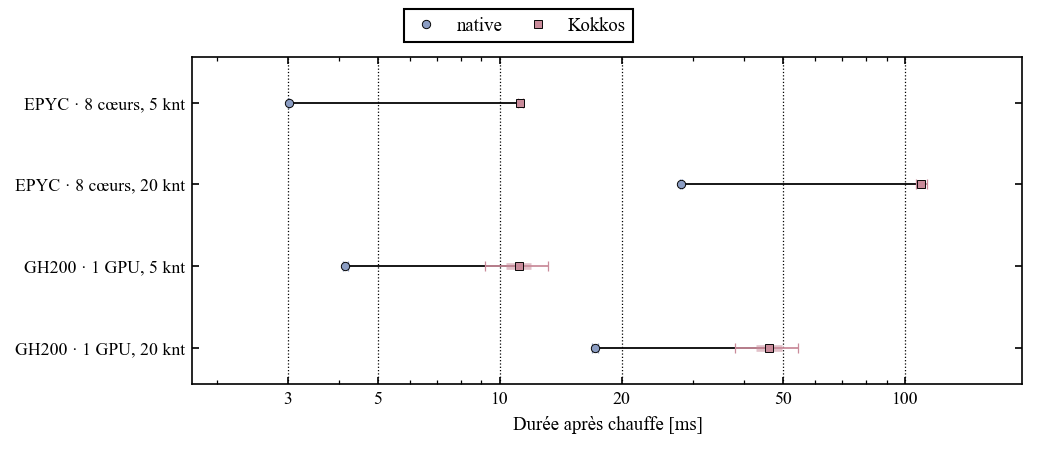

In [18]:
# Coût du portage Kokkos par rapport à l'implémentation native de chaque cible.
ko_raw = nv_csv(RES / "kokkos/timings.csv")
assert ko_raw.distance.eq(ko_raw.reference_distance).all()
ko_repeat = nv_csv(RES / "kokkos/replications/trials.csv")
ko_raw = pd.concat([ko_raw, ko_repeat], ignore_index=True)
assert ko_raw.distance.eq(ko_raw.reference_distance).all()
assert not ko_raw.duplicated(["job", "target", "threads", "m", "algorithm", "trial"]).any()
ko_fig, ko_ax = plt.subplots(figsize=(6.8, 2.9))
ko_rows = []
for ko_i, (ko_target, ko_native) in enumerate([("cpu", "nvpd-omp"), ("gpu", "nvpd-cuda")]):
    ko_sub = ko_raw[ko_raw.target.eq(ko_target)]
    ko_sub = ko_sub[ko_sub.threads.eq(ko_sub.threads.max())]
    assert ko_sub.groupby(["m", "algorithm"]).trial.nunique().eq(3).all()
    assert ko_sub.groupby("m").input_sha256.nunique().eq(1).all()
    for ko_y, ko_size in enumerate([5000, 20000]):
        ko_entries = []
        for ko_j, ko_alg in enumerate([ko_native, "nvpd-kokkos"]):
            ko_select = ko_sub[ko_sub.algorithm.eq(ko_alg) & ko_sub.m.eq(ko_size)]
            assert ko_select.groupby("job").size().eq(3).all() and ko_select.job.nunique() == 3
            ko_values = ko_select.groupby("job").seconds.mean() * 1000
            ko_unit = "allocation_mean_of_three_processes"
            ko_res = nv_stats.add(17, "ms_" + ko_target, ko_alg, ko_size, ko_values, ko_unit)
            ko_entries.append((ko_res, COLORS[ko_j], "os"[ko_j], ["native", "Kokkos"][ko_j]))
        comparison(ko_ax, 2 * ko_i + ko_y, ko_entries, annotate=False)
        ko_rows.append(f"{'EPYC · 8 cœurs' if ko_target == 'cpu' else 'GH200 · 1 GPU'}, {ko_size // 1000} knt")
ko_ax.set_xscale("log")
ko_ax.set_xticks([3, 5, 10, 20, 50, 100], ["3", "5", "10", "20", "50", "100"])
category_rows(ko_ax, ko_rows, "Durée après chauffe [ms]")
legend_above(ko_fig, [ko_ax], ncol=2)
nv_save(ko_fig, "distributed/portage_kokkos")

*Figure 17.* Une ligne réunit la version native et Kokkos sur une même paire. Sur chaque plateforme, les points résument trois allocations du même nœud. Chaque allocation fournit la moyenne de trois processus préchauffés par méthode et par taille. Les barres représentent la dispersion et l’IC entre ces trois moyennes.

<sub>Code : [bench/kokkos/kokkos_measure.py](../bench/kokkos/kokkos_measure.py), [results/kokkos/timings.csv](../results/kokkos/timings.csv), [results/kokkos/checks.csv](../results/kokkos/checks.csv), [results/kokkos/replications/trials.csv](../results/kokkos/replications/trials.csv).</sub>

Sur huit cœurs EPYC à 20 knt, le backend OpenMP natif prend 27,95 (écart-type 0,04, IC 95 % de 27,86 à 28,05) ms et l’espace Kokkos OpenMP 109,53 ms. Sur GH200, les temps moyens respectifs valent 17,18 et 46,23 ms.

Deux régions homologues du chromosome 21 permettent de tester ces choix sur des entrées de longueurs et de divergences différentes.

<p><strong><u>Synthèse.</u></strong> Les deux espaces d’exécution retrouvent les mêmes distances sur les paires de 5 et 20 knt.<br>Pour ces tailles, les implémentations natives prennent moins de temps sur les deux cibles.</p>

<a id="kokkos-chromosome"></a>

## Portabilité de NvPD sur deux régions homologues

<hr>

La figure 18 mesure la portabilité de deux changements de noyau sur des fenêtres homologues du chromosome 21.

Le premier locus, centré sur la position 37 400 000 de GRCh38, suit une région colinéaire avec CHM13. Le second, centré sur 33 474 775, traverse un écart de chaîne de 9 540 bases du côté CHM13. Les bornes appartiennent à la même chaîne d’alignement. À 16 384 bases, le coût relatif atteint 0,085 % et 36,9 % sur les deux fenêtres. La divergence observée est $d/\max(m,n)$ et le travail dense vaut $mn$. Les deux bibliothèques de référence vérifient le score global.

Le noyau Kokkos initial soumet une boucle par ligne. Sur EPYC, la version optimisée conserve l’équipe de fils et synchronise les colonnes à chaque changement de ligne. Sur GH200, la version optimisée fusionne deux lignes. Chaque fil recalcule les prédécesseurs intermédiaires nécessaires à sa colonne. La portée maximale de la dernière occurrence dépasse 64 sur les dix entrées, de 86 à 1 813. Le noyau CUDA natif y traite une ligne à la fois. Le rapport $T_{native}/T_{Kokkos}$ est calculé à l’intérieur de chaque bloc. Une valeur supérieure à 1 indique un temps plus court pour la méthode Kokkos.

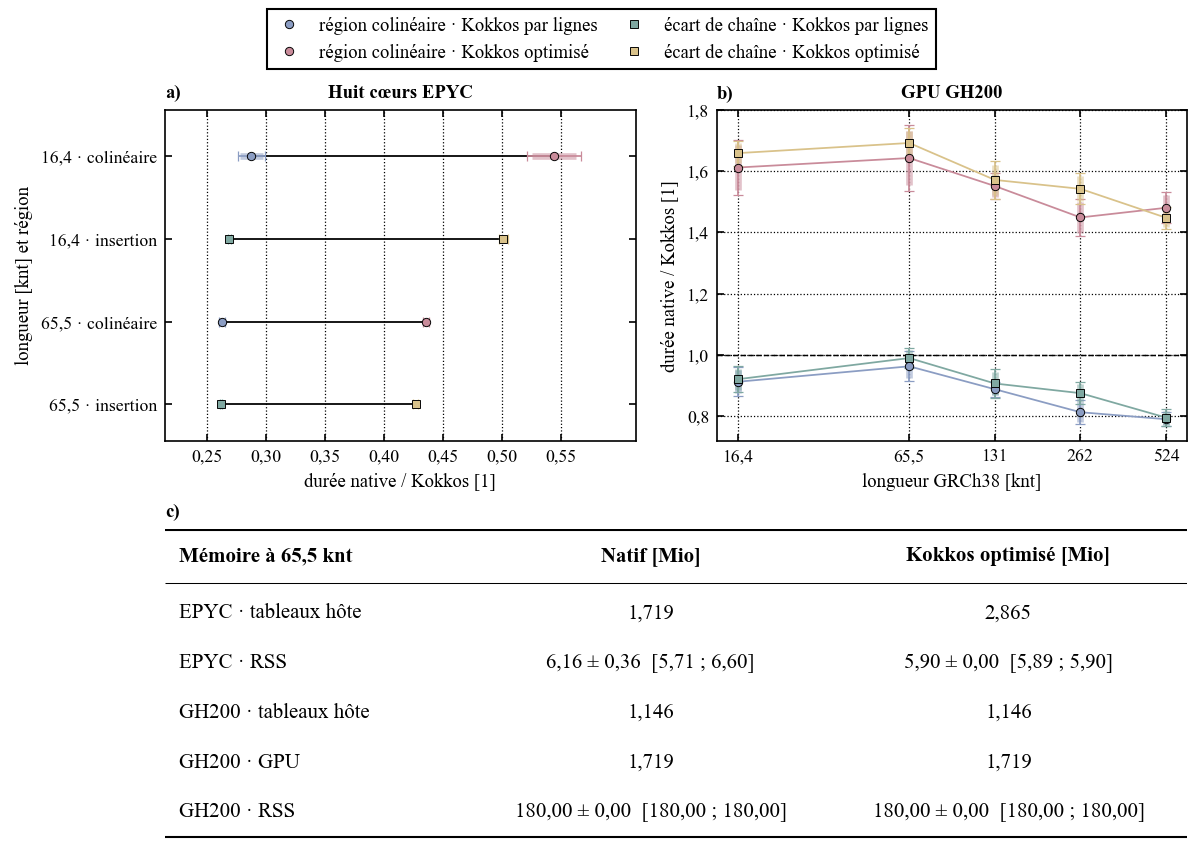

In [19]:
# Un bloc associe les trois méthodes sur une même fenêtre et une même cible.
kh_raw = nv_csv(RES / "kokkos/human/trials.csv")
kh_inputs = nv_csv(RES / "kokkos/human/inputs.csv")
kh_cases = kh_raw.merge(
    kh_inputs[["case", "input_sha256"]].drop_duplicates(),
    on=["case", "input_sha256"],
    validate="many_to_one",
)
assert len(kh_cases) == len(kh_raw)
assert kh_cases.groupby("case").distance.nunique().eq(1).all()
assert kh_cases.seconds.gt(0).all()
kh_references = nv_csv(RES / "kokkos/human/references.csv").set_index("case")
assert kh_cases.distance.eq(kh_cases["case"].map(kh_references.distance)).all()
assert kh_cases.cells.eq(kh_cases.m * kh_cases.n).all()
assert not kh_cases.duplicated(["target", "case", "workers", "block", "algorithm"]).any()
kh_methods = ["native", "kokkos-rows", "kokkos-opt"]
kh_labels = ["native", "Kokkos par lignes", "Kokkos optimisé"]
kh_reach = nv_csv(RES / "kokkos/human/reach.csv").set_index("case")
assert kh_cases["input_sha256"].eq(kh_cases["case"].map(kh_reach.input_sha256)).all()
assert kh_reach.maximum_match_reach.gt(64).all() and kh_reach.native_cuda_path.eq("one row").all()
for (kh_target, kh_workers, kh_case), kh_group in kh_cases.groupby(["target", "workers", "case"]):
    kh_pairs = kh_group.pivot(index="block", columns="algorithm", values="seconds")
    assert len(kh_pairs) == 5 and kh_pairs.notna().all().all()
    nv_stats.add(
        18,
        "rows_over_opt",
        f"{kh_target}/{kh_workers}",
        kh_case,
        kh_pairs["kokkos-rows"] / kh_pairs["kokkos-opt"],
        "paired_process_block",
    )
kh_regions = [("collinear", "région colinéaire"), ("insertion", "écart de chaîne")]
from studies.comparison_table import booktabs

kh_fig = plt.figure(figsize=(7.9, 5.6))
kh_grid = kh_fig.add_gridspec(2, 2, height_ratios=[1.07, 1])
kh_axes = [kh_fig.add_subplot(kh_grid[0, 0]), kh_fig.add_subplot(kh_grid[0, 1]),
           kh_fig.add_subplot(kh_grid[1, :])]
for kh_id, kh_platform in enumerate(("epyc", "gh200")):
    kh_platform_rows = kh_cases[kh_cases.target.eq(kh_platform)]
    kh_selected = kh_platform_rows[kh_platform_rows.workers.eq(kh_platform_rows.workers.max())]
    kh_size_values = sorted(kh_selected.m.unique())
    for kh_reg_i, (kh_region, kh_display) in enumerate(kh_regions):
        kh_zone = kh_selected[kh_selected.region.eq(kh_region)]
        for kh_alg_i, kh_method in enumerate(kh_methods):
            kh_serie = kh_zone[kh_zone.algorithm.eq(kh_method)].copy()
            for kh_length, kh_group in kh_serie.groupby("m"):
                kh_unit = f"{kh_platform}/{kh_region}/{kh_method}"
                assert (
                    kh_group.device_bytes.nunique() == 1
                    and kh_group.host_workspace_array_bytes.nunique() == 1
                )
                nv_stats.add(
                    18,
                    "explicit_device_bytes",
                    kh_unit,
                    kh_length,
                    [kh_group.device_bytes.iloc[0]],
                    "buffer_size",
                    independent=False,
                )
                nv_stats.add(
                    18,
                    "host_array_bytes",
                    kh_unit,
                    kh_length,
                    [kh_group.host_workspace_array_bytes.iloc[0]],
                    "buffer_size",
                    independent=False,
                )
                nv_stats.add(18, "seconds", kh_unit, kh_length, kh_group.seconds, "fresh_warmed_process")
                nv_stats.add(
                    18,
                    "gcups",
                    kh_unit,
                    kh_length,
                    kh_group.m * kh_group.n / (kh_group.seconds * 1e9),
                    "fresh_warmed_process",
                )
            if kh_method == "native":
                continue
            kh_pivot = kh_zone.pivot(index=["m", "block"], columns="algorithm", values="seconds")
            kh_ratio = (kh_pivot["native"] / kh_pivot[kh_method]).droplevel("block")
            if kh_platform == "epyc":
                kh_y = [2 * kh_pos + kh_reg_i for kh_pos in range(len(kh_size_values))]
                nv_plot(
                    kh_axes[0],
                    kh_ratio,
                    kh_size_values,
                    kh_y,
                    18,
                    "native_over_kokkos",
                    f"{kh_platform}/{kh_region}/{kh_method}",
                    "paired_process_block",
                    COLORS[2 * kh_reg_i + kh_alg_i - 1],
                    "os"[kh_reg_i],
                    horizontal=True,
                    label=kh_display + " · " + kh_labels[kh_alg_i],
                )
            else:
                nv_plot(
                    kh_axes[1],
                    kh_ratio,
                    kh_size_values,
                    kh_size_values,
                    18,
                    "native_over_kokkos",
                    f"{kh_platform}/{kh_region}/{kh_method}",
                    "paired_process_block",
                    COLORS[2 * kh_reg_i + kh_alg_i - 1],
                    "os"[kh_reg_i],
                    joined=True,
                    label=kh_display + " · " + kh_labels[kh_alg_i],
                )
    if kh_platform == "epyc":
        for kh_pos, kh_size in enumerate(kh_size_values):
            for kh_reg_i, (kh_region, kh_display) in enumerate(kh_regions):
                kh_durations = kh_selected[kh_selected.region.eq(kh_region) & kh_selected.m.eq(kh_size)]
                kh_block = kh_durations.pivot(index="block", columns="algorithm", values="seconds")
                kh_bounds = [(kh_block.native / kh_block[v]).mean() for v in kh_methods[1:]]
                join(kh_axes[0], [2 * kh_pos + kh_reg_i] * 2, kh_bounds, INK, horizontal=True)
        category_rows(
            kh_axes[0],
            ["16,4 · colinéaire", "16,4 · insertion", "65,5 · colinéaire", "65,5 · insertion"],
            "durée native / Kokkos [1]",
        )
        kh_axes[0].set_ylabel("longueur [knt] et région")
        kh_axes[0].set_xticks([0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55])
    else:
        kh_axes[1].axhline(1, **GUIDE)
        kh_axes[1].set(xscale="log", xlabel="longueur GRCh38 [knt]", ylabel="durée native / Kokkos [1]")
        kh_axes[1].set_xticks(kh_size_values, ["16,4", "65,5", "131", "262", "524"])
        kh_axes[1].set_yticks([0.8, 1, 1.2, 1.4, 1.6, 1.8])
kh_profile = nv_csv(RES / "kokkos/human/profile.csv")
assert kh_profile.input_sha256.eq(kh_profile["case"].map(kh_reach.input_sha256)).all()
for kh_row in kh_profile.itertuples(index=False):
    nv_stats.add(
        18,
        "profile_kernel_ms",
        kh_row.algorithm,
        kh_row.case,
        [kh_row.kernel_seconds * 1000],
        "single_nsys_capture",
        independent=False,
    )
    nv_stats.add(
        18,
        "launches",
        kh_row.algorithm,
        kh_row.case,
        [kh_row.kernel_launches],
        "single_nsys_capture",
        independent=False,
    )
# Les tableaux explicites et le pic RSS décrivent deux grandeurs distinctes.
kh_mem = kh_cases[kh_cases.m.eq(65536) & kh_cases.region.eq("insertion")]
kh_parts = [
    ("epyc", "host_workspace_array_bytes", "EPYC · tableaux hôte"),
    ("epyc", "peak_rss_kib", "EPYC · RSS"),
    ("gh200", "host_workspace_array_bytes", "GH200 · tableaux hôte"),
    ("gh200", "device_bytes", "GH200 · GPU"),
    ("gh200", "peak_rss_kib", "GH200 · RSS"),
]
kh_table = []
for kh_i, (kh_platform, kh_metric, kh_name) in enumerate(kh_parts):
    kh_entries = []
    for kh_j, kh_method in enumerate(["native", "kokkos-opt"]):
        kh_view = kh_mem[kh_mem.target.eq(kh_platform) & kh_mem.algorithm.eq(kh_method)]
        kh_view = kh_view[kh_view.workers.eq(kh_view.workers.max())]
        if kh_metric == "peak_rss_kib":
            kh_vals = kh_view.peak_rss_kib / 1024
            kh_sample_unit = "fresh_warmed_process"
        else:
            kh_vals = [kh_view[kh_metric].unique().item() / 2**20]
            kh_sample_unit = "buffer_size"
        kh_record = nv_stats.add(
            18,
            kh_metric + "_mib",
            kh_platform + "/" + kh_method,
            "insertion_65536",
            kh_vals,
            kh_sample_unit,
            independent=kh_metric == "peak_rss_kib",
        )
        if kh_metric == "peak_rss_kib":
            kh_cell = (f"{kh_record['mean']:.2f} ± {kh_record['sd']:.2f}  "
                       f"[{kh_record['low95']:.2f} ; {kh_record['high95']:.2f}]")
        else:
            kh_cell = f"{kh_record['mean']:.3f}"
        kh_entries.append(kh_cell.replace(".", ","))
    kh_table.append([kh_name, *kh_entries])
booktabs(kh_axes[2], ["Mémoire à 65,5 knt", "Natif [Mio]", "Kokkos optimisé [Mio]"], kh_table,
         widths=[.30, .35, .35])
label_panels(kh_axes)
column_titles(kh_axes[:2], ("Huit cœurs EPYC", "GPU GH200"))
legend_above(kh_fig, kh_axes[:2], ncol=2)
nv_save(kh_fig, "distributed/kokkos_humain")

*Figure 18.* Les panneaux a) et b) rapportent le temps natif au temps Kokkos dans chaque bloc pour une même fenêtre. Le tableau c) porte sur une fenêtre de 65 536 bases avec insertion. Il distingue les tailles des tableaux et le pic RSS du processus, résumé par sa moyenne, son écart-type et son IC à 95 %.

<sub>Code : [src/kokkos/kokkos.cpp](../src/kokkos/kokkos.cpp), [bench/kokkos/human/measure.py](../bench/kokkos/human/measure.py), [results/kokkos/human/inputs.csv](../results/kokkos/human/inputs.csv), [results/kokkos/human/references.csv](../results/kokkos/human/references.csv), [results/kokkos/human/reach.csv](../results/kokkos/human/reach.csv), [results/kokkos/human/profile.csv](../results/kokkos/human/profile.csv), [results/kokkos/human/trials.csv](../results/kokkos/human/trials.csv).</sub>

À huit cœurs EPYC sur la fenêtre colinéaire de 65,5 knt, le rapport des temps entre la version par lignes et l’équipe persistante vaut 1,66 (écart-type 0,01, IC à 95 % de 1,65 à 1,66). Sur la plus longue fenêtre avec écart de chaîne, le rapport entre ces deux versions sur GH200 vaut 1,82 (écart-type 0,03, IC à 95 % de 1,78 à 1,86). Le noyau à deux lignes prend 1,376 s en moyenne sur cette paire, soit 204,8 GCUPS. Sur la fenêtre colinéaire de 65 536 bases, une capture Nsight Systems indépendante compte 65 537 lancements dans la version par lignes et 32 769 dans le noyau fusionné. Les noyaux cumulent respectivement 95,83 et 64,06 ms dans cette capture. Le noyau natif est plus rapide sur EPYC. Sur GH200, le rapport natif/Kokkos optimisé est compris entre 1,45 et 1,69 sur ces dix entrées. Les points relatifs à un locus décrivent des fenêtres emboîtées du même chromosome.

La distribution sur plusieurs nœuds ajoute la communication entre rangs.

<p><strong><u>Synthèse.</u></strong> Le noyau d’équipe persistante et le noyau GPU à deux lignes réduisent tous deux le temps de la version par lignes.<br>Les gains appariés vont de 1,50 à 1,89 sur EPYC et de 1,71 à 1,87 sur GH200 pour les deux régions étudiées.</p>

<a id="mpi-fort"></a>

## Passage à l’échelle fort entre nœuds

<hr>

La figure 19 compare les communications d’une paire distribuée à celles d’une collection de paires indépendantes.

Pour aligner une seule paire, chaque rang MPI conserve une bande de colonnes. À chaque ligne, il partage deux scores entiers avec tous les rangs pour résoudre les dépendances qui traversent une frontière. L’expérience affecte 24 rangs de huit fils OpenMP à chaque nœud. Pour une collection, le programme distribue des paires indépendantes entre les rangs puis entre les fils OpenMP. Une seule réduction finale réunit les distances. Un nœud compte 192 cœurs actifs et deux nœuds en comptent 384 avec la même disposition des équipes. [Implémentation distribuée](../src/mpi/mpi.cpp) · [Norme MPI, opérations collectives](https://www.mpi-forum.org/docs/mpi-4.1/mpi41-report/mpi41-report.htm)

Les mesures à un et deux nœuds utilisent les mêmes séquences dans une réservation exclusive. Chaque essai commence après une barrière, puis le pilote conserve la durée du rang le plus lent. Le rapport $S=T_1/T_2$ donne le gain du second nœud. L’efficacité de ce doublement est $S/2$. Les sept blocs indépendants changent l’ordre des configurations. Chaque lancement effectue deux calculs de chauffe et une mesure.

MPI définit les communications collectives entre processus. Allgather distribue à chaque rang les données fournies par tous les autres rangs. [MPI Forum, spécification](https://www.mpi-forum.org/docs/mpi-4.1/mpi41-report/mpi41-report.htm)

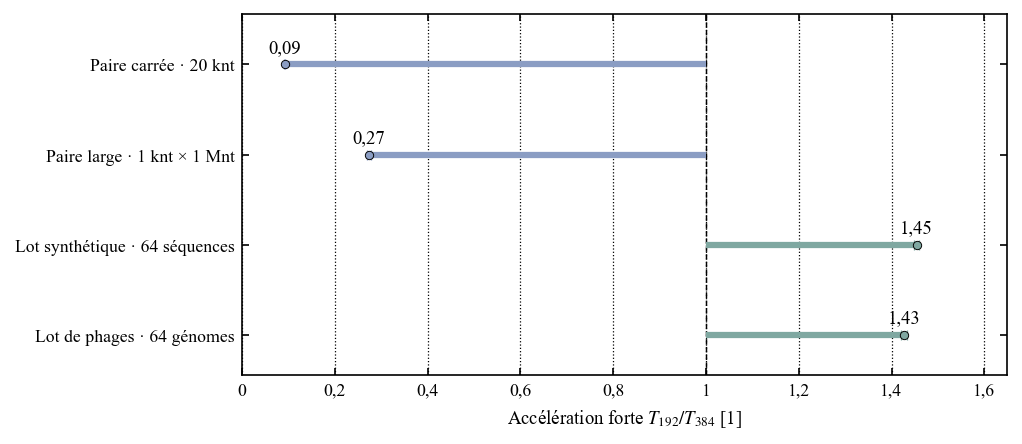

In [20]:
# Passage à l’échelle fort entre lancements indépendants.
mp_cases = {
    "square": "paire\n20 k × 20 k",
    "wide": "paire\n1 k × 1 M",
    "synthetic64": "64 séquences\nsynthétiques",
    "phix64": "64 phages\nφX174",
}
mp_x = np.arange(len(mp_cases))
# Contrôle du second essai sur un seul nœud, chronométré du lancement à la sortie.
mp_cli = nv_csv(RES / "profile/matrix-omp/838652/trials.csv")
assert mp_cli.threads.eq(8).all() and mp_cli.pairs.eq(120).all()
assert mp_cli.input_sha256.nunique() == mp_cli.matrix_sha256.nunique() == 1
mp_cli_wall = mp_cli.pivot(index="trial", columns="layout", values="wall_seconds")
assert mp_cli_wall.shape == (5, 2) and mp_cli_wall.notna().all().all()
mp_cli_gain = nv_stats.add(
    19,
    "single_node_gain",
    "intra/inter",
    "120_pairs",
    mp_cli_wall["intra"] / mp_cli_wall["inter"],
    "paired_process_block",
)
mp_repeat = nv_csv(RES / "mpi/scaling/trials.csv")
mp_repeat = mp_repeat[mp_repeat.study.eq("strong")]
assert mp_repeat.groupby(["case", "nodes"]).block.nunique().eq(7).all()
assert mp_repeat.physical_cores.eq(192 * mp_repeat.nodes).all()
mp_pair = mp_repeat.pivot(index=["case", "block"], columns="nodes", values="seconds")
mp_paired = (mp_pair[1] / mp_pair[2]).droplevel("block")
mp_fig, mp_ax = plt.subplots(figsize=(6.7, 2.85))
mp_names = ["Paire carrée · 20 knt", "Paire large · 1 knt × 1 Mnt", "Lot synthétique · 64 séquences", "Lot de phages · 64 génomes"]
for mp_row, mp_case in enumerate(mp_cases):
    for mp_n in [1, 2]:
        mp_vals = mp_repeat[mp_repeat.case.eq(mp_case) & mp_repeat.nodes.eq(mp_n)].seconds * 1000
        nv_stats.add(19, "milliseconds", str(mp_n), mp_case, mp_vals, "independent_mpirun")
    mp_rat = nv_stats.add(19, "ratio", "1/2", mp_case, mp_paired.loc[mp_case], "paired_mpirun_block")
    mp_color = COLORS[0 if mp_row < 2 else 2]
    mp_ax.hlines(mp_row, 1, mp_rat["mean"], color=mp_color, linewidth=3)
    estimate(mp_ax, mp_row, mp_rat, mp_color, horizontal=True)
    mp_ax.annotate(f"{mp_rat['mean']:.2f}".replace(".", ","), (mp_rat["mean"], mp_row),
                   xytext=(0, 6), textcoords="offset points", ha="center", fontsize=9)
category_rows(mp_ax, mp_names, r"Accélération forte $T_{192}/T_{384}$ [1]")
mp_ax.axvline(1, **GUIDE)
mp_ax.set_xlim(0, 1.65)
mp_ticks = np.arange(0, mp_ax.get_xlim()[1], 0.2)
mp_ax.set_xticks(mp_ticks, [f"{v:g}".replace(".", ",") for v in mp_ticks])
nv_save(mp_fig, "distributed/echelle_mpi")

*Figure 19.* L’accélération relie, à charge fixe, les temps de 192 et 384 cœurs. Un rapport inférieur à un indique un ralentissement sur deux nœuds. Les sept blocs comportent deux calculs de chauffe par lancement.

<sub>Code : [src/mpi/mpi.cpp](../src/mpi/mpi.cpp), [bench/mpi/scaling.py](../bench/mpi/scaling.py), [results/mpi/scaling/trials.csv](../results/mpi/scaling/trials.csv), [bench/cpu/openmp/matrix_omp.py](../bench/cpu/openmp/matrix_omp.py), [results/profile/matrix-omp/838652/trials.csv](../results/profile/matrix-omp/838652/trials.csv).</sub>

La division des colonnes exige un échange de frontières à chaque ligne. La distribution des paires demande une réduction du résultat final. Sur la collection de phages, le gain apparié vaut 1,427 (écart-type 0,007, IC 95 % de 1,421 à 1,433). Un essai séparé à huit cœurs sur un seul nœud regroupe 120 paires dans la même commande. Les cinq blocs alternent les deux ordres. Le gain moyen en répartissant les paires vaut 5,250 (écart-type 0,041, IC 95 % de 5,200 à 5,301). Les dix matrices coïncident avec edlib.

Le passage à l’échelle faible conserve la charge par nœud pour examiner séparément son effet.

<p><strong><u>Synthèse.</u></strong> La granularité de la communication distingue les alignements isolés et les collections de 64 entrées.<br>Les deux distributions terminent avec les mêmes scores.</p>

<a id="collective-mpi"></a>

## Temps passé dans les échanges collectifs

<hr>

La figure 20 examine le coût de l’échange à chaque ligne sur le rang qui termine le dernier.

La couche de profilage PMPI intercepte Allgather et accumule son temps sur chaque rang de l’alignement. Pour le rang critique $r^*$, la fraction $f=T_{gather,r^*}/T_{r^*}$ inclut l’attente des autres rangs à l’intérieur de la collective. Le reste $T_{r^*}-T_{gather,r^*}$ couvre les autres opérations. Chaque bloc lance à nouveau les huit configurations (deux formes, deux nombres de nœuds, avec ou sans sonde), dans un ordre aléatoire. Les deux calculs de chauffe précèdent la mesure dans chaque lancement. [MPI Forum, interface de profilage](https://www.mpi-forum.org/docs/mpi-4.1/mpi41-report/mpi41-report.htm)

Une seconde allocation compare l’échange collectif au transfert du bord droit vers le rang voisin après chaque paquet de $H$ lignes de la matrice. Des paquets plus hauts réduisent la fréquence des messages, mais un rang en aval attend la préparation du paquet. L’essai compare $H=8$ et $H=32$ au témoin Allgather, sur les mêmes deux nœuds et entrées pour les trois méthodes. Un rapport de 1 indiquerait des durées égales.

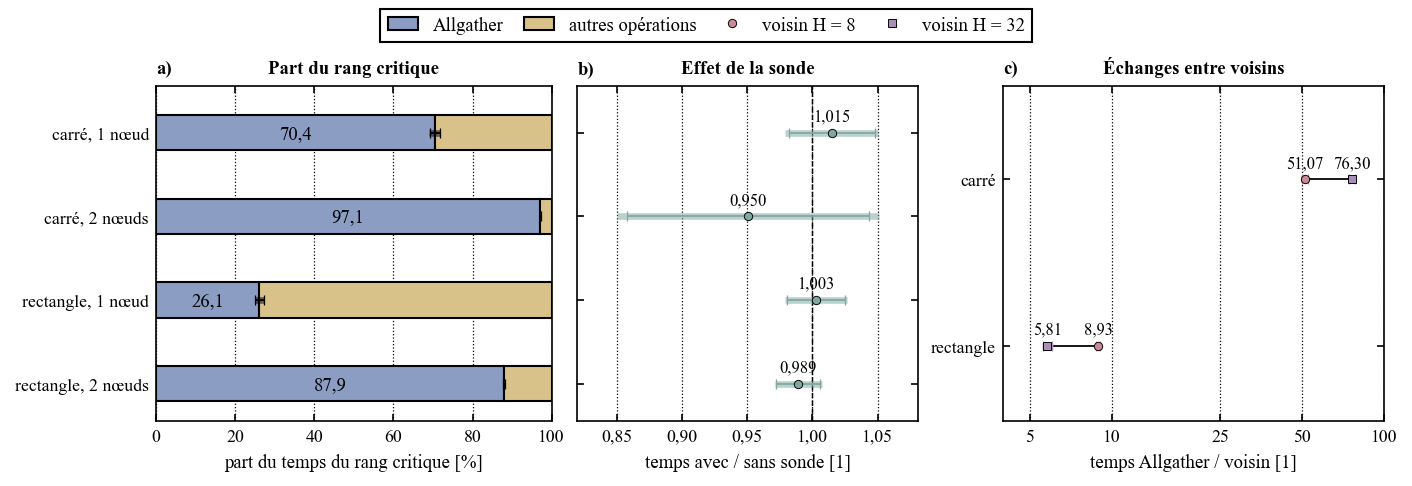

In [21]:
# Temps du rang critique, dans la même invocation instrumentée.
cm_raw = nv_csv(RES / "mpi/collectives/trials.csv")
assert cm_raw.groupby(["case", "nodes", "instrumented"]).block.nunique().eq(7).all()
assert cm_raw.physical_cores.eq(192 * cm_raw.nodes).all()
cm_active = cm_raw[cm_raw.instrumented.eq(1)].copy()
cm_active["fraction"] = 100 * pd.to_numeric(cm_active.collective_seconds) / cm_active.seconds
cm_active["remaining"] = cm_active.seconds - pd.to_numeric(cm_active.collective_seconds)
assert cm_active.fraction.between(0, 100).all()
cm_measures = cm_raw.pivot(index=["case", "nodes", "block"], columns="instrumented", values="seconds")
cm_fig, cm_ax = plt.subplots(1, 3, figsize=(9.3, 3.15), width_ratios=[1.09, 0.94, 1.05])
cm_labels = []
for cm_i, (cm_case, cm_name) in enumerate([("square", "carré"), ("wide", "rectangle")]):
    for cm_j, cm_nodes in enumerate([1, 2]):
        cm_row = 2 * cm_i + cm_j
        cm_labels.append(cm_name + ", " + str(cm_nodes) + (" nœud" if cm_nodes == 1 else " nœuds"))
        cm_select = cm_active[cm_active.case.eq(cm_case) & cm_active.nodes.eq(cm_nodes)]
        cm_frac = nv_stats.add(
            20, "collective_pct", cm_case, cm_nodes, cm_select.fraction, "independent_mpirun_block"
        )
        cm_mean = cm_frac["mean"]
        cm_ax[0].barh(cm_row, cm_mean, height=0.42, color=COLORS[0], edgecolor=INK, label="Allgather")
        cm_ax[0].barh(
            cm_row,
            100 - cm_mean,
            left=cm_mean,
            height=0.42,
            color=COLORS[3],
            edgecolor=INK,
            label="autres opérations",
        )
        estimate(cm_ax[0], cm_row, cm_frac, INK, horizontal=True, marker="|")
        cm_ax[0].text(
            cm_mean / 2, cm_row, f"{cm_mean:.1f}".replace(".", ","), ha="center", va="center", fontsize=9
        )
        cm_pair = cm_measures.xs((cm_case, cm_nodes))
        cm_eff = nv_stats.add(
            20, "probe_ratio", cm_case, cm_nodes, cm_pair[1] / cm_pair[0], "paired_mpirun_block"
        )
        estimate(cm_ax[1], cm_row, cm_eff, COLORS[2], horizontal=True)
        value_label(cm_ax[1], cm_eff["mean"], cm_row, cm_eff["mean"], 3)
category_rows(cm_ax[0], cm_labels, "part du temps du rang critique [%]")
category_rows(cm_ax[1], [""] * len(cm_labels), "temps avec / sans sonde [1]")
cm_ax[0].set_xlim(0, 100)
cm_ax[1].axvline(1, **GUIDE)
cm_pipe = nv_csv(RES / "mpi/pipeline/838796/trials.csv")
cm_counts = nv_csv(RES / "mpi/pipeline/838796/allgather.csv")
assert cm_counts.loc[cm_counts.height.gt(0), "allgathers_per_rank"].eq(0).all()
cm_pipe = cm_pipe[cm_pipe.nodes.eq(2) & cm_pipe.block.gt(0)]
assert cm_pipe.groupby(["case", "height"]).block.nunique().eq(7).all()
assert (
    cm_pipe.groupby("case").distance.nunique().eq(1).all()
    and cm_pipe.groupby("case").sha256.nunique().eq(1).all()
)
cm_ptimes = cm_pipe.pivot(index=["case", "block"], columns="height", values="seconds")
assert cm_ptimes[[0, 8, 32]].notna().all().all()
for cm_y, cm_name in enumerate(["square", "wide"]):
    cm_rows = cm_ptimes.loc[cm_name]
    cm_entries = []
    for cm_j, cm_height in enumerate([8, 32]):
        cm_speed = nv_stats.add(
            20,
            "pipeline_speedup",
            str(cm_height),
            cm_name,
            cm_rows[0] / cm_rows[cm_height],
            "paired_mpirun_block",
        )
        cm_entries.append(
            (cm_speed, [COLORS[1], COLORS[5]][cm_j], "os"[cm_j], f"voisin H = {cm_height}")
        )
    comparison(cm_ax[2], cm_y, cm_entries, annotate=False)
    for cm_entry in cm_entries:
        cm_center = cm_entry[0]["mean"]
        value_label(cm_ax[2], cm_center, cm_y, cm_center, 2)
cm_ax[2].set_xscale("log")
category_rows(cm_ax[2], ["carré", "rectangle"], "temps Allgather / voisin [1]")
cm_ax[2].set(xlim=(4, 100), xticks=[5, 10, 25, 50, 100], xticklabels=["5", "10", "25", "50", "100"])
label_panels(cm_ax)
column_titles(cm_ax, ("Part du rang critique", "Effet de la sonde", "Échanges entre voisins"))
legend_above(cm_fig, cm_ax, ncol=4)
nv_save(cm_fig, "distributed/collectives_mpi")

*Figure 20.* Sur le rang critique, la barre empilée sépare le temps dans Allgather des autres opérations (a). La sonde est comparée à son témoin dans sept blocs appariés (b). Sur deux nœuds, sept autres blocs comparent les paquets entre voisins à l’échange collectif par ligne (c).

<sub>Code : [bench/mpi/collectives/probe.c](../bench/mpi/collectives/probe.c), [bench/mpi/collectives/run.py](../bench/mpi/collectives/run.py), [results/mpi/collectives/trials.csv](../results/mpi/collectives/trials.csv), [results/mpi/pipeline/838796/trials.csv](../results/mpi/pipeline/838796/trials.csv), [bench/mpi/pipeline/measure.py](../bench/mpi/pipeline/measure.py), [results/mpi/pipeline/838796/allgather.csv](../results/mpi/pipeline/838796/allgather.csv).</sub>

Sur deux nœuds, la part moyenne de la collective atteint 97,10 (écart-type 0,10, IC 95 % de 97,00 à 97,19) % pour le carré. Le rectangle communique une fois par ligne lui aussi, sur une entrée plus courte. Le rapport de durée avec et sans instrumentation permet de situer le coût ajouté par la sonde.

Sur deux nœuds et le carré, le rapport Allgather/voisin atteint 51,07 pour H = 8 et 76,30 pour H = 32. Sur le rectangle, ces rapports valent 8,93 et 5,81. Les transferts de voisinage lèvent toutes les collectives Allgather dans la région mesurée. À H = 32, le carré reste plus rapide sur un nœud que sur deux. Le rectangle bénéficie du second nœud à H = 8, avec un gain inter-nœuds de 1,37.

La division du travail entre nœuds peut ensuite être examinée à charge constante par cœur.

<p><strong><u>Synthèse.</u></strong> Sur deux nœuds, la fraction d’Allgather vaut 87,94 % sur le rectangle.<br>La durée inclut le transfert et l’attente des rangs au sein de la collective.</p>

<a id="mpi-faible"></a>

## Passage à l’échelle faible entre nœuds

<hr>

La figure 21 suit la durée et le débit lorsque le nombre de nœuds et le travail total augmentent ensemble.

Pour $p$ nœuds et un travail $W$ par nœud, l’efficacité faible vaut $E_w(p)=T_1(W)/T_p(pW)$. Si le travail total double entre un et deux nœuds, le rapport des débits vaut $2E_w(2)$.

Les paires isolées ont 1 024 lignes et gardent 256 ou 4 096 colonnes par cœur. Le lot de 85 séquences sur un nœud produit 3 570 paires. Celui de 120 séquences en produit 7 140 sur deux nœuds. Chaque séquence synthétique du lot mesure 8 192 bases. La charge dense par cœur reste constante dans chaque cas. Le pilote vérifie les distances ou les matrices avec edlib et mesure le rang le plus lent après chauffe.

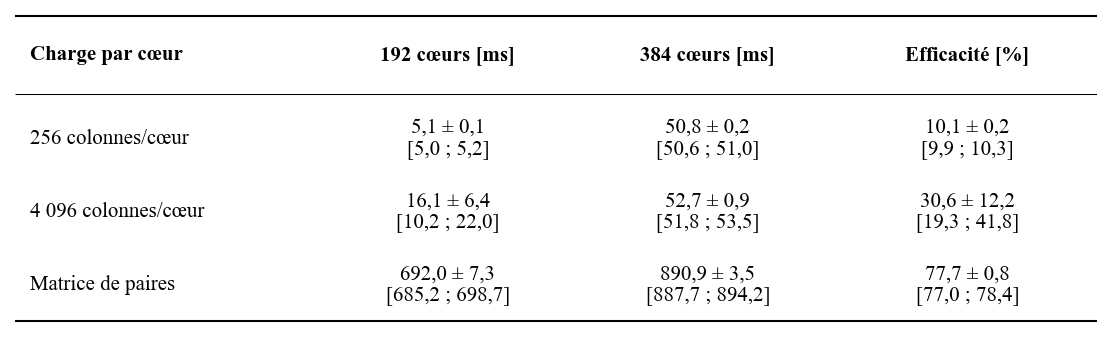

In [22]:
# Comparaison à charge constante par cœur sur un et deux nœuds.
wk_cases = ["pair_256", "pair_4096", "matrix"]
wk_repeat = nv_csv(RES / "mpi/scaling/trials.csv")
wk_repeat = wk_repeat[wk_repeat.study.eq("weak")]
assert wk_repeat.groupby(["case", "nodes"]).block.nunique().eq(7).all()
assert wk_repeat.physical_cores.eq(192 * wk_repeat.nodes).all()
wk_pair = wk_repeat.pivot(index=["case", "block"], columns="nodes", values="seconds")
wk_paired = (wk_pair[1] / wk_pair[2]).droplevel("block")
from studies.comparison_table import booktabs

wk_fig, wk_ax = plt.subplots(figsize=(7.3, 2.15))
wk_names = ["256 colonnes/cœur", "4 096 colonnes/cœur", "Matrice de paires"]
wk_rows = []
for wk_row, wk_case in enumerate(wk_cases):
    wk_records = []
    for wk_n in [1, 2]:
        wk_values = wk_repeat[wk_repeat.case.eq(wk_case) & wk_repeat.nodes.eq(wk_n)].seconds * 1000
        wk_records.append(nv_stats.add(21, "milliseconds", str(wk_n), wk_case, wk_values, "independent_mpirun"))
    wk_ratio = nv_stats.add(21, "ratio", "1/2", wk_case, wk_paired.loc[wk_case], "paired_mpirun_block")
    wk_records.append({k: 100 * wk_ratio[k] for k in ("mean", "sd", "low95", "high95")})
    wk_row_text = [wk_names[wk_row]]
    for wk_s in wk_records:
        wk_row_text.append((f"{wk_s['mean']:.1f} ± {wk_s['sd']:.1f}\n"
                            f"[{wk_s['low95']:.1f} ; {wk_s['high95']:.1f}]").replace(".", ","))
    wk_rows.append(wk_row_text)
booktabs(wk_ax, ["Charge par cœur", "192 cœurs [ms]", "384 cœurs [ms]", "Efficacité [%]"], wk_rows,
         widths=[.28, .24, .24, .24])
nv_save(wk_fig, "distributed/mpi_faible")

*Figure 21.* Le travail double entre 192 et 384 cœurs. Chaque cellule donne la moyenne des sept blocs et son écart-type, puis l’IC de Student à 95 % entre crochets. L’efficacité est la moyenne des rapports appariés.

<sub>Code : [bench/mpi/scaling.py](../bench/mpi/scaling.py), [bench/mpi/mpi_weak.py](../bench/mpi/mpi_weak.py), [results/mpi/scaling/trials.csv](../results/mpi/scaling/trials.csv).</sub>

La charge par cœur reste constante lorsque le second nœud s’ajoute au premier. L’efficacité moyenne de la matrice vaut 0,777 (écart-type 0,008, IC 95 % de 0,770 à 0,784). La matrice multiplie le nombre de paires entières distribuées. Pour une paire isolée, chaque rang communique à chaque ligne, même dans le cas des 256 colonnes par cœur.

Les mêmes régimes sont ensuite mesurés sur des fenêtres homologues d’un chromosome humain.

<p><strong><u>Synthèse.</u></strong> Le passage de 192 à 384 cœurs favorise davantage la matrice que chacune des paires isolées.<br>Cette comparaison dépend de la géométrie et de l’interconnexion des nœuds alloués.</p>

<a id="distribution-fenetres-humaines"></a>

## Distribution de fenêtres chromosomiques

<hr>

La figure 22 compare la distribution d’une paire longue entre les rangs et la distribution de fenêtres entières entre les travailleurs.

Chaque comparaison porte sur deux intervalles homologues du chromosome 21 de GRCh38 et de CHM13. Les 768 fenêtres disjointes mesurent chacune 16 384 bases sur GRCh38. Le sous-ensemble de 384 prend une fenêtre sur deux le long du chromosome. Les longueurs homologues de CHM13 varient légèrement. Le travail dense du lot est $W=\sum_i m_i n_i$. Avec deux fois plus de cœurs, l’efficacité de débit vaut $E=(W_2/W_1)(T_1/T_2)/2$. En scaling fort, $W_2=W_1$. En scaling faible, le rapport observé est 1,99820.

Sur une paire, tous les rangs contribuent aux mêmes lignes. Le témoin échange ses données par Allgather à chaque ligne. Les autres variantes envoient au voisin un bord tous les 32 ou 128 lignes de la matrice. Sur les lots, chaque travailleur traite une paire de fenêtres à la fois. Une allocation réunit un ou deux nœuds de 192 cœurs. Chaque lancement fait une chauffe puis une mesure sur chaque rang. Le maximum des temps des rangs détermine la durée.

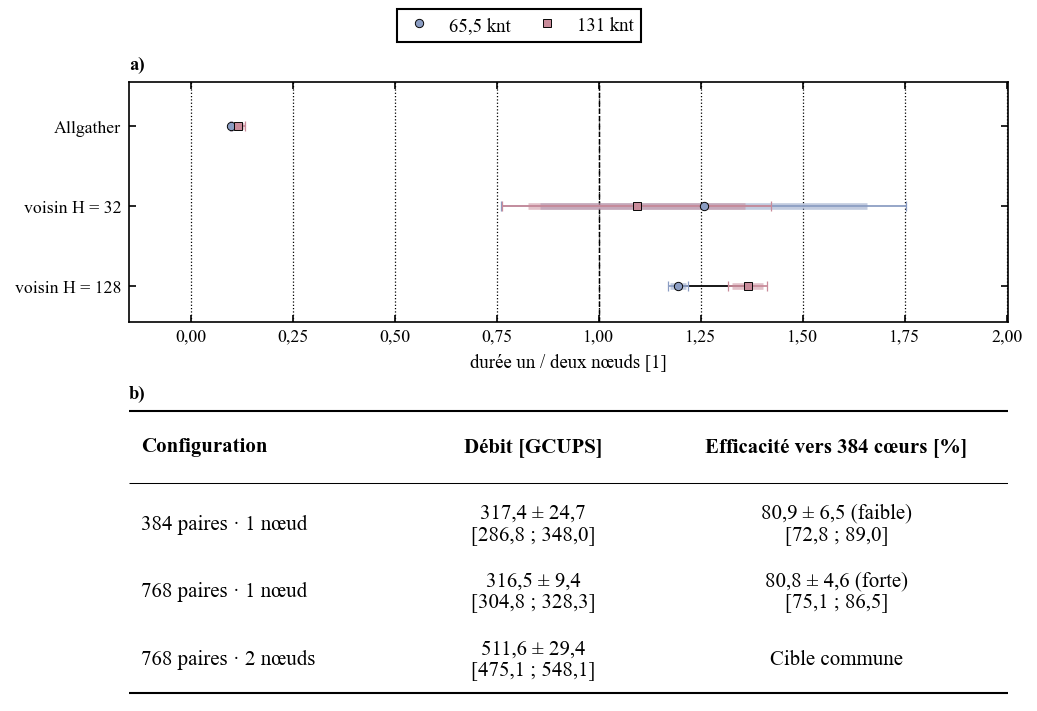

In [23]:
# Les 768 lignes du lot désignent des comparaisons entre intervalles homologues.
mh_windows = pd.read_csv(RES / "mpi/human/windows.tsv", sep="\t")
mh_raw = nv_csv(RES / "mpi/human/trials.csv")
assert mh_windows.id.is_unique and len(mh_windows) == 770
mh_scores = pd.read_csv(RES / "mpi/human/scores.tsv", sep="\t")
assert len(mh_scores) == 770 and mh_scores.edlib.ge(0).all()
assert (mh_windows.m * mh_windows.n).eq(mh_windows.cells).all()
assert mh_raw.groupby(["case", "height", "nodes"]).block.nunique().eq(5).all()
assert mh_raw.physical_cores.eq(192 * mh_raw.nodes).all()
assert mh_raw.groupby("case").scores_sha256.nunique().eq(1).all()
assert mh_raw.groupby("case").input_sha256.nunique().eq(1).all()
mh_strong = mh_raw[mh_raw["case"].str.startswith("pair-")]
from studies.comparison_table import booktabs

mh_fig, mh_axes = plt.subplots(2, 1, figsize=(6.8, 4.65), height_ratios=[1.02, 1.22])
mh_programs = [(0, "Allgather"), (32, "voisin H = 32"), (128, "voisin H = 128")]
mh_labels = []
for mh_id, (mh_alg, mh_label) in enumerate(mh_programs):
    mh_labels.append(mh_label)
    mh_entries = []
    for mh_pos, mh_case in enumerate(["pair-64k", "pair-128k"]):
        mh_rows = mh_strong[mh_strong["case"].eq(mh_case) & mh_strong.height.eq(mh_alg)]
        mh_nodes = mh_rows.pivot(index="block", columns="nodes", values="seconds")
        assert mh_nodes[[1, 2]].notna().all().all()
        mh_observed = nv_stats.add(
            22, "pair_speedup", mh_alg, mh_case, mh_nodes[1] / mh_nodes[2], "paired_mpirun_block"
        )
        mh_entries.append((mh_observed, COLORS[mh_pos], "os"[mh_pos], ["65,5 knt", "131 knt"][mh_pos]))
    comparison(mh_axes[0], mh_id, mh_entries, annotate=False)
category_rows(mh_axes[0], mh_labels, "durée un / deux nœuds [1]")
mh_axes[0].axvline(1, **GUIDE)
mh_lots = mh_raw[mh_raw["case"].str.startswith("matched-")]
mh_work = {}
mh_times = {}
mh_rates = {}
for mh_idx, (mh_count, mh_node) in enumerate([(384, 1), (768, 1), (768, 2)]):
    mh_part = mh_lots[mh_lots.pairs.eq(mh_count) & mh_lots.nodes.eq(mh_node)].set_index("block")
    mh_work[mh_count] = int(mh_part.cells.unique().item())
    assert (
        mh_work[mh_count] == mh_windows[mh_windows.id.str.startswith("locus")].head(mh_count).cells.sum()
    )
    mh_times[(mh_count, mh_node)] = mh_part.seconds
    mh_rate = nv_stats.add(
        22, "gcups", str(mh_count), mh_node, mh_part.cells / (1e9 * mh_part.seconds), "independent_mpirun"
    )
    mh_rates[mh_count, mh_node] = mh_rate
mh_efficiencies = {}
for mh_j, (mh_regime, mh_n1) in enumerate([("fort", 768), ("faible", 384)]):
    mh_efficiency = mh_times[(mh_n1, 1)] / mh_times[(768, 2)] * mh_work[768] / (2 * mh_work[mh_n1])
    mh_eff = nv_stats.add(
        22, "batch_efficiency", mh_regime, "384_cores", 100 * mh_efficiency, "paired_mpirun_block"
    )
    mh_efficiencies[mh_n1] = mh_eff
mh_table = []
for mh_count, mh_nodes in [(384, 1), (768, 1), (768, 2)]:
    mh_rate = mh_rates[mh_count, mh_nodes]
    mh_label = f"{mh_count} paires · {mh_nodes} " + ("nœud" if mh_nodes == 1 else "nœuds")
    mh_line = [mh_label, f"{mh_rate['mean']:.1f} ± {mh_rate['sd']:.1f}\n[{mh_rate['low95']:.1f} ; {mh_rate['high95']:.1f}]"]
    if mh_nodes == 1:
        mh_e = mh_efficiencies[mh_count]
        mh_type = "faible" if mh_count == 384 else "forte"
        mh_line.append(f"{mh_e['mean']:.1f} ± {mh_e['sd']:.1f} ({mh_type})\n[{mh_e['low95']:.1f} ; {mh_e['high95']:.1f}]")
    else:
        mh_line.append("Cible commune")
    mh_table.append([v.replace(".", ",") for v in mh_line])
booktabs(mh_axes[1], ["Configuration", "Débit [GCUPS]", "Efficacité vers 384 cœurs [%]"], mh_table,
         widths=[.31, .30, .39])
label_panels(mh_axes)
legend_above(mh_fig, [mh_axes[0]], ncol=2)
nv_save(mh_fig, "distributed/echelle_mpi_humain")

*Figure 22.* Pour une paire, le gain sur deux nœuds dépend du mode d’échange (a). Pour les lots, le débit est rapporté au travail en cellules (b). Les deux efficacités prennent pour cible les 768 paires sur deux nœuds. Les cinq blocs donnent la moyenne, l’écart-type et l’IC à 95 % entre crochets.

<sub>Code : [bench/mpi/human/windows.py](../bench/mpi/human/windows.py), [bench/mpi/human/measure.py](../bench/mpi/human/measure.py), [results/mpi/human/windows.tsv](../results/mpi/human/windows.tsv), [results/mpi/human/trials.csv](../results/mpi/human/trials.csv), [results/mpi/human/scaling.csv](../results/mpi/human/scaling.csv), [results/mpi/human/scores.tsv](../results/mpi/human/scores.tsv).</sub>

À lot fixe, le rapport moyen des temps sur un et deux nœuds vaut 1,617 (IC à 95 % de 1,503 à 1,731). Au passage de 384 à 768 fenêtres, l’efficacité de débit atteint 80,9 % (écart-type 6,5 points, IC à 95 % de 72,8 à 89,0 %).

Un lot hétérogène permet de séparer l’effet de la répartition des paires de celui de leur ordre dans le FASTA.

<p><strong><u>Synthèse.</u></strong> Sur la paire de 131 knt, le rapport des temps sur un et deux nœuds vaut 0,12 avec Allgather et 1,36 par transferts de 128 lignes.<br>Le lot de fenêtres utilise les rangs pour des calculs indépendants.</p>

<a id="ordonnancement"></a>

## Ordonnancement de paires de longueurs hétérogènes

<hr>

La figure 23 examine la répartition du travail lorsque les paires de fenêtres humaines ont des tailles différentes. Deux classements du même FASTA, par locus et par longueur, conservent toutes les distances à calculer.

Chaque case du triangle supérieur représente une paire. Les politiques répartissent ces cases par blocs contigus, par alternance cyclique ou dans l’ordre d’une courbe de Hilbert. Une variante pondérée divise la courbe de Hilbert selon le cumul des produits de longueurs. Le vol de tâches redistribue le travail restant entre rangs, par paquets dont les fils locaux traitent quatre paires à la fois. Un nœud porte 24 rangs de huit fils. Chaque lancement chauffe sur le lot avant le passage mesuré.

Pour $p$ rangs et des charges $W_r$ en cellules, le déséquilibre vaut $\max(W_r)/(\sum_r W_r/p)$. La fraction d’occupation divise la somme des temps de calcul des fils par le produit du nombre de cœurs et de la durée du lot. Les deux nœuds traitent le même travail que le premier, ce qui donne $E=T_1/(2T_2)$ à bloc fixé.

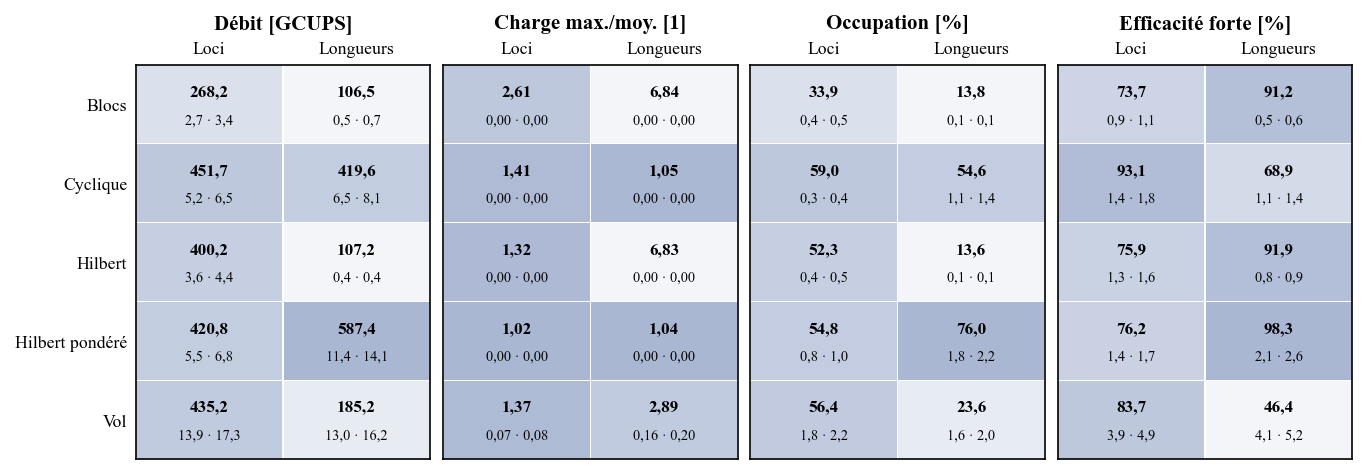

In [24]:
from studies.schedules import make_figure as ms_make_figure

ms_path = RES / "mpi/schedules/839194"
ms_t = nv_csv(ms_path / "trials.csv")
assert ms_t.groupby(["layout", "schedule", "nodes"]).block.nunique().eq(5).all()
assert ms_t.canonical_scores_sha256.nunique() == ms_t.cells.nunique() == 1
for (ms_layout, ms_policy), ms_rows in ms_t.groupby(["layout", "schedule"]):
    ms_2 = ms_rows[ms_rows.nodes.eq(2)]
    for ms_col, ms_scale in [("gcups", 1), ("max_mean_rank_cells", 1), ("busy_fraction", 100)]:
        nv_stats.add(23, ms_col, ms_layout, ms_policy, ms_2[ms_col] * ms_scale, "fresh_mpi_launch")
    ms_grid = ms_rows.pivot(index="block", columns="nodes", values="seconds")
    nv_stats.add(
        23,
        "strong_efficiency_percent",
        ms_layout,
        ms_policy,
        50 * ms_grid[1] / ms_grid[2],
        "paired_mpi_launches",
    )
ms_fig = ms_make_figure(ROOT)
nv_save(ms_fig, "distributed/ordonnancement")

*Figure 23.* Chaque colonne compare les deux ordres du FASTA sur cinq blocs. Dans chaque cellule figurent la moyenne, puis l’écart-type et la demi-largeur de l’IC à 95 %, dans l’unité de la colonne. La teinte fonce vers le débit, l’occupation et l’efficacité les plus élevés, ou vers la charge maximale relative la plus faible. L’efficacité forte compare un et deux nœuds. Les trois autres indicateurs portent sur deux nœuds.

<sub>Code : [src/mpi/scheduled_matrix.hpp](../src/mpi/scheduled_matrix.hpp), [bench/mpi/schedules/measure.py](../bench/mpi/schedules/measure.py), [python/studies/schedules.py](../python/studies/schedules.py), [results/mpi/schedules/839194/trials.csv](../results/mpi/schedules/839194/trials.csv), [results/mpi/schedules/839194/scaling.csv](../results/mpi/schedules/839194/scaling.csv).</sub>

Les 128 fenêtres donnent 8 128 paires et 181 418 301 166 cellules dans chacun des deux ordres. Après classement par longueur, le rapport entre charge maximale et charge moyenne passe de 6,83 avec Hilbert à 1,04 après pondération. La part du temps des cœurs consacrée au calcul passe de 13,6 à 76,0 %. Le gain de temps apparié correspondant vaut 5,48 (écart-type 0,12, IC à 95 % de 5,33 à 5,63). En ordre par locus, le parcours cyclique atteint 451,7 GCUPS, devant la courbe pondérée à 420,8 GCUPS.

La carte des paires situe les blocs qui concentrent le travail sur quelques rangs.

<p><strong><u>Synthèse.</u></strong> Les cinq politiques produisent la même matrice sur les 8 128 paires.<br>Le classement du FASTA change la répartition des cellules entre les rangs.</p>

<a id="carte-paires"></a>

## Géométrie des partitions de Hilbert

<hr>

La figure 24 situe les paires coûteuses dans le parcours. Sur les 128 fragments du chromosome 21 triés par longueur, la paire $(i,j)$ demande $w_{ij}=m_i m_j$ cellules. Chaque paire $i<j$ est calculée une fois. La carte la représente de chaque côté de la diagonale pour comparer les deux répartitions.

Si $h_t$ est la $t$-ième paire dans l’ordre de Hilbert, le préfixe $P(k)=\sum_{t=1}^{k}w_{h_t}$ donne la charge des $k$ premières paires. Le découpage par effectif donne 169 ou 170 paires à chacun des 48 rangs. La pondération place la coupe du rang $r$ au préfixe le plus proche de la cible entière $\lfloor rP(8\,128)/48\rfloor$.

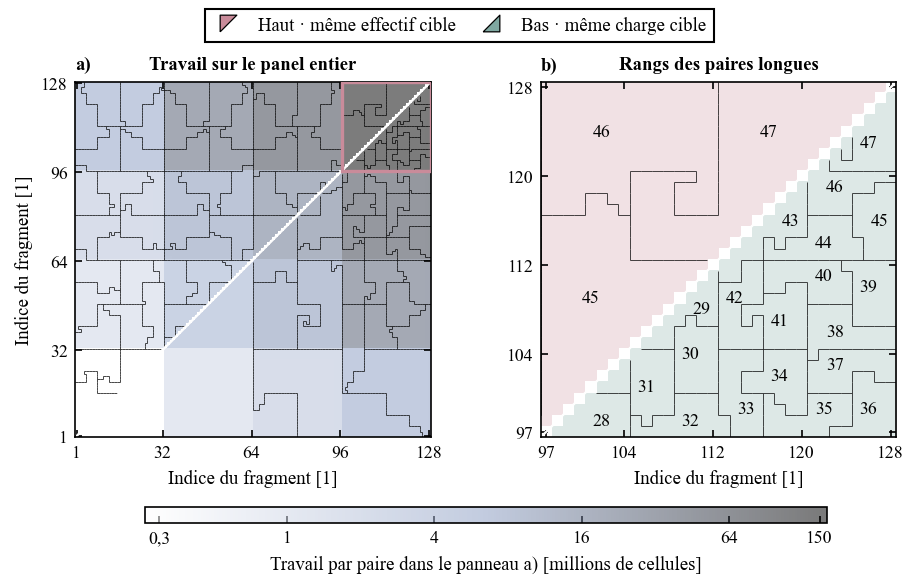

In [25]:
from studies.pair_work_map import make_figure as pm_make_figure, work_map as pm_work_map

pm_costs, pm_owners, pm_summary = pm_work_map(ROOT)
for pm_metric in ("pairs", "pairs_total", "cells", "cells_total", "min_length", "max_length"):
    nv_stats.add(24, pm_metric, "sorted_chr21_windows", "longest_quartile",
                 [pm_summary[pm_metric]], "complete_pair_matrix", independent=False)
for pm_policy in ("hilbert", "hilbert-weighted"):
    nv_stats.add(24, "ranks_with_mutual_pairs", pm_policy, "longest_quartile",
                 [pm_summary[pm_policy]], "fixed_assignment", independent=False)
nv_save(pm_make_figure(pm_costs, pm_owners), "distributed/carte_paires", vector=True, alt='Travail par paire de fenêtres du chromosome 21 et attribution aux rangs MPI sur le parcours de Hilbert.')

*Figure 24.* La teinte du panneau a) donne le travail par paire. Les contours séparent les rangs MPI sur deux nœuds. Le triangle supérieur suit le découpage par effectif et le triangle inférieur la pondération par cellules. Le panneau b) agrandit le carré encadré et indique les numéros de rang, de 0 à 47.

<sub>Code : [python/studies/pair_work_map.py](../python/studies/pair_work_map.py), [src/mpi/scheduled_matrix.hpp](../src/mpi/scheduled_matrix.hpp), [longueurs des fragments](../results/mpi/schedules/windows.tsv), [travail par rang](../results/mpi/schedules/839194/rank_work.csv).</sub>

Les 32 fragments les plus longs mesurent de 12 272 à 12 746 bases. Leurs comparaisons mutuelles se concentrent dans un coin du triangle. Hilbert les attribue aux rangs 45 à 47. En pondérant les coupes, les mêmes paires occupent les rangs 28 à 47. La distribution cumulée relie ensuite ces coupes à la charge totale de chaque rang.

<p><strong><u>Synthèse.</u></strong> Les 496 paires du quart le plus long représentent 6,10 % des 8 128 comparaisons.<br>Elles demandent 75,18 milliards de cellules, soit 41,44 % du travail dense.</p>

<a id="concentration-rangs"></a>

## Concentration du travail entre rangs

<hr>

La figure 25 mesure la fraction du travail portée par les rangs les plus chargés. Dans chaque lancement à deux nœuds, les 48 rangs sont classés par nombre décroissant de cellules $W_{(r)}$. Les fenêtres du chromosome 21 sont triées par longueur avant de former les 8 128 paires. Leur travail total est $W=\sum_{i<j}m_i m_j$.

La courbe représente $C(k)=\sum_{r=1}^k W_{(r)}/W$. Un partage égal suit $C(k)=k/48$. Le classement est recalculé dans chacun des cinq lancements avec vol de travail.

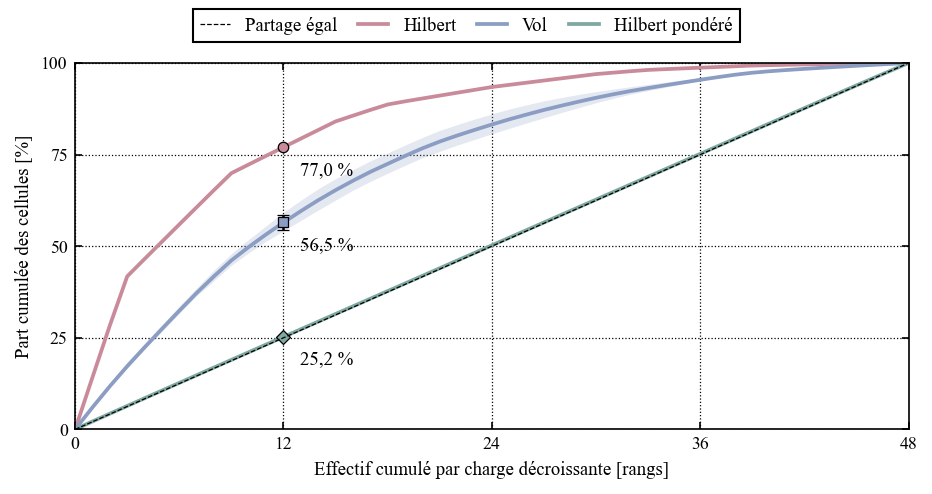

In [26]:
from studies.rank_concentration import concentration as rc_concentration, make_figure as rc_make_figure

rc_curves = rc_concentration(nv_csv(RES / "mpi/schedules/839194/rank_work.csv"))
for rc_policy in ["hilbert", "steal", "hilbert-weighted"]:
    rc_selection = rc_curves[rc_curves.policy.eq(rc_policy)]
    for rc_rank, rc_group in rc_selection.groupby("ranks"):
        rc_values = rc_group.share.to_numpy() * 100
        if rc_policy != "steal":
            rc_values = np.unique(rc_values)
            assert len(rc_values) == 1
        nv_stats.add(25, "cumulative_cell_percent", rc_policy, rc_rank, rc_values,
                     "independent_mpi_launch" if rc_policy == "steal" else "fixed_assignment")
nv_save(rc_make_figure(rc_curves), "distributed/concentration_rangs")

*Figure 25.* Les courbes cumulent les cellules des rangs classés par charge décroissante. Le ruban donne l’IC ponctuel à 95 % des cinq lancements avec vol. La barre à douze rangs représente un écart-type de part et d’autre de la moyenne. Les deux répartitions de Hilbert sont déterminées par les longueurs et les frontières de blocs.

<sub>Code : [python/studies/rank_concentration.py](../python/studies/rank_concentration.py), [results/mpi/schedules/839194/rank_work.csv](../results/mpi/schedules/839194/rank_work.csv).</sub>

Avec le vol, les douze rangs les plus chargés traitent 56,5 % des cellules (écart-type 2,0 points, IC à 95 % de 54,0 à 59,0 %). Les transferts réduisent la concentration de la charge sur ces rangs. La comparaison suivante change le moteur de calcul à politique de répartition fixée.

<p><strong><u>Synthèse.</u></strong> Pour un quart des rangs, la part des cellules passe de 77,0 % avec Hilbert à 25,2 % lorsque les blocs sont pondérés par le produit des longueurs.<br>Le nombre de paires seul sous-estime donc la charge des rangs qui alignent les plus longues fenêtres.</p>

<a id="travailleurs-mpi"></a>

## Exécution des paires avec Kokkos

<hr>

La figure 26 compare deux manières d’exécuter les paires affectées à un rang MPI. Le lot contient les mêmes 128 fenêtres humaines, triées par longueur. Chaque politique répartit les 8 128 paires entre les rangs avant leur calcul par huit travailleurs locaux.

Le premier mode utilise une équipe OpenMP directe. Le deuxième soumet les tâches à l’espace d’exécution Kokkos::OpenMP. Les deux exécutent le même noyau NvPD pour chaque paire. Le rapport $R=T_{\mathrm{OpenMP}}/T_{\mathrm{Kokkos}}$ compare les durées dans chaque bloc, à nombre de nœuds et à ordonnancement fixés. Un rapport supérieur à un indique un temps plus court avec Kokkos. L’efficacité forte $E=T_1/(2T_2)$ rapporte le gain à la multiplication par deux du nombre de cœurs.

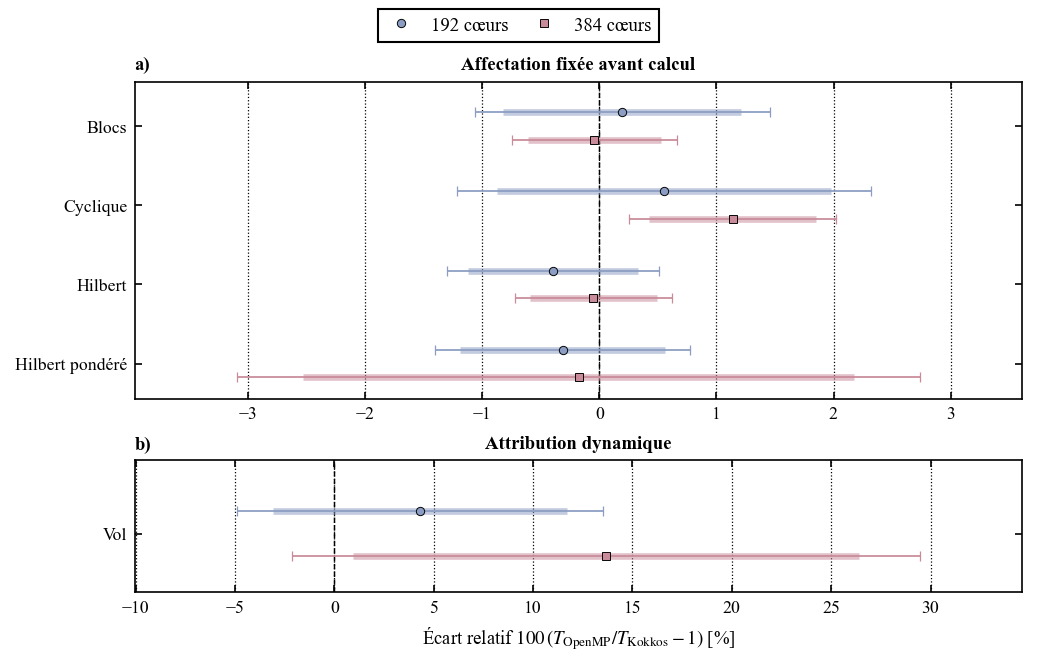

In [27]:
from studies.mpi_workers import make_figure as mw_make_figure

mw_path = RES / "mpi/workers/839197"
mw_t = nv_csv(mw_path / "trials.csv")
assert len(mw_t) == 100 and mw_t.pairs.eq(8128).all()
assert mw_t.groupby(["schedule", "nodes", "backend"]).block.nunique().eq(5).all()
assert mw_t.physical_cores.eq(192 * mw_t.nodes).all() and mw_t.cells.nunique() == 1
for (mw_policy, mw_nodes), mw_g in mw_t.groupby(["schedule", "nodes"]):
    mw_q = mw_g.pivot(index="block", columns="backend", values="seconds")
    nv_stats.add(
        26, "openmp_over_kokkos", mw_policy, mw_nodes, mw_q.openmp / mw_q.kokkos, "paired_mpi_launches"
    )
    for mw_backend, mw_b in mw_g.groupby("backend"):
        mw_key = f"{mw_policy}/{mw_backend}"
        nv_stats.add(26, "seconds", mw_key, mw_nodes, mw_b.seconds, "fresh_mpi_launch")
        nv_stats.add(26, "gcups", mw_key, mw_nodes, mw_b.cells / mw_b.seconds / 1e9, "fresh_mpi_launch")
        nv_stats.add(
            26, "max_rank_rss_mib", mw_key, mw_nodes, mw_b.peak_rank_rss_kib / 1024, "fresh_mpi_launch"
        )
for (mw_policy, mw_backend), mw_g in mw_t.groupby(["schedule", "backend"]):
    mw_grid = mw_g.pivot(index="block", columns="nodes", values="seconds")
    nv_stats.add(
        26,
        "strong_efficiency_percent",
        mw_policy,
        mw_backend,
        50 * mw_grid[1] / mw_grid[2],
        "paired_mpi_launches",
    )
mw_fig = mw_make_figure(ROOT)
nv_save(mw_fig, "distributed/travailleurs_kokkos")

*Figure 26.* L’écart relatif des temps est mesuré sur cinq blocs appariés pour les affectations fixes (a) et le vol de travail (b). Les deux échelles rendent visibles les différences de dispersion. Une valeur positive indique un temps plus court avec Kokkos. Les traits épais et fins représentent respectivement l’écart-type et l’IC à 95 %.

<sub>Code : [src/mpi/scheduled_matrix.hpp](../src/mpi/scheduled_matrix.hpp), [bench/mpi/workers/compare.py](../bench/mpi/workers/compare.py), [python/studies/mpi_workers.py](../python/studies/mpi_workers.py), [results/mpi/workers/839197/trials.csv](../results/mpi/workers/839197/trials.csv).</sub>

À deux nœuds, la matrice en ordre de Hilbert pondéré prend 0,3960 s avec OpenMP et 0,3968 s avec Kokkos. Le rapport apparié vaut 0,998 (écart-type 0,024, IC à 95 % de 0,969 à 1,027). Avec le vol de tâches, le rapport vaut 1,137 (écart-type 0,127, IC à 95 % de 0,979 à 1,295). Pour ces deux politiques, l’IC du rapport contient la valeur 1. Le chronomètre couvre la distribution du travail, le calcul des distances et la réduction finale. Cette expérience porte sur une paire de nœuds distincte de celle de l’essai d’ordonnancement précédent.

Pour les chromosomes complets étudiés ensuite, le coût de chaque paire dépend de la structure des différences entre assemblages.

<p><strong><u>Synthèse.</u></strong> Les deux modes ont été vérifiés sur les 8 128 distances avec 192 puis 384 cœurs physiques.<br>Sur les nœuds de cette campagne, l’efficacité forte de Kokkos atteint 75,6 % pour Hilbert pondéré.</p>

<a id="chromosome"></a>

## Distances entre assemblages d’un chromosome humain

<hr>

La figure 27 compare le temps et la mémoire nécessaires à l’alignement de deux assemblages du chromosome humain.

Le contrôle par insertions donne $d\geq |n-m|=64$. La liste des 64 insertions fournit la borne opposée. Les fenêtres naturelles utilisent des paires d’intervalles orientés dans le même sens et désignés par les coordonnées du manifeste. [Nurk et coll., 2022](https://doi.org/10.1126/science.abj6987)

La chaîne de correspondance de hg38 vers hs1 permet de retrouver dans l’assemblage T2T-CHM13 les bornes de deux intervalles du chromosome 21 de GRCh38. Les positions sont indexées depuis zéro et la borne de fin est exclue. Les fenêtres GRCh38 commencent toutes les deux à 34 000 000 et se terminent à 36 000 000 et 38 000 000. La première est donc incluse dans la seconde. La chaîne sert à choisir les intervalles, puis chaque algorithme calcule une distance globale sur les chaînes FASTA complètes de la paire. [Manifeste et coordonnées](../results/human/manifest.tsv) · [Chaîne de correspondance UCSC](https://hgdownload.soe.ucsc.edu/goldenPath/hg38/liftOver/hg38ToHs1.over.chain.gz)

Le contrôle utilise le chromosome 21 entier de T2T-CHM13, long de 45 090 682 bases, face à une copie où le générateur insère 64 lettres.

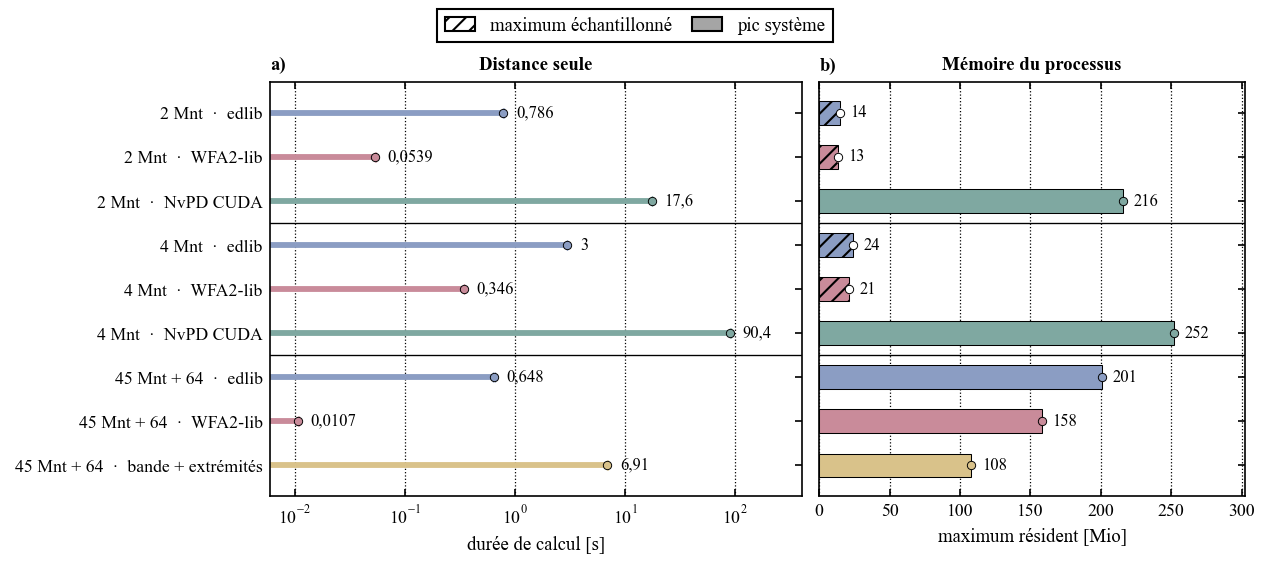

In [28]:
# Intervalles homologues et contrôle synthétique sur fond de chromosome réel.
hu_manifest = pd.read_csv(RES / "human/manifest.tsv", sep="\t").set_index("case")
hu_rep = nv_csv(RES / "repeated/gh200/trials.csv")
hu_ok = hu_rep[hu_rep.warmup.eq(0) & hu_rep.case.isin(hu_manifest.index)].copy()
hu_ok = hu_ok.rename(columns={"process_peak_rss_kib": "peak_rss_kib"})
assert hu_ok.groupby(["case", "algorithm"]).block.nunique().ge(5).all()
assert hu_ok.groupby("case").distance.nunique().eq(1).all()
assert hu_ok.input_sha256.eq(hu_ok.case.map(hu_manifest.sha256)).all()
assert (hu_ok.m == hu_ok.case.map(hu_manifest.m)).all() and (
    hu_ok.n == hu_ok.case.map(hu_manifest.n)
).all()
assert hu_ok.loc[hu_ok.case.eq("chr21-full-insert64"), "distance"].eq(64).all()
hu_spot = pd.read_json(RES / "kokkos/human.json", typ="series")
assert (
    hu_spot.distance
    == hu_spot.reference_distance
    == hu_ok.loc[hu_ok.case.eq("chr21-2m"), "distance"].iloc[0]
)
assert hu_spot.input_sha256 == hu_manifest.loc["chr21-2m", "sha256"]
hu_order = ["chr21-2m", "chr21-4m", "chr21-full-insert64"]
hu_memory = nv_csv(RES / "repeated/gh200/memory_trials.csv")
hu_memory = hu_memory[hu_memory.case.isin(hu_order)]
assert hu_memory.input_sha256.eq(hu_memory.case.map(hu_manifest.sha256)).all()
assert not hu_memory.duplicated(["case", "algorithm", "block"]).any()
hu_fig, hu_ax = plt.subplots(1, 2, figsize=(8.35, 3.7), sharey=True, width_ratios=(1.25, 1))
hu_methods = [
    ("edlib", "edlib"),
    ("wfa2", "WFA2-lib"),
    ("nvpd-cuda", "NvPD CUDA"),
    ("banded-trim", "bande + extrémités"),
]
hu_labels = ["2 Mnt", "4 Mnt", "45 Mnt + 64"]
hu_ticks = []
hu_rows = []
for hu_k, hu_case in enumerate(hu_order):
    for hu_i, (hu_alg, hu_name) in enumerate(hu_methods):
        hu_obs = hu_ok[hu_ok.algorithm.eq(hu_alg) & hu_ok.case.eq(hu_case)]
        if hu_obs.empty:
            continue
        hu_mem = hu_memory[hu_memory.case.eq(hu_case) & hu_memory.algorithm.eq(hu_alg)]
        assert len(hu_mem) == len(hu_obs) and hu_mem.rss_kib.gt(0).all() and hu_mem.rss_metric.nunique() == 1
        hu_unit = hu_mem.rss_metric.iloc[0]
        hu_t = nv_stats.add(27, "seconds", hu_alg, hu_case, hu_obs.seconds, "fresh_process")
        hu_r = nv_stats.add(27, "rss_mib", hu_alg, hu_case, hu_mem.rss_kib / 1024, hu_unit)
        hu_pos = len(hu_ticks)
        hu_ticks.append(f"{hu_labels[hu_k]}  ·  {hu_name}")
        hu_rows.append((hu_pos, hu_t, hu_r, hu_i, "smaps" in hu_unit))
    if hu_k < len(hu_order) - 1:
        for hu_axis in hu_ax:
            hu_axis.axhline(len(hu_ticks) - 0.5, color=INK, linewidth=0.65)

hu_left = min(row[1]["mean"] for row in hu_rows) / 1.8
for hu_pos, hu_t, hu_r, hu_i, hu_sampled in hu_rows:
    hu_ax[0].hlines(hu_pos, hu_left, hu_t["mean"], color=COLORS[hu_i], linewidth=2.8)
    estimate(hu_ax[0], hu_pos, hu_t, COLORS[hu_i], horizontal=True)
    hu_ax[0].annotate(f"{hu_t['mean']:.3g}".replace(".", ","), (hu_t["mean"], hu_pos),
                      xytext=(6, 0), textcoords="offset points", va="center", fontsize=8)
    hu_ax[1].barh(hu_pos, hu_r["mean"], height=0.54, color=COLORS[hu_i],
                  hatch="///" if hu_sampled else None, edgecolor=INK, linewidth=0.5)
    estimate(hu_ax[1], hu_pos, hu_r, COLORS[hu_i], horizontal=True, hollow=hu_sampled)
    hu_ax[1].annotate(f"{hu_r['mean']:.0f}", (hu_r["mean"], hu_pos),
                      xytext=(5, 0), textcoords="offset points", va="center", fontsize=8)
hu_ax[0].set(xscale="log", xlim=(hu_left, max(row[1]["mean"] for row in hu_rows) * 4.5),
             yticks=range(len(hu_ticks)), yticklabels=hu_ticks, xlabel="durée de calcul [s]")
hu_ax[0].invert_yaxis()
for hu_axis in hu_ax:
    hu_axis.grid(False, axis="y")
hu_ax[1].set(xlim=(0, max(row[2]["mean"] for row in hu_rows) * 1.2), xlabel="maximum résident [Mio]")
hu_ax[1].barh([np.nan], [0], color=PAPER, edgecolor=INK, hatch="///", label="maximum échantillonné")
hu_ax[1].barh([np.nan], [0], color=COLORS[4], edgecolor=INK, label="pic système")
label_panels(hu_ax)
column_titles(hu_ax, ("Distance seule", "Mémoire du processus"))
legend_above(hu_fig, hu_ax, ncol=2)
nv_save(hu_fig, "biology/chromosome21")

*Figure 27.* Le temps et la mémoire des mêmes configurations occupent la même ligne. Les barres pleines indiquent le pic système et les hachures le maximum échantillonné par `smaps_rollup` à une période cible de 1 ms. Chaque estimation porte sur cinq processus après chauffe. Une allocation brève peut échapper à l’échantillonnage.

<sub>Code : [bench/repeated/kernel.cpp](../bench/repeated/kernel.cpp), [results/human/manifest.tsv](../results/human/manifest.tsv), [results/repeated/gh200/trials.csv](../results/repeated/gh200/trials.csv), [results/kokkos/human.json](../results/kokkos/human.json), [results/repeated/gh200/memory_trials.csv](../results/repeated/gh200/memory_trials.csv), [bench/repeated/memory/grace_memory.py](../bench/repeated/memory/grace_memory.py).</sub>

Les fenêtres de deux et quatre millions de bases ont des distances respectives de 5 599 et 12 482. Leurs portées maximales de 290 et 622 colonnes imposent le noyau NvPD par ligne. Sur la fenêtre de 4 Mnt, NvPD CUDA prend 90,42 (écart-type 0,28, IC 95 % de 90,08 à 90,76) s et WFA2-lib 0,346 s. Kokkos CUDA atteint le même score de 5 599 dans son contrôle séparé à 24,20 s. Cette observation unique porte sur une autre allocation et un autre environnement de compilation.

Lorsque les deux séquences diffèrent peu, restreindre les états explorés peut réduire le travail.

<p><strong><u>Synthèse.</u></strong> Le témoin sur chromosome entier comporte exactement 64 insertions contrôlées.<br>Sa faible distance et sa longueur distinguent le coût lié aux différences du coût lié à la taille.</p>

<a id="assemblages-entiers"></a>

## Comparaison de chromosomes humains entiers

<hr>

La figure 28 compare les temps de calcul du chromosome 20 et les bornes disponibles pour la distance entre les deux références du chromosome 21.

Pour la lettre $c$, $s_a=\sum_c\max(h_a(c)-h_b(c),0)$ compte les excédents de $a$, et $s_b$ ceux de $b$. Chaque édition résout au plus un excédent de chaque côté. Ainsi $\max(s_a,s_b)\leq d(a,b)$. Une chaîne de correspondance monotone entre les assemblages fournit un alignement explicite de coût $U$, donc $d(a,b)\leq U$.

Les séquences CP068258.1 et CP068258.2 représentent les versions 1.0 et 2.0 du chromosome 20 de T2T-CHM13. Les longueurs valent 66 210 247 et 66 210 255 bases. Sur le chromosome 21, GRCh38 et CHM13 mesurent respectivement 46 709 983 et 45 090 682 bases. Le programme aligne les chaînes déposées, avec un coût unitaire et une comparaison littérale des symboles ambigus. Le chromosome 20 est chronométré sur le processeur Grace, à raison de cinq processus indépendants par bibliothèque et d’une chauffe par processus. Pour le chromosome 21, une tentative par méthode sur un cœur EPYC dispose de 120 s et de 4 Gio d’espace d’adressage.

Le consortium T2T décrit la validation et le polissage des assemblages CHM13. La comparaison entre versions porte ainsi sur deux représentations du même échantillon. [Mc Cartney et coll., 2022](https://doi.org/10.1038/s41592-022-01440-3)

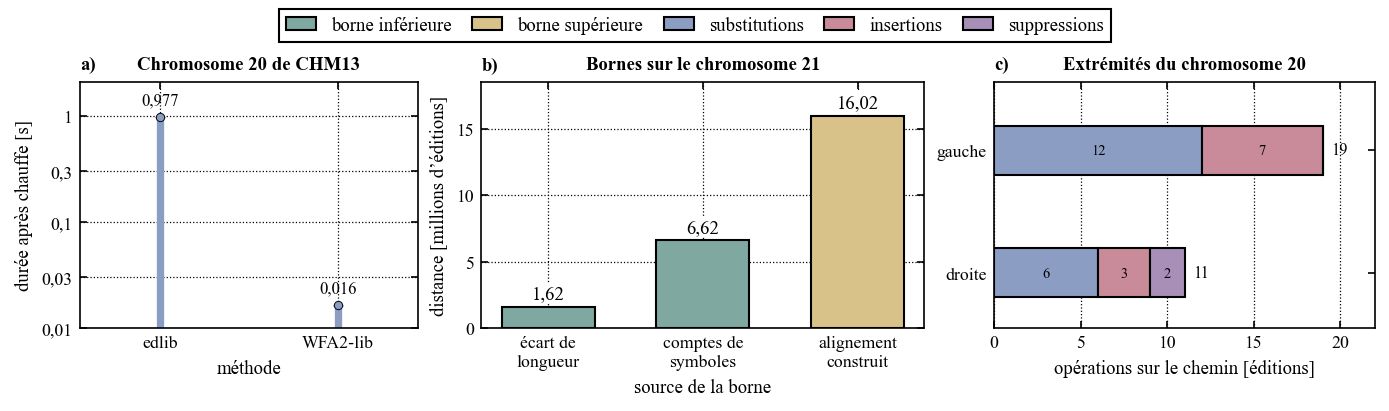

In [29]:
# Calcul terminé ou observation censurée sur les deux chromosomes entiers.
wh_raw = nv_csv(RES / "human/whole/838443/trials.csv")
wh_manifest = pd.read_csv(RES / "human/whole/manifest.tsv", sep="\t").set_index("case")
assert wh_raw.input_sha256.eq(wh_raw.case.map(wh_manifest.sha256)).all()
wh_bounds = nv_csv(RES / "human/whole/bounds.csv").iloc[0]
assert wh_bounds.lower == max(wh_bounds.surplus_a, wh_bounds.surplus_b)
assert (
    wh_bounds.length_gap == abs(wh_bounds.m - wh_bounds.n)
    and wh_bounds.length_gap <= wh_bounds.lower <= wh_bounds.upper
)
wh_first = wh_raw[wh_raw.case.eq("chr20-assemblies")].copy()
assert wh_first.groupby("method").trial.nunique().eq(3).all()
assert wh_first.status.eq("ok").all() and pd.to_numeric(wh_first.distance).eq(30).all()
wh_first["seconds"] = pd.to_numeric(wh_first.seconds)
wh_second = wh_raw[wh_raw.case.eq("chr21-assemblies")].set_index("method")
wh_order = ["edlib", "wfa2"]
wh_labels = ["edlib", "WFA2-lib"]
wh_fig, wh_ax = plt.subplots(1, 3, figsize=(9.15, 2.65), width_ratios=[0.87, 1.14, 0.98])
wh_x = np.arange(2)
wh_hot = nv_csv(RES / "repeated/gh200/trials.csv")
wh_hot = wh_hot[wh_hot.warmup.eq(0) & wh_hot.case.eq("chr20-assemblies")]
assert wh_hot.groupby("algorithm").block.nunique().ge(5).all() and wh_hot.distance.eq(30).all()
for wh_xi, wh_alg in enumerate(wh_order):
    wh_values = wh_hot[wh_hot.algorithm.eq(wh_alg)].seconds
    wh_stats = nv_stats.add(28, "seconds", wh_alg, "chr20", wh_values, "fresh_process")
    wh_ax[0].vlines(wh_xi, 0.01, wh_stats["mean"], color=COLORS[0], linewidth=3.5)
    estimate(wh_ax[0], wh_xi, wh_stats, COLORS[0])
    value_label(wh_ax[0], wh_xi, wh_stats["high95"], wh_stats["mean"], 3)
wh_ax[0].set(ylabel="durée après chauffe [s]", xticks=[0, 1], xticklabels=wh_labels, xlabel="méthode")
wh_ax[0].set(yscale="log", ylim=(0.01, 2.1), xlim=(-0.45, 1.45))
wh_ax[0].set_yticks([0.01, 0.03, 0.1, 0.3, 1], ["0,01", "0,03", "0,1", "0,3", "1"])
wh_limits = [wh_bounds.length_gap, wh_bounds.lower, wh_bounds.upper]
wh_names = ["écart de\nlongueur", "comptes de\nsymboles", "alignement\nconstruit"]
for wh_idx, wh_count in enumerate(wh_limits):
    wh_low = wh_idx < 2
    wh_height = wh_count / 1e6
    wh_ax[1].bar(
        wh_idx,
        wh_height,
        width=0.60,
        color=COLORS[2 if wh_low else 3],
        edgecolor=INK,
        label="borne inférieure" if wh_low else "borne supérieure",
    )
    wh_ax[1].annotate(
        f"{wh_height:.2f}".replace(".", ","),
        (wh_idx, wh_height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        bbox=dict(facecolor=PAPER, edgecolor=PAPER, pad=0.3),
    )
wh_ax[1].set_xticks(range(3), wh_names)
wh_ax[1].set(
    ylabel="distance [millions d’éditions]",
    xlabel="source de la borne",
    ylim=(0, 1.16 * max(wh_limits) / 1e6),
)
assert wh_second.status.eq("wall_limit_120s").all()
wh_edits = pd.read_csv(RES / "human/whole/chr20-edits.tsv", sep="\t")
wh_gaps = wh_edits.start_a.to_numpy()[1:] - wh_edits.end_a.to_numpy()[:-1]
wh_cut = int(np.argmax(wh_gaps)) + 1
wh_long = int(wh_gaps[wh_cut - 1])
assert wh_edits.length.sum() == 30 and len(wh_edits) == 27
assert wh_long == 66_209_720
assert wh_edits.start_b.iloc[wh_cut] - wh_edits.end_b.iloc[wh_cut - 1] == wh_long
wh_offset = np.zeros(2)
wh_operation_colors = [COLORS[0], COLORS[1], COLORS[5]]
for wh_i, (wh_op, wh_name) in enumerate(
    [("X", "substitutions"), ("I", "insertions"), ("D", "suppressions")]
):
    wh_counts = [
        wh_part.loc[wh_part.operation.eq(wh_op), "length"].sum()
        for wh_part in [wh_edits.iloc[:wh_cut], wh_edits.iloc[wh_cut:]]
    ]
    wh_ax[2].barh(
        [0, 1],
        wh_counts,
        left=wh_offset,
        height=0.4,
        color=wh_operation_colors[wh_i],
        edgecolor=INK,
        label=wh_name,
    )
    for wh_j, wh_count in enumerate(wh_counts):
        if wh_count:
            wh_ax[2].text(
                wh_offset[wh_j] + wh_count / 2, wh_j, str(wh_count), ha="center", va="center", fontsize=7
            )
        nv_stats.add(
            28,
            "edits_" + wh_op,
            "optimal_path",
            ["left", "right"][wh_j],
            [wh_count],
            "alignment_path",
            independent=False,
        )
    wh_offset += wh_counts
category_rows(wh_ax[2], ["gauche", "droite"], "opérations sur le chemin [éditions]")
for wh_j, wh_count in enumerate(wh_offset):
    value_label(wh_ax[2], wh_count, wh_j, wh_count, 0, horizontal=True)
wh_ax[2].set_xlim(0, 22)
label_panels(wh_ax)
column_titles(
    wh_ax, ("Chromosome 20 de CHM13", "Bornes sur le chromosome 21", "Extrémités du chromosome 20")
)
legend_above(wh_fig, wh_ax, ncol=5)
nv_save(wh_fig, "biology/chromosomes_entiers")

*Figure 28.* Le chromosome 20 est mesuré sur Grace dans cinq processus indépendants par bibliothèque, après un alignement de chauffe. Les trois bornes du chromosome 21 sont déterministes. Les deux calculs plafonnés à 120 s se sont achevés sans score. Le panneau c) donne l’effectif de chaque opération dans le chemin optimal du chromosome 20, de part et d’autre du plus long segment identique.

<sub>Code : [bench/human/whole_chromosomes.py](../bench/human/whole_chromosomes.py), [results/human/whole/manifest.tsv](../results/human/whole/manifest.tsv), [results/human/whole/838443/trials.csv](../results/human/whole/838443/trials.csv), [bench/human/chromosome_bounds.py](../bench/human/chromosome_bounds.py), [results/human/whole/bounds.csv](../results/human/whole/bounds.csv), [results/repeated/gh200/trials.csv](../results/repeated/gh200/trials.csv), [results/human/whole/chr20-edits.tsv](../results/human/whole/chr20-edits.tsv), [bench/human/assembly_edits.py](../bench/human/assembly_edits.py).</sub>

Les deux versions de CHM13 donnent une distance globale de 30 sur le chromosome 20. Sur Grace, le calcul WFA2-lib prend 0,016 (écart-type 0,000, IC 95 % de 0,016 à 0,017) s en moyenne. Les 27 segments non identiques du chemin rejoué comprennent 19 éditions à gauche et 11 à droite. Le segment central de 66 209 720 correspondances couvre 99,9992 % du premier assemblage. Cette distribution décrit le chemin entre deux versions de CHM13. Sur le chromosome 21 entre GRCh38 et CHM13, les deux processus atteignent la limite de 120 s. Le déséquilibre des comptes de symboles impose une borne inférieure plus élevée que la seule différence de longueur. Le coût du chemin construit fournit la borne supérieure.

Le panel suivant étend la comparaison entre versions à 18 chromosomes nucléaires entiers.

<p><strong><u>Synthèse.</u></strong> Pour le chromosome 21, la distance reste comprise entre 6 621 364 et 16 015 052 éditions.<br>Les deux observations plafonnées donnent seulement une information de censure pour la durée.</p>

<a id="cohorte-chromosomique"></a>

## Distances sur un panel de chromosomes entiers

<hr>

La figure 29 relie la distance globale entre deux versions d’un chromosome humain entier à la durée de son alignement.

Le panel comprend les 17 autosomes non acrocentriques et le chromosome X des versions 1.0 et 1.1 de CHM13. Chaque comparaison aligne les deux chaînes entières du même chromosome. Le panel mesure les révisions de l’assemblage du même échantillon. Sur un chemin optimal, $d=N_{ins}+N_{del}+N_{sub}$ et $|m-n|=|N_{ins}-N_{del}|$. Il en résulte $d-|m-n|=N_{sub}+2\min(N_{ins},N_{del})$. La condition $|m-n|\le d$ fournit une borne vérifiable pour chaque paire. Le journal de révision VCF décrit un chemin construit. Après vérification de la référence à chaque position, le premier allèle du génotype reconstruit la séquence. Les substitutions résiduelles vers la cible complètent ce chemin. [Consortium T2T, versions de CHM13](https://github.com/marbl/CHM13/blob/master/Earlier_assembly_releases_and_associated_data.md) · [Nurk et coll., 2022](https://doi.org/10.1126/science.abj6987) · [Mc Cartney et coll., 2022](https://doi.org/10.1038/s41592-022-01440-3)

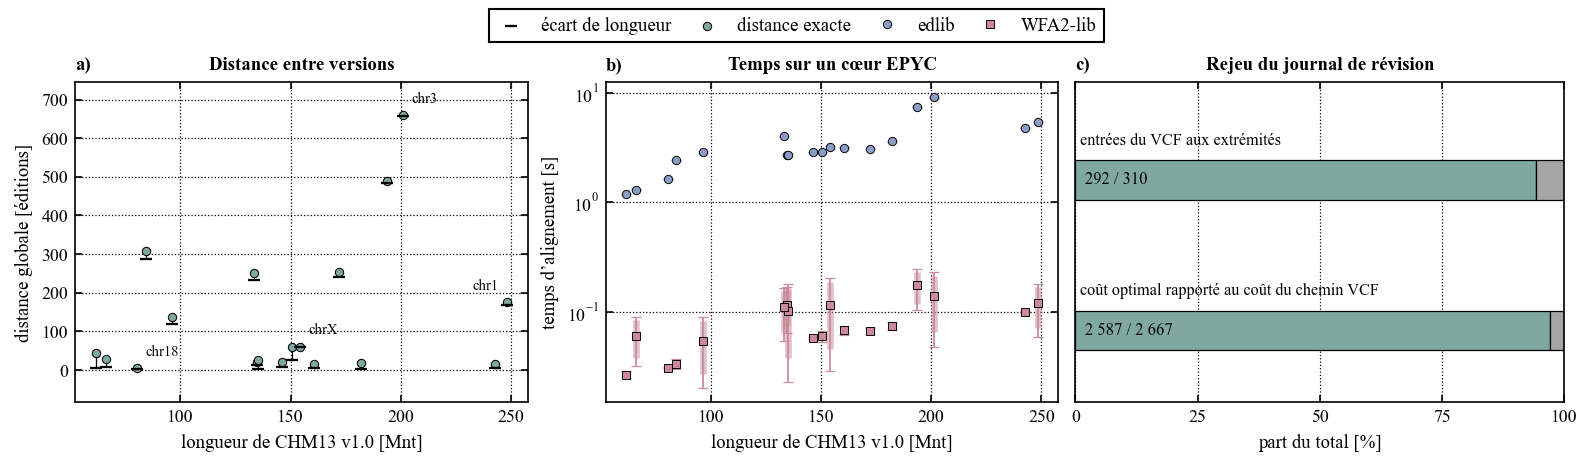

In [30]:
# Chaque marqueur représente un chromosome nucléaire complet entre deux versions.
cp_dir = RES / "human/chromosome-panel"
cp_inputs = pd.read_csv(cp_dir / "manifest.tsv", sep="\t").set_index("case")
cp_raw = nv_csv(cp_dir / "trials.csv")
assert cp_inputs.index.is_unique and len(cp_inputs) == 18
assert cp_raw.groupby("case").distance.nunique().eq(1).all()
assert not cp_raw.duplicated(["case", "method", "block"]).any()
cp_scores = cp_raw.drop_duplicates("case").set_index("case").distance
assert set(cp_inputs.index) == set(cp_scores.index)
cp_data = cp_inputs.assign(distance=cp_scores)
assert (cp_data.m - cp_data.n).abs().le(cp_data.distance).all()
assert cp_raw.groupby(["case", "method"]).block.nunique().eq(5).all()
cp_bounds = (cp_data.m - cp_data.n).abs()
cp_lower = cp_bounds.sum() / cp_scores.sum()
for cp_label, cp_value in [
    ("summed_edits", cp_scores.sum()),
    ("summed_length_difference", cp_bounds.sum()),
    ("min_indel_fraction", cp_lower),
]:
    nv_stats.add(
        29, cp_label, "v1.0/v1.1", "panel_18", [cp_value], "complete_chromosome_panel", independent=False
    )
cp_sequence = cp_data.sort_values("m")
cp_fig, cp_axes = plt.subplots(1, 3, figsize=(10.5, 3.02), gridspec_kw={"width_ratios": [1, 1, 1.08]})
cp_low = (cp_sequence.m - cp_sequence.n).abs()
cp_axes[0].vlines(cp_sequence.m / 1e6, cp_low, cp_sequence.distance, color=INK, lw=0.6, zorder=1)
cp_axes[0].scatter(
    cp_sequence.m / 1e6,
    cp_low,
    marker="_",
    color=INK,
    linewidth=1.1,
    s=32,
    zorder=4,
    label="écart de longueur",
)
cp_axes[0].scatter(
    cp_sequence.m / 1e6,
    cp_sequence.distance,
    marker="o",
    color=COLORS[2],
    edgecolor=INK,
    linewidth=0.5,
    label="distance exacte",
)
for cp_case in dict.fromkeys(["chr1", cp_scores.idxmax(), cp_scores.idxmin(), "chrX"]):
    cp_x = cp_data.at[cp_case, "m"] / 1e6
    cp_y = cp_data.at[cp_case, "distance"]
    cp_axes[0].annotate(
        cp_case,
        (cp_x, cp_y),
        xytext=(-4 if cp_case == "chr1" else 4, 6),
        textcoords="offset points",
        ha="right" if cp_case == "chr1" else "left",
        fontsize=7,
    )
for cp_case, cp_d in cp_scores.items():
    nv_stats.add(29, "distance", "v1.0/v1.1", cp_case, [cp_d], "complete_chromosome", independent=False)
cp_axes[0].margins(y=0.13)
cp_axes[0].set(xlabel="longueur de CHM13 v1.0 [Mnt]", ylabel="distance globale [éditions]")
for cp_i, (cp_alg, cp_label) in enumerate([("edlib", "edlib"), ("wfa2", "WFA2-lib")]):
    cp_obs = cp_raw[cp_raw.method.eq(cp_alg)]
    for cp_case, cp_vals in cp_obs.groupby("case"):
        cp_rec = nv_stats.add(29, "seconds", cp_alg, cp_case, cp_vals.seconds, "fresh_warmed_process")
        cp_rss = nv_stats.add(
            29, "rss_mib", cp_alg, cp_case, cp_vals.peak_rss_kib / 1024, "fresh_warmed_process"
        )
        estimate(
            cp_axes[1],
            cp_data.at[cp_case, "m"] / 1e6,
            cp_rec,
            COLORS[cp_i],
            marker="os"[cp_i],
            label=cp_label,
        )
cp_axes[1].set(yscale="log", xlabel="longueur de CHM13 v1.0 [Mnt]", ylabel="temps d’alignement [s]")
cp_patch = nv_csv(cp_dir / "release-patch.csv").set_index("case").reindex(cp_data.index)
assert cp_patch.upper_bound.ge(cp_scores).all()
assert (cp_patch.upper_bound == cp_patch.path_cost + cp_patch.residual_substitutions).all()
assert (cp_patch.patched_sha256.eq(cp_patch.target_sha256) == cp_patch.residual_substitutions.eq(0)).all()
cp_counts = cp_patch[
    ["records", "terminal_records", "path_cost", "residual_substitutions", "upper_bound"]
].sum()
for cp_metric, cp_total in cp_counts.items():
    nv_stats.add(
        29,
        cp_metric,
        "release_vcf",
        "panel_18",
        [cp_total],
        "official_release_records",
        independent=False,
    )
cp_gap = cp_counts.upper_bound - cp_scores.sum()
nv_stats.add(
    29,
    "constructed_minus_optimum",
    "release_vcf",
    "panel_18",
    [cp_gap],
    "official_release_records",
    independent=False,
)
cp_comparisons = [
    (cp_counts.terminal_records, cp_counts.records, "entrées du VCF aux extrémités"),
    (cp_scores.sum(), cp_counts.upper_bound, "coût optimal rapporté au coût du chemin VCF"),
]
for cp_y, (cp_num, cp_den, cp_text) in zip([1, 0], cp_comparisons):
    cp_share = 100 * cp_num / cp_den
    cp_axes[2].barh(cp_y, cp_share, height=0.26, color=COLORS[2], edgecolor=INK, lw=0.6)
    cp_axes[2].barh(
        cp_y, 100 - cp_share, left=cp_share, height=0.26, color=COLORS[4], edgecolor=INK, lw=0.6
    )
    cp_axes[2].text(1, cp_y + 0.21, cp_text, fontsize=7.8, va="bottom")
    cp_label = f"{cp_num:,.0f} / {cp_den:,.0f}".replace(",", " ")
    cp_axes[2].text(2, cp_y, cp_label, fontsize=8, va="center")
cp_axes[2].set(xlabel="part du total [%]", xlim=(0, 100), ylim=(-0.48, 1.65), yticks=[])
cp_axes[2].set_xticks([0, 25, 50, 75, 100])
label_panels(cp_axes)
column_titles(
    cp_axes, ("Distance entre versions", "Temps sur un cœur EPYC", "Rejeu du journal de révision")
)
legend_above(cp_fig, cp_axes, ncol=4)
nv_save(cp_fig, "biology/cohorte_chromosomes")

*Figure 29.* Pour chaque chromosome, le segment vertical relie l’écart de longueur au score exact. Chaque durée résume cinq nouveaux processus sur EPYC, avec une première exécution de chauffe après chargement du FASTA. Les deux méthodes rendent le score seul. Le panneau c rapporte les entrées terminales à toutes les entrées du VCF puis la somme des distances exactes au coût du chemin construit. Les deux totaux couvrent les 18 chromosomes.

<sub>Code : [scripts/datasets/chm13_panel.py](../scripts/datasets/chm13_panel.py), [bench/human/chromosome-panel/trial.cpp](../bench/human/chromosome-panel/trial.cpp), [results/human/chromosome-panel/manifest.tsv](../results/human/chromosome-panel/manifest.tsv), [results/human/chromosome-panel/trials.csv](../results/human/chromosome-panel/trials.csv), [bench/human/chromosome-panel/release_patch.py](../bench/human/chromosome-panel/release_patch.py), [results/human/chromosome-panel/release-patch.csv](../results/human/chromosome-panel/release-patch.csv).</sub>

Le chromosome 1 contient 248,39 Mnt dans CHM13 v1.0. Sa distance entre versions vaut 176 éditions. Le temps moyen sur un cœur vaut 0,119 (écart-type 0,049, IC à 95 % de 0,058 à 0,180) s pour WFA2 et 5,418 s pour edlib. Le score maximal du panel atteint 659 éditions sur chr3. Les écarts de longueur totalisent 2 330 bases pour 2 587 éditions. Au moins 90,07 % des opérations de tout ensemble de chemins optimaux sont donc des insertions ou suppressions. Pour 15 des 18 temps WFA2, la demi-largeur de l’IC dépasse 5 % de la moyenne. Sur 310 entrées du VCF, 292 tiennent entièrement dans les 1 000 premières ou dernières bases d’un chromosome. Le rejeu retrouve exactement 14 chromosomes. Pour chr1, chr3, chr4 et chrX, il reste une substitution à la première base. Le coût local des allèles totalise 2 663 éditions. Le chemin complété en compte 2 667, soit 80 de plus que les optima globaux.

La position des révisions permet de mesurer la concentration de leur coût le long des chromosomes.

<p><strong><u>Synthèse.</u></strong> Les 18 comparaisons portent sur des versions successives d’un même assemblage.<br>Les entrées terminales du journal de révision représentent 94,2 % des entrées de ce panel.</p>

<a id="paysage-chromosomique"></a>

## Localisation des révisions de l’assemblage humain

<hr>

La figure 30 situe les révisions du VCF du consortium dans les coordonnées de CHM13 v1.0. Sur un chromosome de longueur $L_i$, l’entrée $i$ occupe l’intervalle de référence $[a_i,b_i)$. La plus petite marge qui contient l’intervalle entier a pour largeur $r_i=\min(b_i,L_i-a_i)$. Un allèle qui franchit la limite d’une marge reste en dehors du cumul à cette largeur.

$$F_w(h)=\frac{\sum_i w_i\,\mathbf{1}_{r_i\le h}}{\sum_i w_i}.$$

Le poids $w_i=1$ donne la fraction d’entrées dans les marges de largeur $h$. Avec $w_i=d(\mathrm{REF}_i,\mathrm{ALT}_i)$, la courbe donne leur part du coût d’édition des allèles. Ces fractions décrivent les dix-huit chromosomes du panel. [Versions de CHM13](https://github.com/marbl/CHM13/blob/master/Earlier_assembly_releases_and_associated_data.md) · [Mc Cartney et coll.](https://doi.org/10.1038/s41592-022-01440-3)

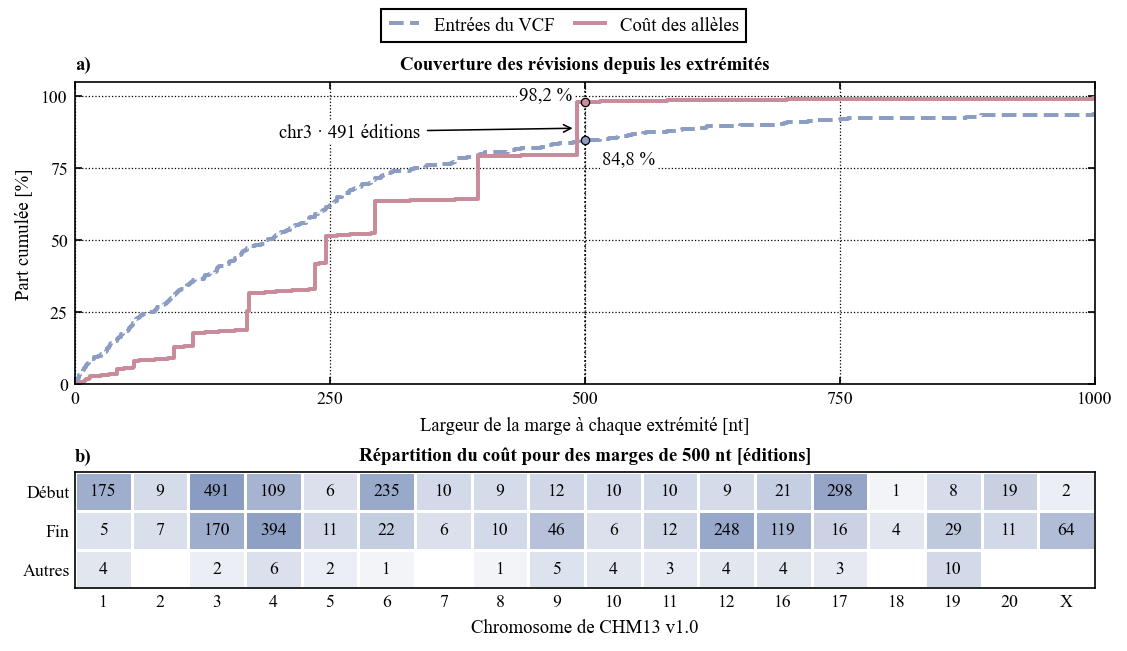

In [31]:
from studies.chromosome_landscape import (
    make_figure as lc_figure, read_panel as lc_panel, region_costs as lc_regions,
)

lc_records, lc_lengths = lc_panel(ROOT)
lc_width = 500
lc_costs = lc_regions(lc_records, lc_lengths.index, lc_width)
for lc_side, lc_row in lc_costs.iterrows():
    for lc_chrom, lc_value in lc_row.items():
        nv_stats.add(30, "allele_edit_cost", lc_side, lc_chrom, [lc_value], "complete_release_panel",
                     independent=False)
lc_inside = lc_records.loc[lc_records.radius <= lc_width]
for lc_metric, lc_share in [
    ("record_percent", 100 * len(lc_inside) / len(lc_records)),
    ("allele_cost_percent", 100 * lc_inside.allele_cost.sum() / lc_records.allele_cost.sum()),
]:
    nv_stats.add(30, lc_metric, "both_chromosome_ends", lc_width, [lc_share],
                 "complete_release_panel", independent=False)
nv_save(lc_figure(lc_records, lc_costs, lc_width), "biology/paysage_chromosomique", vector=True, alt='Position des révisions entre deux versions de CHM13, rapportée aux extrémités des chromosomes.')

*Figure 30.* Le panneau a) donne la part des entrées du VCF et de leur coût en fonction de la largeur de chaque marge terminale. Le panneau b) répartit ce coût entre les deux marges de 500 nt et les autres entrées de chaque chromosome. La teinte croît avec le logarithme de un plus le coût. Les cases blanches valent zéro.

<sub>Code : [python/studies/chromosome_landscape.py](../python/studies/chromosome_landscape.py), [intervalles de référence](../results/human/chromosome-panel/release-intervals.csv), [bilan du rejeu](../results/human/chromosome-panel/release-patch.csv).</sub>

La marche à 492 nt provient d’une délétion de 491 bases au début du chromosome 3. Cet allèle porte 18,4 % des 2 663 éditions du VCF sur le panel. Les quatre substitutions résiduelles du rejeu s’ajoutent à ce total pour construire la borne supérieure. Une substitution intérieure sur le chromosome 9 se trouve à plus de 16 Mnt de l’extrémité la plus proche.

<p><strong><u>Synthèse.</u></strong> Sur les 18 chromosomes, les marges de 500 nt occupent 18 000 des 2 643 920 725 bases de référence.<br>Elles contiennent 84,8 % des entrées du VCF et 98,2 % du coût de leurs allèles.</p>

<a id="methodes-distance"></a>

## Méthodes exactes sensibles à la distance

<hr>

La figure 31 examine la réduction du temps de calcul lorsque les erreurs se concentrent dans une bande ou dans un intervalle court.

La bande adaptative cherche d’abord un chemin de faible coût dans un couloir autour de la diagonale. Si le seuil est insuffisant, elle élargit le couloir jusqu’à obtenir un score inférieur ou égal au seuil. La variante `banded-trim` supprime aussi le préfixe et le suffixe communs avant ce calcul. En distance d’édition unitaire, deux lettres terminales identiques peuvent être appariées gratuitement. Supprimer ces extrémités conserve donc le score. Pour un seuil $k$, un chemin dont le coût est inférieur ou égal à $k$ reste dans $|i-j|\leq k$. L’implémentation double $k$ après chaque essai infructueux. Le temps gagné par le retrait des extrémités dépend de leur longueur. [Ukkonen, recherche à seuil](https://doi.org/10.1016/S0019-9958%2885%2980046-2)

Les deux allocations emploient un cœur du même nœud EPYC. Les deux méthodes en bande utilisent le second banc, avec edlib et WFA2-lib comme témoins. Les autres méthodes viennent du premier banc. Chaque bloc lance un processus par méthode, chauffe la paire puis mesure dix appels. Les deux modes Rust d’A*PA2 rendent également le chemin. Les écarts entre allocations peuvent peser sur les comparaisons entre familles.

QuickEd, de Doblas et coll., estime une borne de coût avant de reconstruire un alignement en bande. A*PA2, de Groot Koerkamp, associe programmation dynamique bit-parallèle, élargissement de bande et guidage heuristique. Ding et coll. proposent une autre famille d’algorithmes parallèles dont le travail dépend de la distance. La figure compare A*PA2 simple et complet aux cinq autres configurations sur les mêmes entrées. Les résultats de Ding et coll. restent bibliographiques. Sassy, de R. Beeloo et R. Groot Koerkamp, recherche les occurrences approchées d’un motif dans un texte. Le programme mm2-plus accélère le placement et l’alignement de segments par minimap2, une tâche différente du calcul d’un unique score global exact. [QuickEd, 2025](https://doi.org/10.1093/bioinformatics/btaf112) · [A*PA2, 2024](https://doi.org/10.4230/LIPIcs.WABI.2024.17) · [Ding et coll., 2023](https://doi.org/10.4230/LIPIcs.ESA.2023.40) · [Sassy, 2026](https://doi.org/10.1093/bioinformatics/btag244) · [mm2-plus, 2026](https://doi.org/10.1093/bioinformatics/btag083)

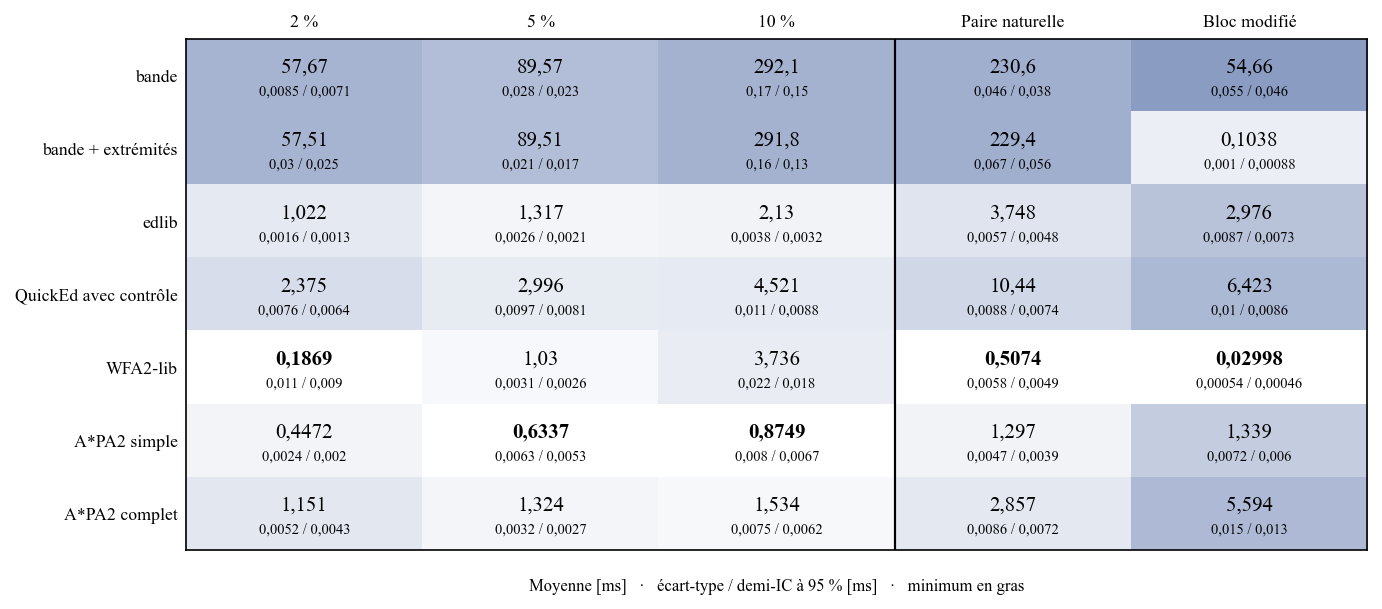

In [32]:
# Essais des méthodes exactes à entrée et machine identiques.
al_root = RES / "alternatives/romeo/838762"
al_cases_observed = nv_csv(al_root / "cases.csv").set_index("case")
al_valid = ["20k-0.02", "20k-0.05", "20k-0.1", "chr21-50k", "chr21-center128"]
al_ext = nv_csv(al_root / "trials.csv")
al_ext = al_ext[al_ext.case.isin(al_valid) & al_ext.variant.ne("quicked-stock")]
assert al_ext.correct.eq(1).all() and al_ext.exact.eq(al_ext.case.map(al_cases_observed.exact)).all()
al_bridge = nv_csv(RES / "repeated/epyc-bands/trials.csv")
al_bridge = al_bridge[al_bridge.warmup.eq(0)]
assert al_bridge.input_sha256.eq(al_bridge.case.map(al_cases_observed.sha256)).all()
assert al_bridge.distance.eq(al_bridge.case.map(al_cases_observed.exact)).all()
assert al_bridge.groupby(["case", "algorithm", "block"]).call.nunique().eq(10).all()
assert al_ext.groupby(["case", "variant", "block"]).call.nunique().eq(10).all()
al_ext = al_ext.groupby(["case", "variant", "block"], as_index=False).seconds.mean()
al_band = al_bridge[al_bridge.algorithm.isin(["banded", "banded-trim"])].rename(
    columns={"algorithm": "variant"}
)
al_band = al_band.groupby(["case", "variant", "block"], as_index=False).seconds.mean()
al_ok = pd.concat([al_ext, al_band], ignore_index=True)
assert al_ok.groupby(["case", "variant"]).block.nunique().eq(8).all()
assert al_ok.groupby("case").variant.nunique().eq(7).all()
al_methods = {
    "banded": "bande",
    "banded-trim": "bande + extrémités",
    "edlib": "edlib",
    "quicked-certified": "QuickEd avec contrôle",
    "wfa2": "WFA2-lib",
    "astarpa2-simple": "A*PA2 simple",
    "astarpa2-full": "A*PA2 complet",
}
al_cols = ["2 %", "5 %", "10 %", "Paire naturelle", "Bloc modifié"]
al_means = np.empty((len(al_methods), len(al_valid)))
al_rows = []
for al_i, al_key in enumerate(al_methods):
    al_row = []
    for al_j, al_case in enumerate(al_valid):
        al_obs = al_ok[al_ok.case.eq(al_case) & al_ok.variant.eq(al_key)].seconds * 1000
        al_rec = nv_stats.add(31, "milliseconds", al_case, al_key, al_obs, "independent_process_mean_10_calls")
        al_means[al_i, al_j] = al_rec["mean"]
        al_row.append(al_rec)
    al_rows.append(al_row)
al_fig, al_ax = plt.subplots(figsize=(9.1, 3.95))
al_ratio = al_means / al_means.min(axis=0)
al_log_ratio = np.log10(al_ratio)
al_ax.imshow(al_log_ratio, cmap=ct_plot.powder_cmap(), aspect="auto",
             vmin=0, vmax=2 * al_log_ratio.max(), interpolation="nearest")

def al_fmt(value, digits=2):
    return np.format_float_positional(value, precision=digits, fractional=False, trim="-").replace(".", ",")

for al_i, al_row in enumerate(al_rows):
    for al_j, al_rec in enumerate(al_row):
        al_mean = al_rec["mean"]
        al_delta = al_rec["high95"] - al_mean
        al_ax.text(al_j, al_i-0.11, al_fmt(al_mean, 4), ha="center", va="center",
                   fontweight="bold" if al_ratio[al_i,al_j] == 1 else "normal", fontsize=10)
        al_ax.text(al_j, al_i+0.21, f"{al_fmt(al_rec['sd'])} / {al_fmt(al_delta)}",
                   ha="center", va="center", fontsize=7.0)
al_ax.set(xticks=range(len(al_cols)), xticklabels=al_cols,
          yticks=range(len(al_methods)), yticklabels=list(al_methods.values()))
al_ax.xaxis.tick_top()
al_ax.tick_params(length=0, pad=4)
al_ax.grid(False)
al_ax.axvline(2.5, color=INK, linewidth=1.05)
al_ax.text(0.5, -0.055, "Moyenne [ms]   ·   écart-type / demi-IC à 95 % [ms]   ·   minimum en gras",
           transform=al_ax.transAxes, ha="center", va="top", fontsize=8)
al_port = nv_csv(RES / "alternatives/wfa-portability/838814/trials.csv")
assert al_port.groupby(["case", "variant", "block"]).call.nunique().eq(10).all()
assert al_port.groupby("case").score.nunique().eq(1).all()
al_runmean = al_port.groupby(["case", "block", "variant"]).seconds.mean().unstack()
for al_case, al_run in al_runmean.groupby("case"):
    al_port_ratio = al_run.portable / al_run.stock
    nv_stats.add(
        31,
        "separate_portability_ratio",
        "WFA2 portable/stock",
        al_case,
        al_port_ratio,
        "paired_process_block",
    )
nv_save(al_fig, "comparison/methodes_exactes")

*Figure 31.* Les sept méthodes traitent trois paires synthétiques de 20 knt (à gauche du filet) et deux intervalles humains (à droite). Chaque case donne la moyenne de huit processus sur EPYC, puis l’écart-type et la demi-largeur de l’IC à 95 %, en millisecondes. Au sein d’une colonne, le fond s’assombrit avec le logarithme du rapport au temps minimal, indiqué en gras.

<sub>Code : [results/alternatives/romeo/838762/trials.csv](../results/alternatives/romeo/838762/trials.csv), [results/repeated/epyc-bands/trials.csv](../results/repeated/epyc-bands/trials.csv), [results/alternatives/romeo/838762/cases.csv](../results/alternatives/romeo/838762/cases.csv), [results/alternatives/wfa-portability/838814/trials.csv](../results/alternatives/wfa-portability/838814/trials.csv), [results/alternatives/wfa-portability/838814/machine-code.csv](../results/alternatives/wfa-portability/838814/machine-code.csv).</sub>

Les sept configurations fournissent les mêmes coûts sur les cinq entrées communes sur EPYC. Sur l’intervalle naturel de 50 knt, WFA2-lib demande 0,507 (écart-type 0,006, IC 95 % de 0,503 à 0,512) ms. A*PA2 simple y prend 1,297 ms et restitue également le chemin. Pour la modification centrale sur 100 knt, le retrait des extrémités abaisse la moyenne de 54,66 à 0,104 ms. Les durées principales de WFA2-lib proviennent de la version amont épinglée. Une seconde allocation mesure la version portable du dépôt, avec des lectures par memcpy. Sous GCC 11, le code machine du noyau d’extension est identique à celui de l’amont. Sur les cinq entrées, les IC des rapports appariés incluent 1.

La reconstruction du chemin permet d’examiner le stockage des fronts de coût.

<p><strong><u>Synthèse.</u></strong> Sur l’intervalle naturel de 50 knt, les sept configurations concordent sur le score de 698.<br>L’emplacement des différences peut rendre le retrait d’extrémités plus intéressant que l’élargissement de la bande.</p>

<a id="fronts-bidirectionnels"></a>

## Reconstruction par fronts bidirectionnels

<hr>

La figure 32 mesure le coût du calcul de distance et de la reconstruction du chemin entre des intervalles homologues du chromosome 21.

BiWFA fait avancer un front depuis chaque extrémité des séquences. Leur rencontre fournit une coupure sur un chemin optimal. La récursion reconstruit ce chemin avec un espace de travail en $O(s)$ pour un coût optimal $s$, et un temps en $O(Ls)$ pour une longueur $L$. Les deux parcours WFA2 utilisent ici la distance d’édition unitaire. En mode score seul, le parcours unidirectionnel garde des fronts circulaires. En mode chemin, il conserve aussi les fronts nécessaires à la remontée. Le pic RSS inclut aussi les entrées, l’exécutable et le chemin renvoyé. [Marco-Sola et coll., 2023](https://doi.org/10.1093/bioinformatics/btad074)

Deux fenêtres de 250 knt commencent près des positions 34,5 et 37,0 millions sur GRCh38. Deux autres couvrent respectivement 2 et 4 Mnt. Chaque méthode calcule d’abord le score, puis une expérience distincte demande le chemin complet. Un appel sur la même paire chauffe chaque processus.

Une seconde campagne place trois bibliothèques dans le même binaire. A*PA2-full et BiWFA restituent chacun un CIGAR contrôlé après le chronométrage. QuickEd rejoue son chemin et vérifie le score avec edlib dans le temps mesuré, puis restitue le score. La fenêtre de 8 Mnt commence près de 14 Mnt sur le bras long. Les fenêtres de 2 et 4 Mnt commencent à 34 Mnt. [Groot Koerkamp, 2024](https://doi.org/10.4230/LIPIcs.WABI.2024.17) · [QuickEd, 2025](https://doi.org/10.1093/bioinformatics/btaf112)

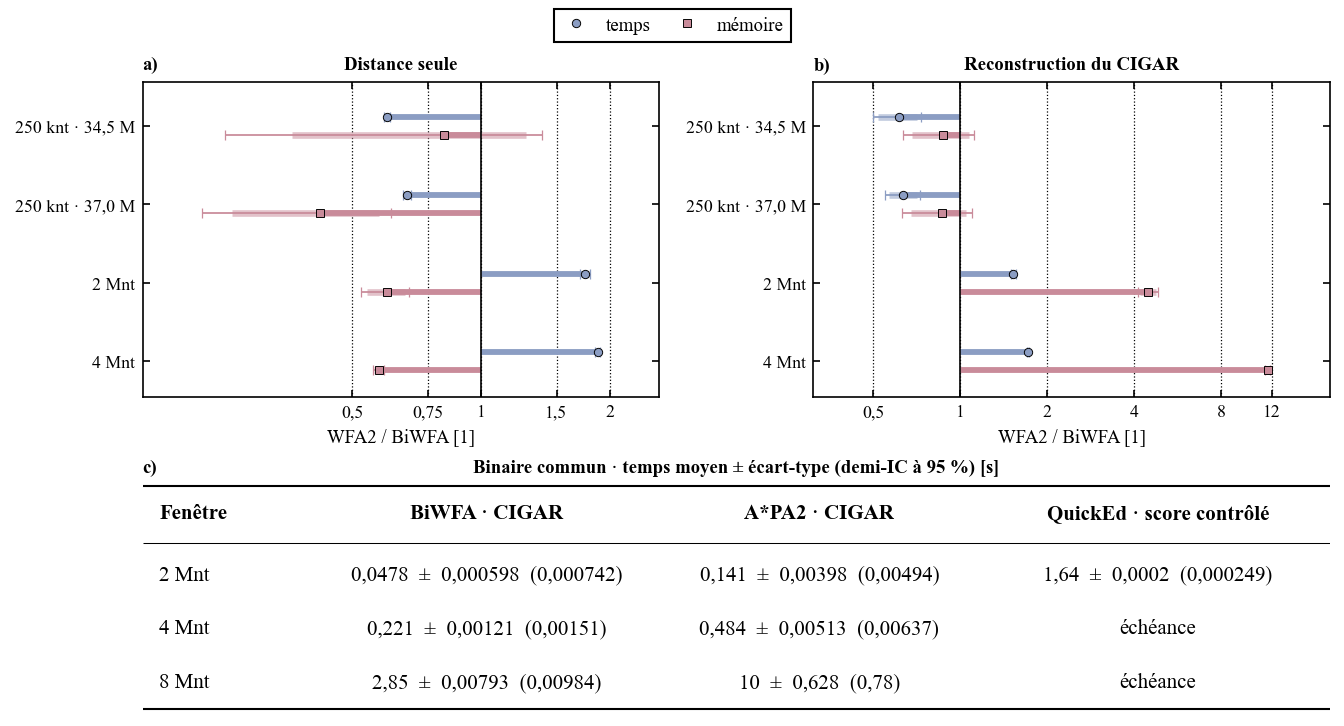

In [33]:
# Chaque case contient un nouveau processus, après chauffe sur cette même entrée.
bw_root = RES / "human/algorithms" / "838910"
bw_raw = nv_csv(bw_root / "trials.csv")
assert bw_raw.groupby("case").distance.nunique().eq(1).all()
assert not bw_raw.duplicated(["case", "algorithm", "scope", "block"]).any()
bw_order = ["locus-34m5", "locus-37m0", "chr21-2m", "chr21-4m"]
bw_names = ["250 knt · 34,5 M", "250 knt · 37,0 M", "2 Mnt", "4 Mnt"]
bw_algs = [("edlib", "edlib"), ("wfa2", "WFA2"), ("biwfa", "BiWFA")]
from studies.comparison_table import booktabs as bw_booktabs

bw_fig = plt.figure(figsize=(8.85, 4.75))
bw_grid = bw_fig.add_gridspec(2, 2, height_ratios=(1.25, 0.9))
bw_axes = [bw_fig.add_subplot(bw_grid[0, bw_i]) for bw_i in range(2)]
bw_table = bw_fig.add_subplot(bw_grid[1, :])
for (bw_case, bw_alg, bw_scope), bw_group in bw_raw.groupby(["case", "algorithm", "scope"]):
    assert bw_group.block.nunique() == len(bw_group)
    for bw_col, bw_metric, bw_factor in [("seconds", "seconds", 1), ("peak_rss_kib", "rss_mib", 1/1024)]:
        nv_stats.add(32, bw_metric, bw_scope + "/" + bw_alg, bw_case,
                     bw_factor * bw_group[bw_col], "fresh_warmed_process")
for bw_scope, bw_ax in zip(("score", "trace"), bw_axes):
    bw_sub = bw_raw[bw_raw.scope.eq(bw_scope)]
    for bw_i, bw_case in enumerate(bw_order):
        for bw_j, (bw_col, bw_label, bw_shape) in enumerate(
            [("seconds", "temps", "o"), ("peak_rss_kib", "mémoire", "s")]
        ):
            bw_pair = bw_sub[bw_sub.case.eq(bw_case)].pivot(index="block", columns="algorithm", values=bw_col)
            bw_ratio = bw_pair.wfa2 / bw_pair.biwfa
            assert len(bw_ratio) == 5 and bw_ratio.notna().all()
            bw_stat = nv_stats.add(32, bw_col + "_ratio", bw_scope + "/wfa2_over_biwfa",
                                   bw_case, bw_ratio, "paired_process_block")
            bw_pos = bw_i + (bw_j - 0.5) * 0.23
            bw_ax.hlines(bw_pos, 1, bw_stat["mean"], color=COLORS[bw_j], linewidth=2.8)
            estimate(bw_ax, bw_pos, bw_stat, COLORS[bw_j], marker=bw_shape, horizontal=True, label=bw_label)
    bw_ax.set_xscale("log")
    bw_ax.axvline(1, color=INK, linewidth=0.8)
    category_rows(bw_ax, bw_names, "WFA2 / BiWFA [1]")
bw_axes[0].set_xticks([0.5, 0.75, 1, 1.5, 2], ["0,5", "0,75", "1", "1,5", "2"])
bw_axes[1].set_xticks([0.5, 1, 2, 4, 8, 12], ["0,5", "1", "2", "4", "8", "12"])
# Cette deuxième réservation compare trois méthodes avec le même binaire.
bw_extra = nv_csv(RES / "alternatives/human/839083/trials.csv")
bw_compare = [
    ("biwfa", "BiWFA", 2, "^"),
    ("astarpa2-full", "A*PA2-full", 3, "D"),
    ("quicked-certified", "QuickEd · score vérifié", 5, "P"),
]
bw_extra_cases = ["chr21-2m", "chr21-4m", "chr21q-8m"]
assert bw_extra.groupby(["case", "algorithm"]).block.nunique().eq(5).all()
bw_ok = bw_extra[bw_extra.status.eq("ok")].copy()
bw_measures = ["seconds", "peak_rss_kib", "distance"]
bw_ok[bw_measures] = bw_ok[bw_measures].apply(pd.to_numeric)
assert bw_ok.groupby("case").distance.nunique().eq(1).all()
assert bw_ok[bw_ok.algorithm.ne("quicked-certified")].cigar_sha256.str.len().eq(64).all()
bw_capped = bw_extra[bw_extra.status.eq("timeout")]
assert set(bw_capped.algorithm) == {"quicked-certified"}
bw_table_rows = []
for bw_c, bw_case in enumerate(bw_extra_cases):
    bw_table_row = [["2 Mnt", "4 Mnt", "8 Mnt"][bw_c]]
    bw_fail = bw_capped[bw_capped["case"].eq(bw_case)]
    bw_skipped = bw_extra[bw_extra["case"].eq(bw_case) & bw_extra.status.eq("not_attempted")]
    if not bw_fail.empty:
        assert len(bw_fail) == 1 and len(bw_skipped) == 4
    for bw_a, (bw_alg, bw_name, bw_color, bw_marker) in enumerate(bw_compare):
        bw_complete = bw_ok[bw_ok["case"].eq(bw_case) & bw_ok.algorithm.eq(bw_alg)]
        if bw_complete.empty:
            assert bw_alg == "quicked-certified" and not bw_fail.empty
            bw_table_row.append("échéance")
            continue
        assert len(bw_complete) == 5
        for bw_j, (bw_column, bw_metric, bw_factor) in enumerate(
            [("seconds", "seconds", 1), ("peak_rss_kib", "rss_mib", 1 / 1024)]
        ):
            bw_est = nv_stats.add(
                32,
                bw_metric,
                "839083/" + bw_alg,
                bw_case,
                bw_complete[bw_column] * bw_factor,
                "fresh_warmed_process",
            )
            if bw_column == "seconds":
                bw_fmt = lambda v: np.format_float_positional(v, precision=3, fractional=False, trim="-").replace(".", ",")
                bw_table_row.append(f"{bw_fmt(bw_est['mean'])}  ±  {bw_fmt(bw_est['sd'])}  ({bw_fmt(bw_est['high95']-bw_est['mean'])})")
    bw_table_rows.append(bw_table_row)
bw_booktabs(bw_table, ["Fenêtre", "BiWFA · CIGAR", "A*PA2 · CIGAR", "QuickEd · score contrôlé"],
            bw_table_rows, widths=[0.15, 0.28, 0.28, 0.29])
label_panels([*bw_axes, bw_table])
column_titles(bw_axes, ("Distance seule", "Reconstruction du CIGAR"))
column_titles([bw_table], ("Binaire commun · temps moyen ± écart-type (demi-IC à 95 %) [s]",))
legend_above(bw_fig, bw_axes, ncol=2)
nv_save(bw_fig, "comparison/biwfa_humain")

*Figure 32.* Les rapports WFA2/BiWFA comparent, dans chaque bloc, le temps et le pic résident sur un cœur EPYC. Une valeur supérieure à un indique un avantage à BiWFA pour la grandeur considérée. Le tableau donne les durées d’une seconde allocation, avec cinq processus après chauffe par estimation. « Échéance » désigne le processus QuickEd interrompu à 120 s, lecture et chauffe comprises. Les quatre répétitions suivantes n’ont pas été lancées.

<sub>Code : [src/libraries/wfa2/wfa_adapter.c](../src/libraries/wfa2/wfa_adapter.c), [bench/human/algorithms/trial.cpp](../bench/human/algorithms/trial.cpp), [results/human/algorithms/838910/trials.csv](../results/human/algorithms/838910/trials.csv), [results/human/algorithms/838910/cases.csv](../results/human/algorithms/838910/cases.csv), [results/human/algorithms/838910/dispatch.csv](../results/human/algorithms/838910/dispatch.csv), [bench/quicked/human/trial.cpp](../bench/quicked/human/trial.cpp), [bench/quicked/human/measure.py](../bench/quicked/human/measure.py), [results/alternatives/human/839083/trials.csv](../results/alternatives/human/839083/trials.csv), [results/alternatives/human/839083/summary.csv](../results/alternatives/human/839083/summary.csv).</sub>

Sur la fenêtre de quatre millions de bases, le chemin bidirectionnel prend 0,219 (écart-type 0,001, IC à 95 % de 0,217 à 0,220) s. Le processus atteint en moyenne 54,0 Mio avec BiWFA et 627,0 Mio avec WFA2 unidirectionnel. Le rapport apparié des pics entre les deux parcours vaut 11,61. Le score seul présente une autre hiérarchie de mémoire. Sur les quatre entrées, le processus bidirectionnel occupe davantage de mémoire que WFA2 unidirectionnel. Pour les deux fenêtres de 250 knt, WFA2 unidirectionnel restitue aussi le chemin plus vite que BiWFA.

Temps après chauffe en secondes, moyenne et IC à 95 %.

| Fenêtre | A*PA2-full, chemin | BiWFA, chemin | QuickEd, score vérifié |
|---|---:|---:|---:|
| 2 Mnt | 0,1413 [0,1364 ; 0,1463] | 0,0478 [0,0471 ; 0,0486] | 1,6391 [1,6388 ; 1,6393] |
| 4 Mnt | 0,484 [0,478 ; 0,490] | 0,221 [0,220 ; 0,223] | plafond du processus |
| 8 Mnt | 10,040 [9,260 ; 10,820] | 2,845 [2,835 ; 2,855] | plafond du processus |

Sur les trois paires, BiWFA rend le chemin plus vite qu’A*PA2-full. Les 30 chemins rendus ont passé le contrôle indépendant. QuickEd aboutit sur la fenêtre de 2 Mnt sans reprise. Sur chacune des deux autres fenêtres, le premier processus atteint 120 s, lecture, chauffe et appel mesuré compris. Les quatre blocs suivants ne sont pas lancés. La durée de l’appel chaud y reste inconnue.

Des fenêtres emboîtées du même chromosome permettent ensuite d’examiner le coût du chemin à l’échelle de plusieurs dizaines de mégabases.

<p><strong><u>Synthèse.</u></strong> La fenêtre de 4 Mnt a un coût de 12 482 éditions.<br>Sur cette paire, les pics dépendent du sens de parcours des fronts et de la reconstruction demandée.</p>

<a id="bras-chromosome"></a>

## Alignement de fenêtres emboîtées du bras long

<hr>

La figure 33 suit quatre alignements globaux de longueur croissante sur le bras long du chromosome 21, aux mêmes origines dans GRCh38 et CHM13.

Les quatre fenêtres de GRCh38 mesurent 8, 16, 24 et 32 Mnt. Elles partagent leur première base. Leurs homologues occupent les intervalles correspondants dans CHM13. L’extension de la fenêtre accroît le nombre de bases et peut modifier la divergence $d/\max(m,n)$. L’entrée, le matériel et la fonction demandée définissent donc chaque chronométrage. BiWFA calcule le score ou restitue le chemin. WFA2 unidirectionnel rend le score. Sur 8 Mnt, edlib fournit aussi les deux services. Les fenêtres de GRCh38 contiennent respectivement 0, 0, 30 et 50 160 symboles N. CHM13 en contient zéro. La comparaison traite chacun de ces symboles à coût unitaire contre A, C, G ou T.

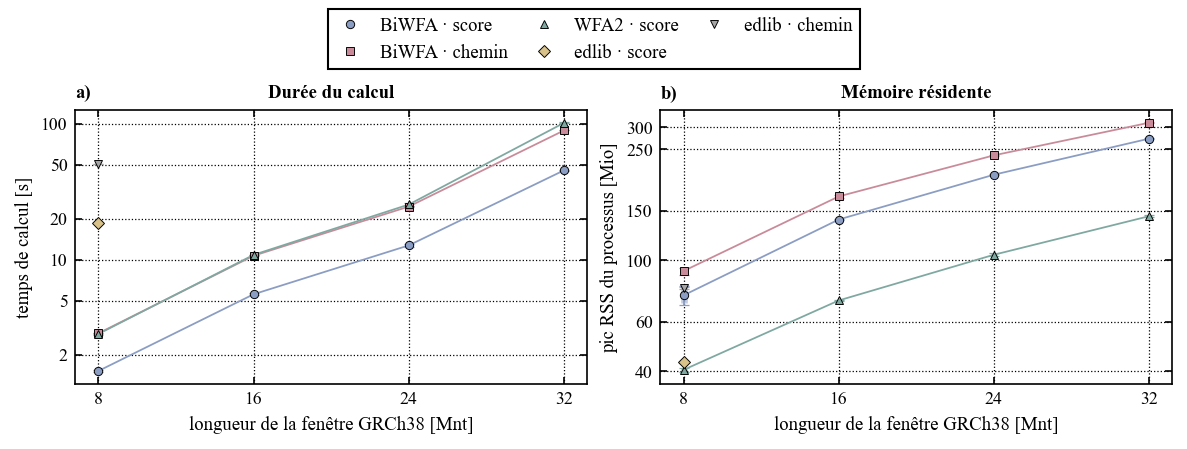

In [34]:
# Les entrées de tailles croissantes partagent leur borne gauche.
ar_root = RES / "human/algorithms/arm/838918"
ar_cases = nv_csv(ar_root / "cases.csv").set_index("case")
ar_data = nv_csv(ar_root / "trials.csv")
assert len(ar_cases) == 4 and ar_cases.start_a.nunique() == ar_cases.start_b.nunique() == 1
ar_ok = ar_data[ar_data.status.eq("ok")].copy()
ar_ok[["seconds", "peak_rss_kib", "distance"]] = ar_ok[["seconds", "peak_rss_kib", "distance"]].apply(
    pd.to_numeric
)
assert ar_cases.m.is_unique and ar_ok.groupby("case").distance.nunique().eq(1).all()
ar_full = ar_ok.groupby(["case", "algorithm", "scope"]).block.transform("size").eq(5)
ar_measured = ar_ok[ar_full]
assert ar_cases.N_b.eq(0).all()
assert ar_data.groupby(["case", "algorithm", "scope"]).block.nunique().eq(5).all()
ar_order = ar_cases.sort_values("m").index.tolist()
ar_x = ar_cases.loc[ar_order, "m"].to_numpy() / 1e6
for ar_case in ar_order:
    ar_input = ar_cases.loc[ar_case]
    ar_d = ar_ok[ar_ok["case"].eq(ar_case)].distance.unique().item()
    nv_stats.add(33, "distance", "nested_chr21q", ar_case, [ar_d], "complete_window", independent=False)
    nv_stats.add(
        33,
        "relative_distance",
        "nested_chr21q",
        ar_case,
        [ar_d / max(ar_input.m, ar_input.n)],
        "complete_window",
        independent=False,
    )
    nv_stats.add(
        33,
        "ambiguous_grch38",
        "nested_chr21q",
        ar_case,
        [ar_input.N_a],
        "complete_window",
        independent=False,
    )
ar_methods = [
    ("biwfa", "score", "BiWFA · score"),
    ("biwfa", "trace", "BiWFA · chemin"),
    ("wfa2", "score", "WFA2 · score"),
    ("edlib", "score", "edlib · score"),
    ("edlib", "trace", "edlib · chemin"),
]
ar_fig, ar_axes = plt.subplots(1, 2, figsize=(7.8, 2.9))
for ar_j, (ar_col, ar_metric, ar_unit, ar_factor) in enumerate(
    [
        ("seconds", "seconds", "temps de calcul [s]", 1),
        ("peak_rss_kib", "rss_mib", "pic RSS du processus [Mio]", 1 / 1024),
    ]
):
    for ar_i, (ar_algo, ar_scope, ar_caption) in enumerate(ar_methods):
        ar_values = (
            ar_measured[ar_measured.algorithm.eq(ar_algo) & ar_measured.scope.eq(ar_scope)].set_index(
                "case"
            )[ar_col]
            * ar_factor
        )
        nv_plot(
            ar_axes[ar_j],
            ar_values,
            ar_order,
            ar_x,
            33,
            ar_metric,
            ar_algo + "/" + ar_scope,
            "fresh_warmed_process",
            COLORS[ar_i],
            "os^Dv"[ar_i],
            joined=True,
            label=ar_caption,
        )
    ar_axes[ar_j].set(yscale="log", xlabel="longueur de la fenêtre GRCh38 [Mnt]", ylabel=ar_unit)
    ar_axes[ar_j].set_xticks(ar_x)
ar_axes[0].set_yticks([2, 5, 10, 20, 50, 100], ["2", "5", "10", "20", "50", "100"])
ar_axes[1].set_yticks([40, 60, 100, 150, 250, 300], ["40", "60", "100", "150", "250", "300"])
label_panels(ar_axes)
column_titles(ar_axes, ("Durée du calcul", "Mémoire résidente"))
legend_above(ar_fig, ar_axes, ncol=3)
nv_save(ar_fig, "comparison/bras_chromosome_biwfa")

*Figure 33.* Chaque point résume cinq blocs de processus neufs après une chauffe sur l’entrée entière. Les légendes indiquent si le programme rend une distance ou reconstruit également un CIGAR. Le pic RSS couvre tout le processus. Une taille utilise un cœur fixe et les quatre tailles se partagent quatre cœurs. Chaque exécution dispose de 720 s et 4 Gio d’espace adressable.

<sub>Code : [bench/human/algorithms/arm.py](../bench/human/algorithms/arm.py), [results/human/algorithms/arm/838918/cases.csv](../results/human/algorithms/arm/838918/cases.csv), [results/human/algorithms/arm/838918/trials.csv](../results/human/algorithms/arm/838918/trials.csv), [results/human/algorithms/arm/838918/summary.csv](../results/human/algorithms/arm/838918/summary.csv).</sub>

La distance augmente de 47 493 à 266 220 éditions entre 8 et 32 Mnt. Sur 32 Mnt, BiWFA rend le chemin en 89,77 (écart-type 0,11, IC à 95 % de 89,64 à 89,91) s. Le processus occupe 311,2 Mio en moyenne. Sur la même entrée, le calcul du score par WFA2 prend 102,04 s. Les fenêtres sont emboîtées et chacune correspond à une seule paire de séquences. Les 70 scores concordent avec le contrôle de distance et les 25 CIGAR ont été rejoués.

Les possibilités de partager la reconstruction sur plusieurs cœurs se mesurent ensuite sur des chromosomes entiers.

<p><strong><u>Synthèse.</u></strong> Sur le bras long du chromosome 21, la fenêtre de 32 Mnt étend celle de 8 Mnt par la droite.<br>Les courbes décrivent quatre longueurs d’une même région du génome.</p>

<a id="trace-chromosomes"></a>

## Reconstruction parallèle du chemin sur chromosomes entiers

<hr>

La figure 34 mesure le coût de restitution d’un chemin complet lorsque plusieurs fragments d’un chromosome peuvent être alignés en parallèle. Trois paires sont des chromosomes entiers de CHM13. Une fenêtre de 2 Mnt du chromosome 21 compare GRCh38 et CHM13. Les scores de ces quatre paires sont contrôlés indépendamment.

Des coupures candidates divisent les deux chaînes en fragments de même ordre. La somme $U$ des coûts optimaux des fragments donne d’abord une borne supérieure de la distance globale. Si $U=|m-n|$, elle atteint déjà la borne imposée par les longueurs. Sinon, des mots uniques de 16 bases situés dans des voisinages disjoints servent à justifier la conservation d’une coupure. Les fragments adjacents à une coupure non établie sont regroupés et recalculés. Pour les coupures retenues $(i_r,j_r)$, la distance exacte s’écrit $d(A,B)=\sum_r d(A[i_r:i_{r+1}],B[j_r:j_{r+1}])$. Les CIGAR des fragments sont réunis en fusionnant les opérations adjacentes de même type.

Pour chaque fragment, le solveur retire d’abord le préfixe et le suffixe communs aux deux chaînes. NvPD traite les petits intérieurs et BiWFA les grands. Les fragments parallèles utilisent jusqu’à huit cœurs EPYC. Un second essai maintient la même suppression des extrémités et le même choix de solveur tout en imposant un seul fragment.

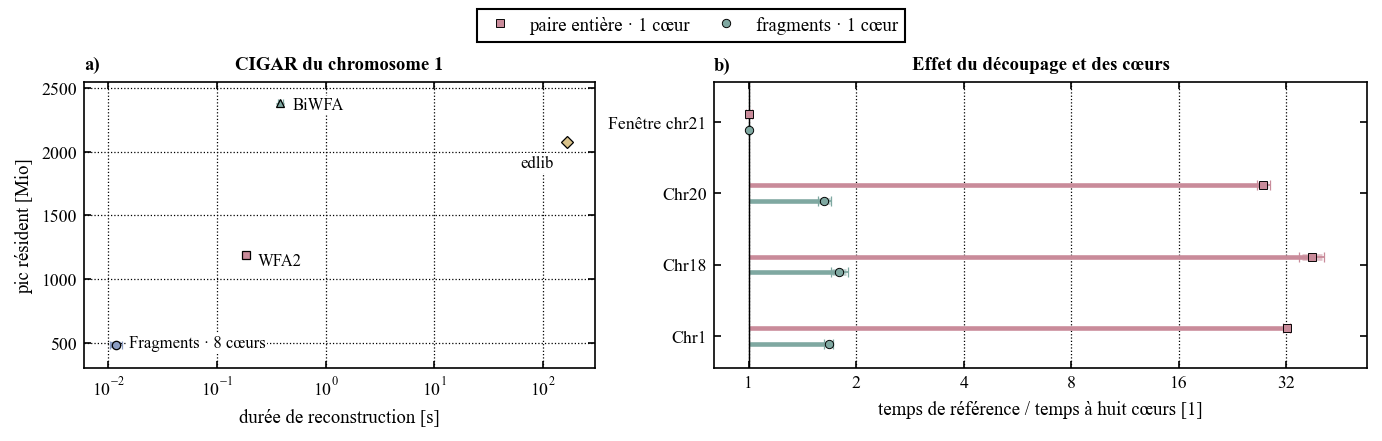

In [35]:
from studies.chromosome_trace import make_figure as px_make_figure

px_dir = RES / "trace/chromosomes"
px_main = nv_csv(px_dir / "839187/trials.csv")
px_ab = nv_csv(px_dir / "839193/trials.csv")
px_lib = nv_csv(px_dir / "839200/trials.csv")
for px_job, px_run in [("839187", px_main), ("839193", px_ab), ("839200", px_lib)]:
    assert px_run.groupby(["case", "mode", "method", "threads"]).block.nunique().eq(5).all()
    assert px_run.groupby("case").distance.nunique().eq(1).all()
    for (px_case, px_mode, px_m, px_p), px_g in px_run.groupby(["case", "mode", "method", "threads"]):
        px_key = f"{px_job}/{px_mode}/{px_m}/{px_p}"
        nv_stats.add(34, "seconds", px_key, px_case, px_g.seconds, "fresh_warmed_process")
        nv_stats.add(34, "rss_mib", px_key, px_case, px_g.peak_rss_kib / 1024, "fresh_warmed_process")
    for (px_case, px_mode), px_g in px_run.groupby(["case", "mode"]):
        px_q = px_g.pivot(index="block", columns=["method", "threads"], values="seconds")
        for px_p in (2, 4, 8):
            if ("split", 1) in px_q and ("split", px_p) in px_q:
                nv_stats.add(
                    34,
                    "strong_speedup",
                    f"{px_job}/{px_mode}/{px_p}",
                    px_case,
                    px_q["split", 1] / px_q["split", px_p],
                    "paired_process_block",
                )
        if ("split-all", 8) in px_q and ("split", 8) in px_q:
            nv_stats.add(
                34,
                "all_or_nothing_over_split",
                px_job + "/" + px_mode,
                px_case,
                px_q["split-all", 8] / px_q["split", 8],
                "paired_process_block",
            )
        if px_job == "839200":
            nv_stats.add(
                34,
                "edlib_over_split",
                "839200/trace",
                px_case,
                px_q["edlib", 1] / px_q["split", 8],
                "paired_process_block",
            )
        if ("trim-only", 1) in px_q:
            nv_stats.add(
                34,
                "trim_only_over_split",
                px_job + "/" + px_mode,
                px_case,
                px_q["trim-only", 1] / px_q["split", 8],
                "paired_process_block",
            )
px_leaf = px_main[px_main.method.eq("split") & px_main.threads.eq(8) & px_main["mode"].eq("trace")]
for px_case, px_g in px_leaf.groupby("case"):
    for px_count in ["accepted", "nvpd_leaves", "wavefront_leaves"]:
        assert px_g[px_count].nunique() == 1
        nv_stats.add(
            34, px_count, "split", px_case, [px_g[px_count].iloc[0]], "operation_count", independent=False
        )
px_fig = px_make_figure(ROOT)
nv_save(px_fig, "comparison/trace_chromosomes")

*Figure 34.* Sur le chromosome 1, chaque méthode occupe un point du plan temps–mémoire pour la restitution du CIGAR (cinq processus après chauffe). Les deux séries d’accélérations à huit cœurs partagent le même dénominateur. La première prend pour référence le solveur séquentiel appliqué à la paire après retrait des extrémités communes. La seconde conserve le découpage et fait varier le nombre de cœurs. Chaque rapport est calculé dans le même bloc.

<sub>Code : [src/cpu/split.cpp](../src/cpu/split.cpp), [bench/cpu/chromosome-trace/trial.cpp](../bench/cpu/chromosome-trace/trial.cpp), [python/studies/chromosome_trace.py](../python/studies/chromosome_trace.py), [results/trace/chromosomes/839187/trials.csv](../results/trace/chromosomes/839187/trials.csv), [results/trace/chromosomes/839193/trials.csv](../results/trace/chromosomes/839193/trials.csv), [results/trace/chromosomes/839200/trials.csv](../results/trace/chromosomes/839200/trials.csv).</sub>

Sur le chromosome 1, la reconstruction à huit cœurs prend 11,81 (écart-type 1,23, IC à 95 % de 10,29 à 13,34) ms dans la campagne des quatre méthodes sur la même paire. Le solveur hybride y retient six coupures. Les deux intérieurs qui demandent un alignement appellent BiWFA. Sur les chromosomes 18 et 20, chacun des deux intérieurs appelle NvPD dense. L’accélération du solveur hybride sur le chromosome 1 entre un et huit cœurs vaut 1,67. Dans l’expérience distincte de découpage, le rapport entre le temps avec un seul fragment élagué et le temps avec huit cœurs vaut 32,07 (écart-type 0,62, IC à 95 % de 31,29 à 32,84). Dans la campagne dédiée au CIGAR du chromosome 1, edlib prend en moyenne 14 110 fois le temps de la méthode par fragments à huit cœurs. 

Sur le chromosome 20, le solveur retient six des sept coupures proposées. Le traitement individuel des coupures accélère de 28,56 (écart-type 1,45, IC à 95 % de 26,76 à 30,36) fois le calcul par rapport au témoin qui exige que toutes soient justifiées. Sur la fenêtre de 2 Mnt, le rapport entre un seul fragment et la découpe vaut 1,002 (écart-type 0,017, IC à 95 % de 0,981 à 1,023). L’écart initial de longueur y dépasse le budget de 1 024 éditions prévu par le test de coupure.

Les chemins rendus permettent aussi de contrôler le score lorsque le calcul resserre sa bande.

<p><strong><u>Synthèse.</u></strong> Le chromosome 1 de 248 Mnt et la fenêtre de 2 Mnt ont des distances respectives de 176 et 5 599.<br>Le nombre de coupures justifiables détermine le travail qui peut être partagé sur ces deux entrées.</p>

<a id="certification-quicked"></a>

## Justesse et coût de la certification de QuickEd

<hr>

La figure 35 compare le score de QuickEd 1.2 à un témoin exact, puis mesure le temps de calcul avec contrôle du chemin.

Un alignement restreint à une bande peut exclure un chemin optimal. Sur le témoin périodique de 512 lettres, limiter les décalages à 63 impose un coût de 133. Une largeur de 64 permet le coût global de 128. Un défaut distinct touche le parcours inverse du code amont QuickEd sur certaines répétitions décalées. Sur les deux témoins du M1, l’instrumentation observe un indice de bit de $-1$ au bord de la bande alors que la borne de coût vaut déjà 128. Deux gardes vérifient désormais les limites du bloc. Le pilote compare le résultat au score d’edlib, élargit la bande en cas de désaccord et restitue le score exact si le désaccord persiste. Le résidu tracé est $e=d_{reported}-d_{exact}$. Une erreur nulle signifie que les deux scores concordent sur l’entrée testée. [QuickEd, Doblas et coll.](https://doi.org/10.1093/bioinformatics/btaf112)

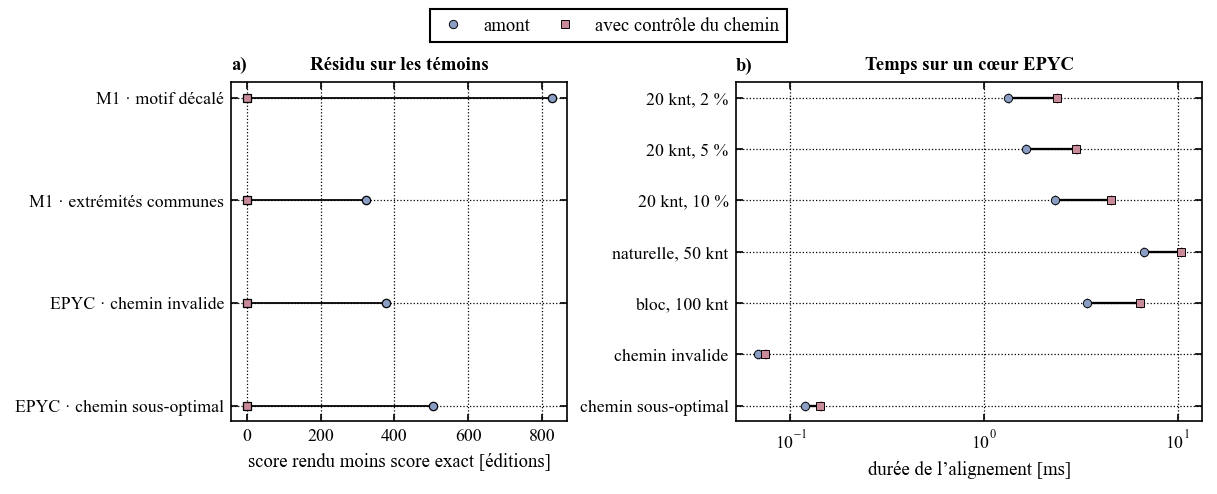

In [36]:
# Même entrée et même plateforme à l'intérieur de chaque comparaison.
qe_root = RES / "alternatives/romeo/838762"
qe_raw = nv_csv(qe_root / "trials.csv")
qe_cases = nv_csv(qe_root / "cases.csv").set_index("case")
qe_m1 = nv_csv(RES / "alternatives/diagnosis/correctness-m1.csv")
qe_sub = qe_raw[qe_raw.variant.str.startswith("quicked-")].copy()
assert qe_sub.exact.eq(qe_sub.case.map(qe_cases.exact)).all()
assert qe_sub.groupby(["case", "variant", "block"]).call.nunique().eq(10).all()
assert qe_sub.groupby(["case", "variant"]).block.nunique().eq(8).all()
assert qe_sub[qe_sub.variant.eq("quicked-certified")].correct.eq(1).all()
qe_x86 = qe_sub.groupby(["case", "variant"], as_index=False)[["score", "exact"]].first()
assert qe_sub.groupby(["case", "variant"]).score.nunique().eq(1).all()
qe_fig, qe_ax = plt.subplots(1, 2, figsize=(8.0, 3.2), width_ratios=[0.9, 1.25])
qe_witness = [
    ("M1", "periodic512", "motif décalé"),
    ("M1", "periodic256-tail", "extrémités communes"),
    ("EPYC", "native-impossible", "chemin invalide"),
    ("EPYC", "native-suboptimal", "chemin sous-optimal"),
]
for qe_i, (qe_host, qe_key, qe_short) in enumerate(qe_witness):
    qe_scores = qe_m1 if qe_host == "M1" else qe_x86
    qe_scores = qe_scores[qe_scores.case.eq(qe_key)].set_index("variant")
    qe_error = qe_scores.score - qe_scores.exact
    for qe_j, qe_var in enumerate(["quicked-stock", "quicked-certified"]):
        qe_val = float(qe_error.loc[qe_var])
        nv_stats.add(
            35,
            "score_error",
            qe_var,
            qe_host + "/" + qe_key,
            [qe_val],
            "fixed_witness",
            independent=False,
        )
        qe_ax[0].plot(
            qe_val,
            qe_i,
            marker="os"[qe_j],
            color=COLORS[qe_j],
            markeredgecolor=INK,
            label=["amont", "avec contrôle du chemin"][qe_j],
            zorder=3,
        )
    join(
        qe_ax[0],
        [qe_i, qe_i],
        qe_error.reindex(["quicked-stock", "quicked-certified"]),
        INK,
        horizontal=True,
    )
qe_ax[0].set(
    yticks=range(4),
    yticklabels=[qe_item[0] + " · " + qe_item[2] for qe_item in qe_witness],
    xlabel="score rendu moins score exact [éditions]",
)
qe_ax[0].invert_yaxis()
qe_groups = qe_sub.groupby(["case", "variant", "block"], as_index=False).seconds.mean()
qe_order = [
    "20k-0.02",
    "20k-0.05",
    "20k-0.1",
    "chr21-50k",
    "chr21-center128",
    "native-impossible",
    "native-suboptimal",
]
qe_labels = [
    "20 knt, 2 %",
    "20 knt, 5 %",
    "20 knt, 10 %",
    "naturelle, 50 knt",
    "bloc, 100 knt",
    "chemin invalide",
    "chemin sous-optimal",
]
qe_centers = qe_groups.groupby(["case", "variant"]).seconds.mean().unstack() * 1000
for qe_pos, qe_case in enumerate(qe_order):
    qe_pair = qe_centers.loc[qe_case, ["quicked-stock", "quicked-certified"]]
    qe_ax[1].hlines(qe_pos, qe_pair.min(), qe_pair.max(), color=INK, linewidth=1.1)
for qe_j, qe_var in enumerate(["quicked-stock", "quicked-certified"]):
    qe_time = qe_groups[qe_groups.variant.eq(qe_var)].set_index("case").seconds * 1000
    nv_plot(
        qe_ax[1],
        qe_time,
        qe_order,
        np.arange(len(qe_order)),
        35,
        "ms",
        qe_var,
        "independent_process_mean_10_calls",
        COLORS[qe_j],
        "os"[qe_j],
        horizontal=True,
        label=["amont", "avec contrôle du chemin"][qe_j],
    )
qe_ax[1].set(
    xscale="log", xlabel="durée de l’alignement [ms]", yticks=range(len(qe_order)), yticklabels=qe_labels
)
qe_ax[1].invert_yaxis()
label_panels(qe_ax)
column_titles(qe_ax, ("Résidu sur les témoins", "Temps sur un cœur EPYC"))
legend_above(qe_fig, qe_ax, ncol=2)
nv_save(qe_fig, "comparison/quicked")

*Figure 35.* Pour chaque témoin, le segment relie les résidus du score amont et du score avec contrôle du chemin. Sur EPYC, un second segment relie les temps moyens des deux variantes sur une entrée identique. Chaque moyenne porte sur huit processus préchauffés de dix appels. La durée amont inclut les cas où le score diverge de l’oracle.

<sub>Code : [src/libraries/quicked/quicked_adapter.c](../src/libraries/quicked/quicked_adapter.c), [results/alternatives/diagnosis/correctness-m1.csv](../results/alternatives/diagnosis/correctness-m1.csv), [results/alternatives/romeo/838762/trials.csv](../results/alternatives/romeo/838762/trials.csv), [results/alternatives/romeo/838762/cases.csv](../results/alternatives/romeo/838762/cases.csv), [results/alternatives/romeo/838762/trace.csv](../results/alternatives/romeo/838762/trace.csv), [results/alternatives/diagnosis/fixed-band.csv](../results/alternatives/diagnosis/fixed-band.csv), [results/alternatives/diagnosis/trace-m1.csv](../results/alternatives/diagnosis/trace-m1.csv).</sub>

Sur EPYC, le programme amont donne 506 au lieu de 128 sur un témoin et 760 au lieu de 256 sur l’autre. Les deux cas qui échouent sur M1 donnent des scores exacts dans ce binaire EPYC. Sur la paire naturelle de 50 knt, le calcul avec contrôle du chemin demande 10,436 (écart-type 0,009, IC 95 % de 10,428 à 10,443) ms. La durée inclut le contrôle des indices et le rejeu du chemin. Le nombre de contrôles réussis décrit les entrées mesurées et les appels rejoués.

Les distances exactes peuvent ensuite servir à construire une matrice pour une collection.

<p><strong><u>Synthèse.</u></strong> Le calcul avec contrôle du chemin restitue le score d’edlib pour les dix entrées du jeu EPYC.<br>Les 800 appels chronométrés ne constituent que dix cas de justesse distincts.</p>

<a id="phylogenie"></a>

## Structure des distances entre génomes de phages

<hr>

La figure 36 mesure les écarts aux hypothèses de chaque arbre reconstruit à partir des distances d’édition.

Pour trois feuilles, $g_3=d_{(3)}-d_{(2)}$ est la différence entre les deux plus grandes distances. Un arbre ultramétrique impose $g_3=0$. Pour quatre feuilles, on forme $d_{ij}+d_{kl}$ avec les trois appariements distincts. L’additivité impose l’égalité des deux plus grandes sommes, soit $g_4=0$. Le résidu entre deux feuilles est $r_{ij}=\ell_{ij}-d_{ij}$, où $\ell_{ij}$ est la somme des branches reliant les feuilles.

Chaque matrice contient les 2 016 distances des 64 génomes complets de φX174. Les programmes calculent la distance globale sur les chaînes déposées. Celle-ci dépend de l’origine choisie pour un chromosome circulaire. UPGMA joint les groupes dont la moyenne des distances est minimale et place toutes les feuilles à la même hauteur. Neighbor-Joining utilise les sommes de distances à tous les autres groupes et produit un arbre non enraciné. Les tests portent sur tous les triplets et tous les quartets. [Sokal et Michener, 1958](https://www.biodiversitylibrary.org/part/385476) · [Saitou et Nei, 1987](https://doi.org/10.1093/oxfordjournals.molbev.a040454)

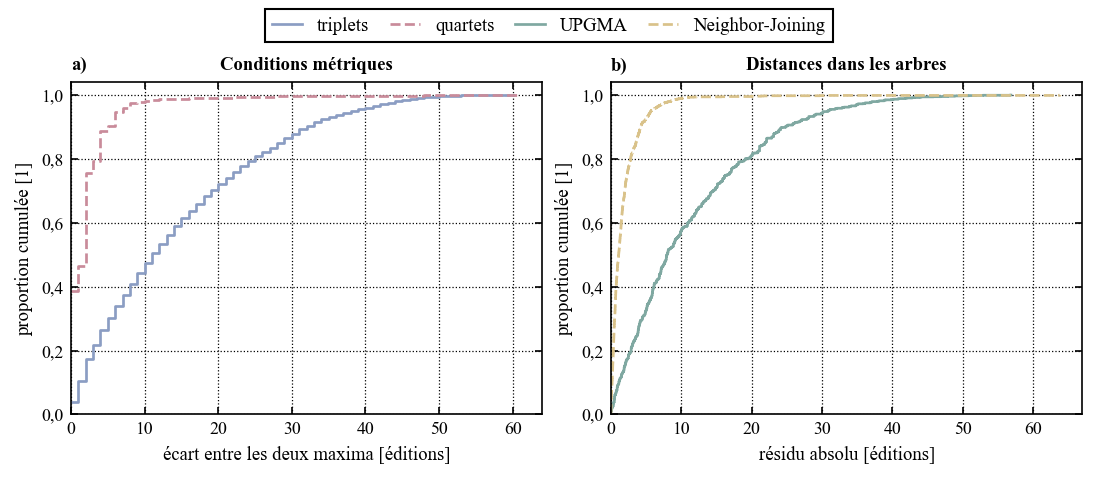

In [37]:
# Écarts aux conditions de distance et résidus de l'ajustement patristique.
phy_dir = RES / "phylogeny/phix174"
phy_gaps = nv_csv(phy_dir / "gaps.csv")
phy_fit = nv_csv(phy_dir / "pair_fit.csv")
assert len(phy_fit) == 2016
assert phy_gaps.groupby("criterion")["count"].sum().to_dict() == {
    "ultrametric": 41664,
    "four_point": 635376,
}
phy_fig, phy_ax = plt.subplots(1, 2, figsize=(7.2, 3.1))
for phy_ix, (phy_key, phy_name) in enumerate([("ultrametric", "triplets"), ("four_point", "quartets")]):
    phy_counts = phy_gaps[phy_gaps.criterion.eq(phy_key)].sort_values("gap")
    phy_ax[0].step(
        phy_counts.gap,
        phy_counts["count"].cumsum() / phy_counts["count"].sum(),
        where="post",
        color=COLORS[phy_ix],
        ls=["-", "--"][phy_ix],
        label=phy_name,
    )
for phy_ix, (phy_col, phy_algorithm) in enumerate(
    [("upgma_path", "UPGMA"), ("nj_path", "Neighbor-Joining")]
):
    phy_abs = np.sort((phy_fit[phy_col] - phy_fit.edit_distance).abs().to_numpy())
    phy_ax[1].step(
        phy_abs,
        np.arange(1, len(phy_abs) + 1) / len(phy_abs),
        where="post",
        color=COLORS[phy_ix + 2],
        ls=["-", "--"][phy_ix],
        label=phy_algorithm,
    )
phy_ax[0].set(xlabel="écart entre les deux maxima [éditions]", ylabel="proportion cumulée [1]")
phy_ax[1].set(xlabel="résidu absolu [éditions]", ylabel="proportion cumulée [1]")
for phy_axis in phy_ax:
    phy_axis.set(xlim=(0, None), ylim=(0, 1.04))
for phy_name, phy_col in [("upgma", "upgma_path"), ("nj", "nj_path")]:
    phy_rmse = np.sqrt(np.mean((phy_fit[phy_col] - phy_fit.edit_distance) ** 2))
    nv_stats.add(
        36, "path_rmse", phy_name, "phix64", [phy_rmse], "complete_distance_matrix", independent=False
    )
label_panels(phy_ax)
column_titles(phy_ax, ("Conditions métriques", "Distances dans les arbres"))
legend_above(phy_fig, phy_ax, ncol=4)
nv_save(phy_fig, "biology/phylogenie")

*Figure 36.* La proportion cumulée de triplets et de quartets donne la distribution des écarts aux deux conditions. Les résidus comparent ensuite la longueur du chemin dans chaque arbre à la distance globale observée entre les mêmes feuilles.

<sub>Code : [scripts/phylogeny/tree.py](../scripts/phylogeny/tree.py), [results/romeo/cohort-837271/matrix.tsv](../results/romeo/cohort-837271/matrix.tsv), [results/romeo/cohort-837271/upgma.nwk](../results/romeo/cohort-837271/upgma.nwk), [results/romeo/cohort-837271/nj.nwk](../results/romeo/cohort-837271/nj.nwk), [results/phylogeny/phix174/gaps.csv](../results/phylogeny/phix174/gaps.csv), [results/phylogeny/phix174/pair_fit.csv](../results/phylogeny/phix174/pair_fit.csv), [results/phylogeny/phix174/fit.csv](../results/phylogeny/phix174/fit.csv), [results/ncbi/phix174.tsv](../results/ncbi/phix174.tsv), [results/phylogeny/phix174/branches.csv](../results/phylogeny/phix174/branches.csv), [results/phylogeny/phix174/duplicate_sensitivity.csv](../results/phylogeny/phix174/duplicate_sensitivity.csv).</sub>

Les distances d’édition entre phages vont de 0 à 134, avec une médiane de 55. Seuls 1 661 des 41 664 triplets satisfont l’égalité ultramétrique. Parmi 635 376 quartets, 245 847 satisfont la condition des quatre points. L’erreur absolue maximale atteint toutefois 56,87 et 63,86 éditions respectivement. Neighbor-Joining réduit ainsi l’erreur moyenne sur ces paires tout en donnant le plus grand écart individuel. Les accessions HM753660.1 et HM753661.1 sont identiques dans la matrice. En retirant une copie, 38 275 des 39 711 triplets et 368 769 des 595 665 quartets présentent encore un écart. Pour chaque arête, la RMSE calculée sur les paires qui la traversent se situe entre 9,62 et 26,63 éditions avec UPGMA et entre 0,98 et 11,98 avec Neighbor-Joining.

Les coûts de calcul et l’ajustement aux distances éclairent le choix de la méthode pour une collection.

<p><strong><u>Synthèse.</u></strong> L’erreur quadratique moyenne des distances patristiques a pour racine 14,89 éditions sous UPGMA et 3,56 sous Neighbor-Joining.<br>La plus grande erreur individuelle reste plus élevée sous Neighbor-Joining sur cette collection.</p>

<a id="groupes-surveillance"></a>

## Concordance avec les groupes de surveillance

<hr>

La figure 37 confronte les distances au sein des groupes de surveillance à leur récupération par les reconstructions d’arbres.

Pour une partition en groupes, le nombre de paires intra-groupes vaut $\sum_g n_g(n_g-1)/2$. Un groupe est retrouvé lorsqu’une arête de longueur positive sépare exactement ses feuilles. Pour Neighbor-Joining, les deux côtés de l’arête sont examinés. La proportion représentée vaut $G_{\rm matched}/G_{\rm eligible}$.

Le panel SARS-CoV-2 comprend 64 accessions. Sept groupes de neuf séquences fournissent les comparaisons intra et inter-groupes. La référence isolée participe à la matrice, puis sort de ce contraste. Edlib, WFA2-lib et NvPD retrouvent les 2 016 distances globales avec une comparaison littérale des symboles. Les deux arbres des distances utilisent les 64 feuilles. L’arbre de surveillance UShER publié par UCSC couvre 52 accessions, avec au moins deux représentants pour six groupes. Les longueurs des branches UShER représentent des mutations sur un arbre de placement. [Turakhia et coll., 2021](https://doi.org/10.1038/s41588-021-00862-7)

Le contraste $D=\mathrm{median}(d_{between})-\mathrm{median}(d_{within})$ utilise les groupes déclarés. Le panneau a) retire chaque accession avec toutes ses paires puis recalcule $D$. Les 63 retraits énumèrent le panneau fini et conservent les dépendances entre distances partageant une accession.

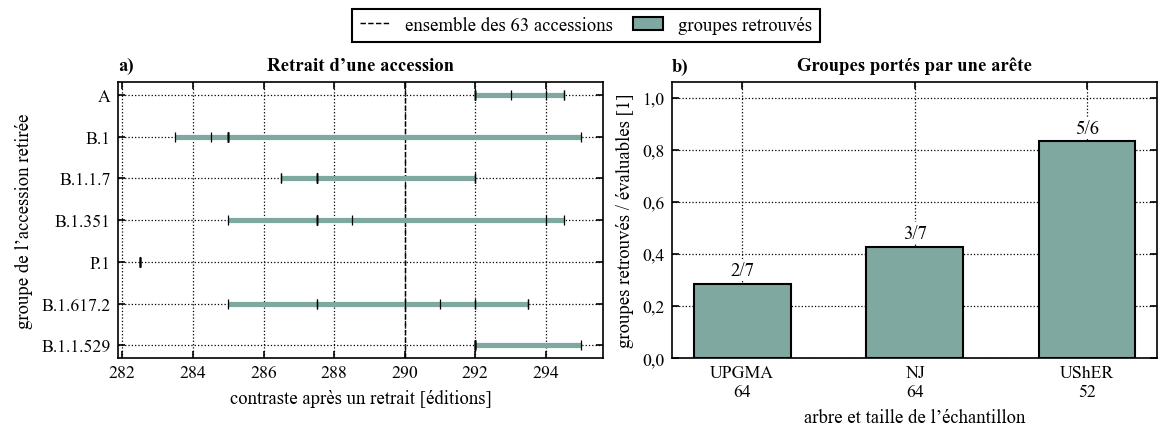

In [38]:
# Distances agrégées et groupes reconnus sur des arbres aux couvertures différentes.
sv_edit_dir = RES / "phylogeny/sars-edit"
sv_public_dir = RES / "phylogeny/sars-surveillance"
sv_verify = nv_csv(sv_edit_dir / "verification.csv")
assert sv_verify.records.eq(64).all() and sv_verify.pairs.eq(2016).all()
assert {"edlib", "wfa2"} <= set(sv_verify.algorithm) and sv_verify.matrix_sha256.nunique() == 1
sv_dist = nv_csv(sv_edit_dir / "pooled_distances.csv").set_index("comparison").loc[["within", "between"]]
sv_public_groups = nv_csv(sv_public_dir / "group_clades.csv")
sv_groups = pd.concat(
    [nv_csv(sv_edit_dir / "group_clades.csv"), sv_public_groups[sv_public_groups.tree.eq("public")]]
)
sv_groups = sv_groups[sv_groups.members.ge(2)].copy()
sv_groups["positive_edge_match"] = pd.to_numeric(sv_groups.positive_edge_match)
sv_match = (
    sv_groups.groupby("tree").positive_edge_match.agg(["sum", "count"]).loc[["upgma", "nj", "public"]]
)
assert sv_match["count"].tolist() == [7, 7, 6] and sv_match["sum"].tolist() == [2, 3, 5]
sv_splits = nv_csv(sv_public_dir / "shared_splits.csv")
assert sv_splits.tips.eq(52).all()
sv_meta = pd.read_csv(RES / "ncbi/sars_metadata.tsv", sep="	").set_index("id")
sv_meta = sv_meta[sv_meta.group.ne("reference")]
sv_distance = (
    pd.read_csv(sv_edit_dir / "matrix.tsv", sep="	", index_col=0)
    .loc[sv_meta.index, sv_meta.index]
    .to_numpy()
)
assert np.array_equal(sv_distance, sv_distance.T) and np.all(np.diag(sv_distance) == 0)
sv_left, sv_right = np.triu_indices(len(sv_meta), 1)
sv_values = sv_distance[sv_left, sv_right]
sv_group = sv_meta.group.to_numpy()
sv_within = sv_group[sv_left] == sv_group[sv_right]
assert int(sv_within.sum()) == 252 and int((~sv_within).sum()) == 1701


def sv_gap(mask):
    return np.median(sv_values[mask & ~sv_within]) - np.median(sv_values[mask & sv_within])


assert sv_dist.loc["within", "median"] == np.median(sv_values[sv_within])
assert sv_dist.loc["between", "median"] == np.median(sv_values[~sv_within])
sv_observed = sv_gap(np.ones(len(sv_values), dtype=bool))
sv_deleted = np.array(
    [sv_gap((sv_left != sv_id) & (sv_right != sv_id)) for sv_id in range(len(sv_group))]
)
sv_fig, sv_ax = plt.subplots(1, 2, figsize=(7.7, 2.85))
for sv_i, sv_name in enumerate(sv_meta.group.unique()):
    sv_selection = sv_deleted[sv_group == sv_name]
    sv_ax[0].hlines(sv_i, np.min(sv_selection), np.max(sv_selection), color=COLORS[2], lw=2.5)
    sv_ax[0].plot(sv_selection, np.full(len(sv_selection), sv_i), marker="|", ls="none", color=INK, ms=5)
sv_ax[0].axvline(sv_observed, **GUIDE, label="ensemble des 63 accessions")
sv_ax[0].set(
    yticks=range(sv_meta.group.nunique()),
    yticklabels=sv_meta.group.unique(),
    xlabel="contraste après un retrait [éditions]",
    ylabel="groupe de l’accession retirée",
)
sv_ax[0].invert_yaxis()
sv_fraction = sv_match["sum"] / sv_match["count"]
sv_ax[1].bar(
    np.arange(3),
    sv_fraction.values,
    width=0.56,
    color=COLORS[2],
    edgecolor=INK,
    label="groupes retrouvés",
)
for sv_i, (sv_kind, sv_row) in enumerate(sv_match.iterrows()):
    sv_ax[1].annotate(
        f"{int(sv_row['sum'])}/{int(sv_row['count'])}",
        (sv_i, sv_fraction.loc[sv_kind]),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        bbox=dict(facecolor=PAPER, edgecolor=PAPER, pad=0.4),
    )
sv_ax[1].set(
    ylabel="groupes retrouvés / évaluables [1]",
    xlabel="arbre et taille de l’échantillon",
    ylim=(0, 1.06),
)
sv_ax[1].set_xticks(np.arange(3), ["UPGMA\n64", "NJ\n64", "UShER\n52"])
for sv_stat, sv_value in [
    ("full", sv_observed),
    ("deletion_min", sv_deleted.min()),
    ("deletion_max", sv_deleted.max()),
]:
    nv_stats.add(
        37,
        "between_minus_within",
        sv_stat,
        "63_accessions",
        [sv_value],
        "finite_panel",
        independent=False,
    )
label_panels(sv_ax)
column_titles(sv_ax, ("Retrait d’une accession", "Groupes portés par une arête"))
legend_above(sv_fig, sv_ax, ncol=2)
nv_save(sv_fig, "biology/phylogenie_surveillance")

*Figure 37.* Chaque trait du panneau a) correspond au retrait d’une accession de son groupe. Le segment montre l’étendue des neuf retraits et la ligne pointillée le contraste du panneau complet. Les fractions du panneau b) comptent tous les groupes évaluables de chaque arbre.

<sub>Code : [scripts/phylogeny/phylo_groups.py](../scripts/phylogeny/phylo_groups.py), [results/phylogeny/sars-edit/verification.csv](../results/phylogeny/sars-edit/verification.csv), [results/phylogeny/sars-edit/pooled_distances.csv](../results/phylogeny/sars-edit/pooled_distances.csv), [results/phylogeny/sars-edit/group_clades.csv](../results/phylogeny/sars-edit/group_clades.csv), [results/phylogeny/sars-surveillance/group_clades.csv](../results/phylogeny/sars-surveillance/group_clades.csv), [results/phylogeny/sars-surveillance/shared_splits.csv](../results/phylogeny/sars-surveillance/shared_splits.csv), [results/phylogeny/sars-edit/censored.csv](../results/phylogeny/sars-edit/censored.csv), [results/phylogeny/sars-surveillance/overlap.csv](../results/phylogeny/sars-surveillance/overlap.csv), [results/ncbi/sars_metadata.tsv](../results/ncbi/sars_metadata.tsv), [results/phylogeny/sars-edit/matrix.tsv](../results/phylogeny/sars-edit/matrix.tsv).</sub>

Les 252 paires d’un même groupe ont une distance médiane de 112 éditions. Pour les 1 701 paires entre groupes, la médiane atteint 402. Les 63 retraits donnent un contraste compris entre 282,5 et 295 éditions, contre 290 pour l’ensemble. Cette étendue mesure la sensibilité au choix d’une accession dans ce panneau.

UPGMA retrouve deux des sept groupes et Neighbor-Joining en retrouve trois. Sur les feuilles représentées dans la référence publique, UShER en retrouve cinq sur six. Une comparaison distincte reconstruit les deux arbres de distances sur les mêmes 52 feuilles. Parmi les 27 bipartitions non triviales de longueur positive dans l’arbre public, six apparaissent sous UPGMA et huit sous Neighbor-Joining. Ce recouvrement décrit les topologies pour la sélection observée. NvPD a vérifié séparément les 2 016 coûts en 268,83 s sur Apple M1 Pro, en distribuant les paires entre six processus à un fil. Le calcul qui répartissait huit fils sur les colonnes d’une seule paire a atteint sa limite de 1 200 s pour la matrice. La comparaison littérale inclut 65 588 symboles ambigus sur 1 905 372 caractères.

La même cohorte permet de mesurer le changement de topologie induit par un calcul en bande.

<p><strong><u>Synthèse.</u></strong> Sur les 1 326 paires communes, la corrélation de Pearson entre distance d’édition et chemin UShER vaut 0,124.<br>Les deux mesures portent sur des objets différents, les chaînes déposées et les branches d’un arbre de placement.</p>

<a id="sensibilite-arbres"></a>

## Sensibilité de la topologie à la largeur de bande

<hr>

La figure 38 mesure comment une restriction géométrique du calcul des distances modifie les arbres de la cohorte publique de 64 génomes SARS-CoV-2.

La bande fixe retient les cellules $|i-j|\le b$. Sa distance $d_b$ est le coût optimal parmi les chemins qui restent dans la bande. Quand $b<|m-n|$, le point terminal est inaccessible. L’arbre de la cohorte entière exige les 2 016 distances. Pour étudier les bandes étroites sur les mêmes feuilles, une seconde expérience emploie $b_{ij}=\max(b,|m_i-m_j|)$ pour chaque paire. Chaque valeur de sa matrice provient d’un alignement réalisable. Un chemin optimal d’edlib entièrement contenu dans la bande prouve directement $d_b=d$. Dans les autres cas, la programmation dynamique dans la bande donne le score restreint. Les deux expériences réutilisent l’ordre des feuilles et les règles de départage de la matrice exacte.

Pour deux arbres, $RF=|S_1\,\triangle\,S_2|$ compte les partitions propres à un seul arbre. Le rapport $RF/(|S_1|+|S_2|)$ varie de 0 à 1. UPGMA conserve les groupes internes enracinés. Neighbor-Joining utilise les bipartitions internes sans racine. Les arêtes de longueur nulle participent à la topologie telle que le programme la rend. [Robinson et Foulds, 1981](https://doi.org/10.1016/0025-5564%2881%2990043-2)

Un témoin indépendant comporte huit jeux de 32 chaînes de longueur 384 sur l’alphabet 0 à 3. À chaque branche d’une construction binaire de profondeur cinq, quatre substitutions, une suppression et une insertion de même longueur modifient la chaîne. Leur longueur commune est tirée entre 1 et 24 caractères pour chaque branche. Le calcul compare toujours l’arbre de la bande à l’arbre des distances exactes du même jeu.

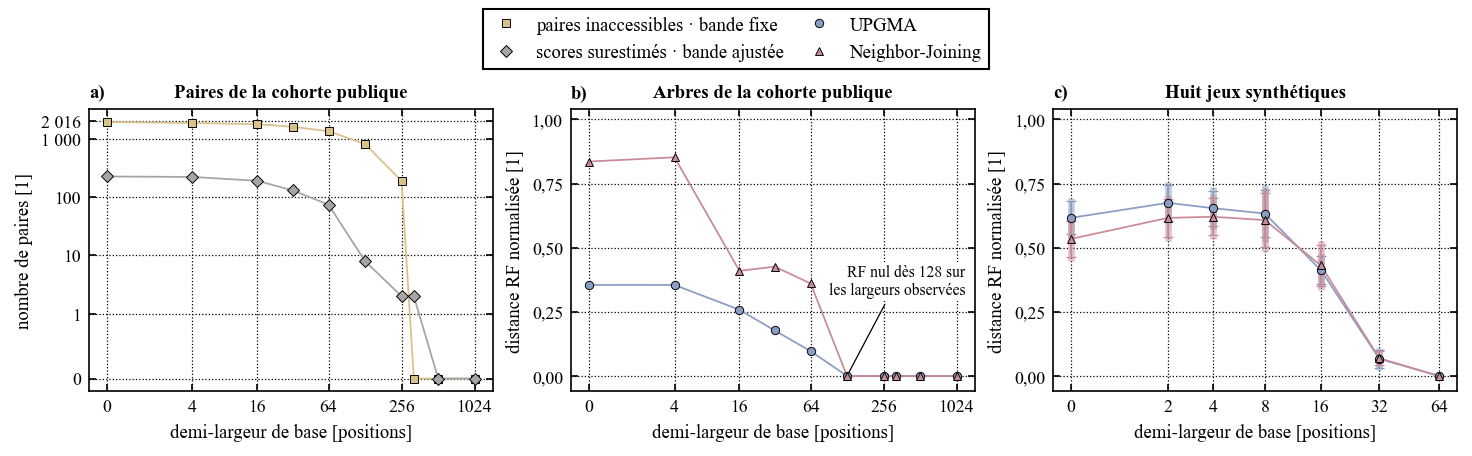

In [39]:
# Une ligne du panel décrit tout un jeu de feuilles à largeur fixée.
rf_root = RES / "phylogeny/sensitivity"
rf_score = nv_csv(rf_root / "panel/scores.csv")
rf_tree = nv_csv(rf_root / "panel/trees.csv")
rf_control = nv_csv(rf_root / "synthetic/trees.csv")
rf_neutral_scores = nv_csv(rf_root / "synthetic/scores.csv")
assert rf_score.feasible.add(rf_score.unreachable).eq(rf_score.pairs).all()
assert rf_tree.rf.eq(rf_tree.reference_parts + rf_tree.band_parts - 2 * rf_tree.shared_parts).all()
assert rf_control.groupby(["width", "method"]).study.nunique().eq(8).all()
rf_fixed = rf_score[rf_score.policy.eq("fixed")].set_index("width")
rf_floor = rf_score[rf_score.policy.eq("endpoint_floor")].set_index("width")
rf_widths = rf_fixed.index.tolist()
rf_pos = np.log2(1 + np.array(rf_widths))
rf_fig, rf_ax = plt.subplots(1, 3, figsize=(9.7, 2.95))
for rf_series, rf_data, rf_name, rf_color, rf_mark in [
    ("fixed_unreachable", rf_fixed.unreachable, "paires inaccessibles · bande fixe", COLORS[3], "s"),
    ("floor_overestimated", rf_floor.overestimated, "scores surestimés · bande ajustée", COLORS[4], "D"),
]:
    nv_plot(
        rf_ax[0],
        rf_data,
        rf_widths,
        rf_pos,
        38,
        "pairs",
        rf_series,
        "finite_panel",
        rf_color,
        rf_mark,
        joined=True,
        independent=False,
        label=rf_name,
    )
rf_ax[0].set_yscale("symlog", linthresh=1)
rf_ax[0].set_yticks([0, 1, 10, 100, 1000, 2016], ["0", "1", "10", "100", "1 000", "2 016"])
rf_ax[0].set_ylabel("nombre de paires [1]")
for rf_method, rf_name, rf_color, rf_mark in [
    ("upgma", "UPGMA", COLORS[0], "o"),
    ("nj", "Neighbor-Joining", COLORS[1], "^"),
]:
    rf_read = rf_tree[rf_tree.method.eq(rf_method) & rf_tree.policy.eq("endpoint_floor")].set_index(
        "width"
    )
    nv_plot(
        rf_ax[1],
        rf_read.normalized_rf,
        rf_widths,
        rf_pos,
        38,
        "normalized_rf",
        rf_method,
        "finite_panel",
        rf_color,
        rf_mark,
        joined=True,
        independent=False,
        label=rf_name,
    )
    rf_s = rf_control[rf_control.method.eq(rf_method)].set_index("width")
    rf_neutral_widths = sorted(rf_s.index.unique())
    nv_plot(
        rf_ax[2],
        rf_s.normalized_rf,
        rf_neutral_widths,
        np.log2(1 + np.array(rf_neutral_widths)),
        38,
        "synthetic_normalized_rf",
        rf_method,
        "independent_simulated_cohort",
        rf_color,
        rf_mark,
        joined=True,
        label=rf_name,
    )
for rf_field in ["feasible", "overestimated", "mean_excess", "max_excess", "widened"]:
    for rf_row in rf_score.itertuples(index=False):
        nv_stats.add(
            38,
            rf_field,
            rf_row.policy,
            rf_row.width,
            [getattr(rf_row, rf_field)],
            "finite_panel",
            independent=False,
        )
for rf_ax_id, rf_ticks in enumerate(
    [[0, 4, 16, 64, 256, 1024], [0, 4, 16, 64, 256, 1024], rf_neutral_widths]
):
    rf_ax[rf_ax_id].set_xticks(np.log2(1 + np.array(rf_ticks)), [str(w) for w in rf_ticks])
    rf_ax[rf_ax_id].set_xlabel("demi-largeur de base [positions]")
for rf_axis in rf_ax[1:]:
    rf_axis.set_ylabel("distance RF normalisée [1]")
    rf_axis.set_ylim(-0.06, 1.04)
    rf_axis.set_yticks([0, 0.25, 0.5, 0.75, 1])
rf_floor_tree = rf_tree[rf_tree.policy.eq("endpoint_floor")].groupby("width").normalized_rf.max().sort_index()
rf_first_stable = rf_floor_tree[rf_floor_tree[::-1].cummax()[::-1].eq(0)].index[0]
rf_ax[1].annotate(f"RF nul dès {rf_first_stable} sur\nles largeurs observées",
                  (np.log2(1 + rf_first_stable), 0), xytext=(0.975, 0.39), textcoords="axes fraction",
                  ha="right", va="center", fontsize=7.5,
                  bbox=dict(facecolor=PAPER, edgecolor="none", pad=1),
                  arrowprops=dict(arrowstyle="-", color=INK, lw=0.6))
label_panels(rf_ax)
column_titles(
    rf_ax, ("Paires de la cohorte publique", "Arbres de la cohorte publique", "Huit jeux synthétiques")
)
legend_above(rf_fig, rf_ax, ncol=2)
nv_save(rf_fig, "biology/sensibilite_arbres")

*Figure 38.* Le premier panneau compte les extrémités inaccessibles en bande fixe et les surestimations après élargissement minimal. Le deuxième utilise les 64 feuilles et les largeurs ajustées. Le troisième applique la bande fixe aux chaînes synthétiques de longueur égale. La position horizontale est proportionnelle à $\log_2(1+b)$. La moyenne, l’écart-type et l’IC à 95 % portent sur huit jeux générés indépendamment. Les nombres de la cohorte publique sont des dénombrements exhaustifs.

<sub>Code : [scripts/phylogeny/band_cost.cpp](../scripts/phylogeny/band_cost.cpp), [scripts/phylogeny/band_sensitivity.py](../scripts/phylogeny/band_sensitivity.py), [results/phylogeny/sars-edit/matrix.tsv](../results/phylogeny/sars-edit/matrix.tsv), [results/phylogeny/sensitivity/panel/scores.csv](../results/phylogeny/sensitivity/panel/scores.csv), [results/phylogeny/sensitivity/panel/trees.csv](../results/phylogeny/sensitivity/panel/trees.csv), [results/phylogeny/sensitivity/synthetic/trees.csv](../results/phylogeny/sensitivity/synthetic/trees.csv).</sub>

À demi-largeur fixe 64, 1 342 paires sur 2 016 sont inaccessibles. La première largeur qui couvre toutes les extrémités vaut 323. Deux distances y dépassent l’optimum, de 5 et 19 éditions. Leur effet topologique est nul pour les deux méthodes. À 512, les 2 016 scores concordent avec la matrice de référence.

Avec la largeur ajustée par paire et $b=64$, 74 scores dépassent l’optimum. UPGMA perd six groupes de référence et en gagne six (RF de 12 sur 124). Neighbor-Joining perd et gagne 22 bipartitions (RF de 44 sur 122). À $b=128$, huit scores restent surestimés et les deux topologies coïncident avec leurs références. La distance NJ passe de 102 à 104 entre les demi-largeurs 0 et 4, alors que les scores de toutes les paires diminuent ou restent constants. Sur les neuf entrées de longueur identique 29 580, les 36 scores sont déjà exacts à largeur nulle. Chaque comparaison garde son propre ensemble de feuilles.

Le choix du calcul peut ainsi être examiné à la fois par son coût et par la stabilité du résultat qui en dépend.

<p><strong><u>Synthèse.</u></strong> Une bande fixe de 323 positions de part et d’autre de la diagonale préserve les deux topologies sur ces 64 feuilles.<br>La demi-largeur 512 restitue aussi l’ensemble des distances individuelles.</p>

<a id="synthese"></a>

## Conclusion et critères de choix

<hr>

Pour deux longueurs $m,n$, NvPD dense calcule $mn$ cellules. WFA2 avance par fronts jusqu’au premier coût qui atteint la dernière case. Une même longueur peut donc donner des classements différents selon la distance. La figure 39 compare quatre longueurs à trois taux d’édition injectés, à raison d’une paire fixée par configuration.

Dans chaque bloc $b$, le rapport $R_b=T_{\mathrm{NvPD},b}/T_{\mathrm{CPU},b}$ compare NvPD sur GPU et une bibliothèque sur un cœur Grace du même nœud. Les durées excluent la lecture du FASTA et le premier appel. L’écart-type et l’IC portent sur les blocs de chronométrage.

Le choix dépend aussi de la sortie demandée. Pour une matrice, les paires peuvent être distribuées indépendamment. Pour un chemin, les coupes doivent appartenir à un alignement optimal avant de tracer chaque fragment.

![Schéma de décision selon la sortie demandée, score global, chemin optimal ou matrice de distances.](../report/figures/decision.svg)

<sub>Code : [schéma TikZ](../report/figures/decision.tex).</sub>

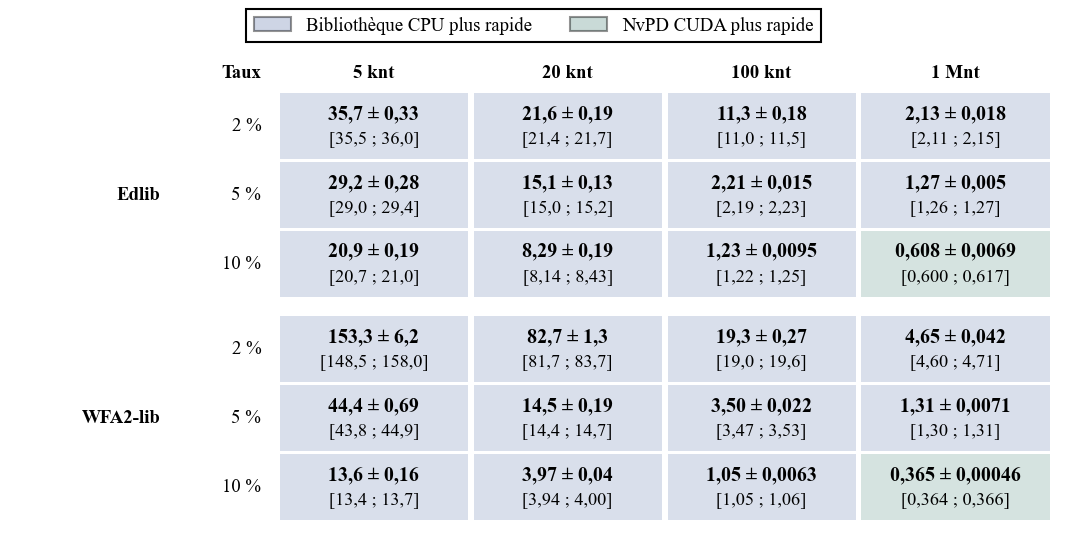

In [40]:
from studies.score_comparison import make_figure as sy_make_figure, paired_ratios as sy_paired_ratios

sy_ratios = sy_paired_ratios(nv_csv(RES / "repeated/gh200/trials.csv"))
sy_records = []
for (sy_length, sy_rate), sy_group in sy_ratios.groupby(["length", "rate"]):
    for sy_library in ["edlib", "wfa2"]:
        sy_stat = nv_stats.add(39, "nvpd_over_library", sy_library, f"{sy_length}nt_{sy_rate}pct",
                               sy_group[sy_library], "paired_process_block")
        sy_records.append(dict(library=sy_library, length=sy_length, rate=sy_rate, **sy_stat))
nv_save(sy_make_figure(sy_records), "comparison/synthese")

nv_stats.export(FIG / "statistics.csv")
ct_plot.montage(
    FIG,
    [
        ("comparison/temps_distance.png", "Coût du calcul de la distance globale"),
        ("cpu/echelle_cpu.png", "Passage à l’échelle sur un processeur"),
        ("cpu/openmp_un_million.png", "Anti-diagonales et lignes de grande largeur"),
        ("cpu/variantes_cpu.png", "Vectorisation de la récurrence de dernière occurrence"),
        ("cpu/geometrie_bande.png", "Géométrie des passages en bande"),
        ("cpu/nvpd_adaptatif.png", "Récurrence exacte à largeur adaptative"),
        ("cpu/memoire_cpu.png", "Occupation mémoire et défauts du cache de données"),
        ("cpu/lecture_fasta_chromosomes.png", "Décodage de fichiers FASTA de chromosomes entiers"),
        ("cpu/trace_lineaire.png", "Reconstruction de l’alignement en espace linéaire"),
        ("cpu/cout_instructions.png", "Instructions et prédictions de branchement"),
        ("gpu/variantes_gpu.png", "Regroupement des lignes en tuiles CUDA"),
        ("gpu/trace_cuda.png", "Chronologie des appels hôte et des noyaux CUDA"),
        ("gpu/localite_gpu.png", "Localité des lectures en mémoire globale"),
        ("gpu/roofline_gh200.png", "Débits entiers et modèle mémoire du GH200"),
        ("gpu/front_gpu.png", "Calcul par fronts de coût sur accélérateur"),
        ("gpu/allocations_cuda.png", "Réutilisation des tampons entre alignements"),
        ("distributed/portage_kokkos.png", "Portabilité de la récurrence avec Kokkos"),
        ("distributed/kokkos_humain.png", "Portabilité de NvPD sur deux régions homologues"),
        ("distributed/echelle_mpi.png", "Passage à l’échelle fort entre nœuds"),
        ("distributed/collectives_mpi.png", "Temps passé dans les échanges collectifs"),
        ("distributed/mpi_faible.png", "Passage à l’échelle faible entre nœuds"),
        ("distributed/echelle_mpi_humain.png", "Distribution de fenêtres chromosomiques"),
        ("distributed/ordonnancement.png", "Ordonnancement de paires de longueurs hétérogènes"),
        ("distributed/carte_paires.png", "Géométrie des partitions de Hilbert"),
        ("distributed/concentration_rangs.png", "Concentration du travail entre rangs"),
        ("distributed/travailleurs_kokkos.png", "Exécution des paires avec Kokkos"),
        ("biology/chromosome21.png", "Distances entre assemblages d’un chromosome humain"),
        ("biology/chromosomes_entiers.png", "Comparaison de chromosomes humains entiers"),
        ("biology/cohorte_chromosomes.png", "Distances sur un panel de chromosomes entiers"),
        ("biology/paysage_chromosomique.png", "Localisation des révisions de l’assemblage humain"),
        ("comparison/methodes_exactes.png", "Méthodes exactes sensibles à la distance"),
        ("comparison/biwfa_humain.png", "Reconstruction par fronts bidirectionnels"),
        ("comparison/bras_chromosome_biwfa.png", "Alignement de fenêtres emboîtées du bras long"),
        ("comparison/trace_chromosomes.png", "Reconstruction parallèle du chemin sur chromosomes entiers"),
        ("comparison/quicked.png", "Justesse et coût de la certification de QuickEd"),
        ("biology/phylogenie.png", "Structure des distances entre génomes de phages"),
        ("biology/phylogenie_surveillance.png", "Concordance avec les groupes de surveillance"),
        ("biology/sensibilite_arbres.png", "Sensibilité de la topologie à la largeur de bande"),
        ("comparison/synthese.png", "Conclusion et critères de choix"),
    ],
)

*Figure 39.* Chaque case donne la moyenne des rapports NvPD/bibliothèque ± l’écart-type, puis l’IC à 95 % entre crochets. Chaque méthode s’exécute après chauffe dans neuf blocs à 5 et 20 knt et cinq blocs à 100 knt et 1 Mnt. Un rapport inférieur à un favorise NvPD sur GPU.

<sub>Code : [python/studies/score_comparison.py](../python/studies/score_comparison.py), [results/repeated/gh200/trials.csv](../results/repeated/gh200/trials.csv).</sub>

À 10 % d’éditions injectées, le rapport NvPD/WFA2 passe de 1,054 à 100 knt à 0,365 à 1 Mnt. Le second cas est le seul des douze où NvPD devance aussi Edlib. Pour estimer un seuil de divergence, il faudrait plusieurs paires indépendantes à longueur et taux fixés.

Pour une collection, le produit des deux longueurs prédit le travail du solveur dense. La [distribution par rang](#concentration-rangs) montre comment exploiter cette information. Une méthode en bande demande une autre estimation du travail, car elle ne visite qu’une partie des colonnes. Lorsque la sortie est un arbre, une erreur de score peut conserver ou modifier une partition, comme le montre la [comparaison des topologies](#sensibilite-arbres).

<p><strong><u>Synthèse.</u></strong> À 1 Mnt et 10 %, NvPD sur GH200 prend 36,5 % du temps de WFA2 et 60,8 % de celui d’Edlib sur un cœur Grace.<br>Aux deux autres taux mesurés à cette longueur, les deux bibliothèques terminent avant NvPD.</p>